# Lab 1, teaching version: a simple EEG preprocessing pipeline, step by step
### Lexical decision while walking (Brain Walk project), participant P010

**PSY2007D, 2026.** This notebook teaches the basic steps of EEG preprocessing on real data: one participant doing a lexical
decision task while walking on a treadmill, and one recording of walking without the task.

**The task.** A string of letters appears for 100 ms at the centre of a tablet. The participant decides as fast as possible whether it is
a French word, and taps one side of the screen for "word" and the other side for "not a word". There are three kinds of strings:

- **HF**: high-frequency words, which are familiar (e.g. *excès*)
- **LF**: low-frequency words, which are rarer (e.g. *lièvre*)
- **pseudoword**: strings that follow French spelling rules but are not words (e.g. *assous*)

The participant did 4 blocks of 100 trials while walking (25 HF, 25 LF and 50 pseudowords per block, a new string every 2 to 3 s).

**The EEG.** A DSI-24 headset with dry electrodes (no gel): 19 electrodes, 300 samples per second (300 Hz).

**This version.** The pipeline and its parameters are those of the seated notebook (`00_preprocessing_teaching_seated.ipynb`), unchanged.
Walking adds artifacts of its own at every step; the steps that deal with them will come later.

## How to use this notebook

Run the cells in order (Shift+Enter).

| Step | What | Main function |
|---|---|---|
| 1 | Load and look at the data | `mne.io.read_raw_brainvision` |
| 2 | Find the bad channels and the suspicious periods | a robust amplitude, `raw.info['bads']`, `QC_` annotations |
| 3 | Filter, and remove the muscle activity spread over the scalp | `raw.filter`, Auto-CCA (BSS-CCA) |
| 4 | Re-reference to the average | `raw.set_eeg_reference` |
| 5 | Prepare the data used to train ICA | `raw.filter`, `BAD_ICA_` annotations |
| 6 | ICA: find the eye and muscle components | `mne.preprocessing.ICA`, ICLabel, `ica.find_bads_eog`, `ica.find_bads_muscle` |
| 7 | Remove those components | `ica.apply` |
| 8 | Check the data after ICA, mark what stays unusable | `BAD_final_` annotations |
| 9 | Epochs and ERPs, before and after cleaning | `mne.Epochs`, `mne.viz.plot_compare_evokeds` |

## 0. Setup

In [1]:
# ---- 0.1 The data and the packages: downloaded once, into tasks/brainwalk next to the notebook ----------------------------------
import sys                                                   # to know whether the notebook runs in Google Colab
import zipfile                                               # to unzip the data
import urllib.request                                        # to download the data
import importlib.util                                        # to check which packages are installed
from pathlib import Path                                     # to write file paths
import hashlib                                               # to recognize the version of the data

# The packages this notebook needs (import name: name to install). The missing ones are installed the first time.
PACKAGES = {'mne': 'mne', 'picard': 'python-picard',
            'mne_icalabel': 'mne-icalabel', 'onnxruntime': 'onnxruntime'}
missing = [name for module, name in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    to_install = ' '.join(missing)
    print('Installing', to_install, '(about one minute)')
    %pip install -q {to_install}

DATA_DIR = Path('tasks/brainwalk')                           # do not change: the data, in tasks/ next to the notebook
DRIVE_ID = '19nnPiRuypz5fCPISybipdjxeop2EA_P8'               # do not change: the file labo1_donnees_2026.zip on Google Drive
FINGERPRINT = 'b1bb8546761ec47c'                             # do not change: the fingerprint of manifest.json in this version of the data


def data_up_to_date():
    """True if DATA_DIR contains this version of the data (the fingerprint of its manifest.json file)."""
    manifest = DATA_DIR / 'manifest.json'
    return manifest.exists() and hashlib.sha256(manifest.read_bytes()).hexdigest()[:16] == FINGERPRINT


def progress(blocks, block_size, total):
    """Prints the progress of the download, every 10 %."""
    if total > 0 and blocks * block_size * 10 // total > (blocks - 1) * block_size * 10 // total:
        print(f'  {min(100, 100 * blocks * block_size // total)} %')


if not data_up_to_date():                                    # missing, or an older version: we download them (855 MB)
    archive = DATA_DIR.parent / 'labo1_donnees_2026.zip'
    archive.parent.mkdir(parents=True, exist_ok=True)
    print('Downloading the data from Google Drive (855 MB, a few minutes):')
    urllib.request.urlretrieve(f'https://drive.usercontent.google.com/download?id={DRIVE_ID}&export=download&confirm=t', archive, progress)
    if not zipfile.is_zipfile(archive):                      # Google Drive sent a web page instead of the file
        archive.unlink()
        raise RuntimeError('Google Drive did not send the data (too many downloads today?). Try again later.')
    with zipfile.ZipFile(archive) as z:
        z.extractall(DATA_DIR.parent)                        # creates tasks/brainwalk/
    archive.unlink()                                         # the zip is no longer needed
print('Data:', DATA_DIR, '(ready)' if data_up_to_date() else '(NOT FOUND: rerun this cell)')

Data: tasks\brainwalk (ready)


In [2]:
# ---- 0.2 The tools -----------------------------------------------------------------------------------------------------------------
import json                                                  # to save a summary of the results
import numpy as np                                           # arrays and maths
import pandas as pd                                          # tables
import matplotlib.pyplot as plt                              # figures
from matplotlib import animation                             # animated figures
from matplotlib.patches import FancyBboxPatch                # the boxes of the pipeline map
from scipy.stats import kurtosis                             # used by the ICA demonstration (step 6)
from IPython.display import HTML, display                    # to show tables and animations in the notebook
import mne                                                   # MNE-Python: the EEG toolbox
from mne_icalabel.iclabel import iclabel_label_components    # ICLabel: what kind of source is each ICA component?

%matplotlib inline
mne.set_log_level('ERROR')                                   # MNE prints only errors (try 'INFO' to see what each function does)
mne.viz.set_browser_backend('matplotlib')                    # raw.plot() draws a picture inside the notebook
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False, 'animation.embed_limit': 40})
import mne_icalabel, picard
for module in (mne, mne_icalabel, picard, np):
    print(f'{module.__name__:13s} {module.__version__}')

mne           1.13.2
mne_icalabel  0.10.0
picard        0.8.2
numpy         2.5.3


In [3]:
# ---- 0.3 The parameters we use in the pipeline --------------------------------------------------------------

SUBJECT = 'P010'                 # the participant whose data we analyze (P001, P002, ..., P010)
# Step 2: bad channels. Flat below FLAT_RATIO and noisy above NOISY_RATIO × the typical amplitude (the median across channels)
FLAT_RATIO = 0.1
NOISY_RATIO = 3.0
FLAT_SD_UV = 1.0                 # a channel is also flat if its standard deviation is below this (µV): the rule of cell 1.2 and of NEAR
MAX_BAD = 3                      # more bad channels than this (about one fifth of the 18 recorded): look at the recording before going on
QC_WINDOW_S = 5.0                # the windows of the quality check (s; cells 2.4, 2.5 and 8.1)
QC_RATIO = 3.0                   # suspicious: a channel above this × the typical amplitude of its window, or a window above this ×
                                 # the typical window of its recording (QC annotation, cell 2.5); a channel below FLAT_RATIO: lost contact

# Step 3: filters (Hz), and Auto-CCA (cell 3.8)
ANALYSIS_BAND = (0.1, 100.0)     # the data we analyze: keeps the slow ERPs (N400, late positivity) and the muscle activity ICLabel needs
ICA_BAND = (1.0, 100.0)          # only at step 5, for the copy that trains ICA: no slow drifts, which ICA handles badly
CCA_WINDOW_S = 10.0              # Auto-CCA works in windows of this length (s), which overlap by half
CCA_SLOPE_BAND = (7.0, 75.0)     # the slope of the spectrum of each CCA component is measured in this band (Hz)
CCA_SLOPE = 0.0                  # remove a CCA component whose slope is above this: its power does not fall with frequency, like a
                                 # muscle. Janani et al. (2018) used -0.48 with 115 electrodes; on P010's seated data it also removed the alpha

# Step 5: the data used to train ICA
ICA_HOLDOUT_RATIO = 5.0          # left out of ICA training (BAD_ICA_, cell 5.1): a QC period above this × the typical amplitude, and
                                 # every QC_contact or whole-scalp period

# Step 6: ICA
ICA_METHOD = 'picard'            # a fast ICA algorithm 
ICA_FIT_PARAMS = dict(ortho=False, extended=True)   # Picard set up like extended Infomax, the algorithm ICLabel was built with
ICA_SEED = 97                    # fixes the random start, so ICA gives the same result every time
# The decision (cell 6.7): a component is removed when two pieces of evidence of the same kind agree
ICLABEL_P = 0.5                  # ICLabel votes "eye" or "muscle" if it gives that class at least this probability
EYE_CORR = 0.5                   # an eye proxy (Fp1, Fp2, HEOG = F7 - F8) votes "eye" if |correlation| is at least this (1-10 Hz)
MUSCLE_SCORE = 0.5               # MNE's muscle score votes "muscle" from this value (MNE's own default, 0.125, also flags brain here)
BRAIN_CAUTION = 0.3              # ICLabel gives at least this probability of "brain": never removed automatically, only reviewed

# Step 9: epochs and ERPs
TMIN, TMAX = -0.2, 0.8           # the window around each word (s)
BASELINE = (-0.2, 0.0)           # the period before the word whose mean is subtracted from each epoch (s)
ERP_BAND = (0.1, 40.0)           # the band of the ERPs, before and after cleaning (Hz)
KEEP_CORRECT_ONLY = True         # ERPs from correct trials only
MAX_TONE_MS = 5.0                # keep a word only if its own tone confirms its onset within this (ms)
# Each component: its time window (s) and the electrodes averaged. They come from the Brain Walk group analyses, not from this
# participant: the P2 where the P2 of the group is clearest (cluster analysis); the N400 and the LPC on the symmetric centro-parietal
# region of the COSYNE abstract, whose pairs (C3 and C4, P3 and P4) cancel the motor potential of the hand that answers
COMPONENTS = {
    'P2': dict(window=(0.14, 0.22), region=['F3', 'Fz', 'F4', 'C3', 'Cz', 'C4']),
    'N400': dict(window=(0.30, 0.50), region=['C3', 'Cz', 'C4', 'P3', 'Pz', 'P4']),
    'LPC': dict(window=(0.45, 0.80), region=['C3', 'Cz', 'C4', 'P3', 'Pz', 'P4']),   # the late positivity
}
CONDITIONS = {'word/HF': 'tab:blue', 'word/LF': 'tab:green', 'pseudoword': 'tab:red'}   # condition: colour in the figures

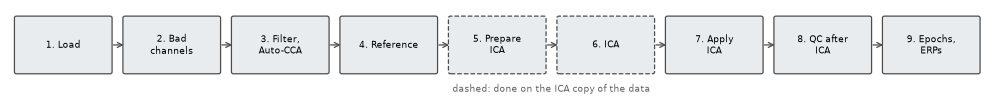

In [4]:
# ---- 0.4 Two helpers for the figures -----------------------------------------------------------------------------------------------
STEPS = ['Load', 'Bad\nchannels', 'Filter,\nAuto-CCA', 'Reference', 'Prepare\nICA', 'ICA', 'Apply\nICA',
         'QC after\nICA', 'Epochs,\nERPs']


def pipeline_map(step):
    """Draws the steps of the pipeline: the current step in orange, the steps already done in green."""
    fig, ax = plt.subplots(figsize=(14, 1.3))
    for i, label in enumerate(STEPS, start=1):
        color = '#f4a261' if i == step else '#b7e4c7' if i < step else '#e9ecef'
        ax.add_patch(FancyBboxPatch((i - 0.43, 0.3), 0.86, 0.6, boxstyle='round,pad=0.02', fc=color, ec='0.3',
                                    ls='--' if i in (5, 6) else '-'))
        ax.text(i, 0.6, f'{i}. {label}', ha='center', va='center', fontsize=7.5, weight='bold' if i == step else 'normal')
        if i < len(STEPS):
            ax.annotate('', xy=(i + 0.58, 0.6), xytext=(i + 0.44, 0.6), arrowprops=dict(arrowstyle='->', color='0.3'))
    ax.text(5.5, 0.08, 'dashed: done on the ICA copy of the data', ha='center', fontsize=7, color='0.4')
    ax.set(xlim=(0.5, len(STEPS) + 0.5), ylim=(0, 1))
    ax.axis('off')
    plt.show()


def show_animation(fig, anim, dpi=72):
    """Shows a matplotlib animation in the notebook, with play and pause buttons."""
    plt.close(fig)                                           # no extra still picture
    fig.set_dpi(dpi)                                         # small frames keep the notebook light
    with plt.rc_context({'animation.frame_format': 'jpeg'}):
        display(HTML(anim.to_jshtml(default_mode='once')))


pipeline_map(0)

## 1. Load and look at the data

**What.** Read the five walking recordings of the participant: walking without the task, then the 4 task blocks.

**Why.** Before changing anything, look at the raw data. You need to know the problems before you fix them.

**The BIDS format.** The data follow BIDS, the Brain Imaging Data Structure (Pernet et al., 2019): a standard way to name and organize
files. The file name says what the file contains:

`sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.vhdr`

= participant P010, session 1, task LexicalDecision, acquisition "walking block 1", run 1, EEG data. Each recording has six files:

| File | Contains |
|---|---|
| `_eeg.vhdr`, `_eeg.vmrk`, `_eeg.eeg` | the signal, in the BrainVision format (header, markers, data) |
| `_eeg.json` | a description of the recording (device, reference, sampling rate...) |
| `_channels.tsv` | one row per channel (name, type, status) |
| `_events.tsv` | one row per event (each word, each response) with its time and details |

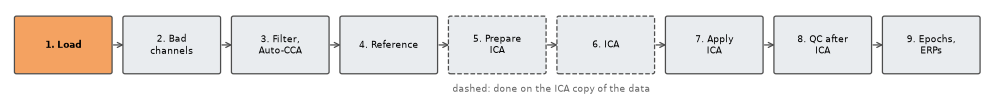

In [5]:
pipeline_map(1)

In [5]:
# ---- 1.1 The walking recordings of this participant (five for P010) --------------------------------------------------------------
EEG_DIR = DATA_DIR / 'bids' / f'sub-{SUBJECT}' / 'ses-001' / 'eeg'
LABELS = {                                                   # our short name: the task and acquisition labels in the BIDS file name
    'walk_only': 'task-WalkingOnly_acq-walking',              # walking on the treadmill, without the task
    'block1': 'task-LexicalDecision_acq-walkingBlock01',
    'block2': 'task-LexicalDecision_acq-walkingBlock02',
    'block3': 'task-LexicalDecision_acq-walkingBlock03',
    'block4': 'task-LexicalDecision_acq-walkingBlock04',
}


def bids_file(name, suffix):
    """The path of one BIDS file of a recording, for example bids_file('block1', 'events.tsv'), or None if it does not exist. The run
    number is usually 01; a recording restarted after a problem gets the next one, and we take the last."""
    return max(EEG_DIR.glob(f'sub-{SUBJECT}_ses-001_{LABELS[name]}_run-*_{suffix}'), default=None)


RECORDINGS = [name for name in LABELS if bids_file(name, 'eeg.vhdr')]   # the recordings this participant has
BLOCKS = [name for name in RECORDINGS if name.startswith('block')]
FIRST_BLOCK = BLOCKS[0]                                      # the block that the figures of steps 1 to 3 show
print('Missing for this participant:', ', '.join(name for name in LABELS if name not in RECORDINGS) or 'nothing')
print(f'The files of {FIRST_BLOCK}:')
for f in sorted(EEG_DIR.glob(f'*{LABELS[FIRST_BLOCK]}*')):
    print(f'  {f.name:80s} {f.stat().st_size / 1e6:6.2f} MB')

Missing for this participant: nothing
The files of block1:
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_channels.tsv       0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.eeg            7.18 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.json           0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.vhdr           0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_eeg.vmrk           0.00 MB
  sub-P010_ses-001_task-LexicalDecision_acq-walkingBlock01_run-01_events.tsv         0.04 MB


In [6]:
# ---- 1.2 What the dataset says about the recording and the channels ---------------------------------------------------------------
sidecar = json.loads(bids_file(FIRST_BLOCK, 'eeg.json').read_text(encoding='utf-8'))    # the _eeg.json file
print('Device:       ', sidecar['ManufacturersModelName'], '-', sidecar['CapManufacturersModelName'])
print('Sampling rate:', sidecar['SamplingFrequency'], 'Hz')
print('Reference:    ', sidecar['EEGReference'])
channels = pd.read_csv(bids_file(FIRST_BLOCK, 'channels.tsv'), sep='\t')                 # the _channels.tsv file
channels[['name', 'type', 'status', 'status_description', 'description']]

Device:        DSI-24 - DSI-24 dry-electrode headset
Sampling rate: 300.0 Hz
Reference:     Pz (online hardware reference). Every scalp channel is recorded as (channel - Pz); Pz is kept as an all-zero EEG channel so that an average reference over the EEG channels reconstructs it. A1/A2 (ear clips) and CM are typed MISC.


,name,type,status,status_description,description
0,P3,EEG,good,NaN,NaN
1,C3,EEG,good,NaN,NaN
2,F3,EEG,good,NaN,NaN
3,Fz,EEG,good,NaN,NaN
4,F4,EEG,good,NaN,NaN
5,C4,EEG,good,NaN,NaN
6,P4,EEG,good,NaN,NaN
7,Cz,EEG,good,NaN,NaN
8,CM,MISC,good,NaN,DSI common-mode sensor
9,A1,MISC,good,NaN,left ear clip


**Look.** 19 channels are EEG. The reference sensor of the DSI-24 sits at **Pz**, and the headset records every channel as (channel − Pz):
its file names them `EEG P3-Pz`, `EEG C3-Pz`... The conversion to BIDS kept `P3`, `C3`... and renamed the old 10-20 names T3, T4, T5, T6
to T7, T8, P7, P8. Pz itself is Pz − Pz = 0, all zeros: the conversion kept it as an EEG channel, so that the average reference of step 4
can give it its own signal back. Four channels are not EEG: `A1` and `A2` (clips on the ear lobes), `CM` (the voltage common to the whole
body, which the reference sensor measures) and `Trigger` (the event signals). The dataset already flags `P7` as flat: its sensor does not
work. We will check all channels ourselves at step 2.

In [7]:
# ---- 1.3 Read the recordings --------------------------------------------------------------------------------------------------
raws, events = {}, {}
for name in RECORDINGS:
    raw = mne.io.read_raw_brainvision(bids_file(name, 'eeg.vhdr'), preload=True)   # the signal, in volts; preload: into memory
    raw.set_channel_types({'CM': 'misc', 'A1': 'misc', 'A2': 'misc', 'Trigger': 'stim'})   # only the 19 scalp channels are EEG
    raw.set_montage('standard_1020')                         # the position of each electrode on the head (10-20 system)
    raws[name] = raw
    events[name] = pd.read_csv(bids_file(name, 'events.tsv'), sep='\t', na_values='n/a')   # one row per event
    print(f'{name:10s} {raw.times[-1] / 60:4.1f} min, {raw.info["sfreq"]:.0f} Hz, '
          f'{(events[name]["trial_type"] == "stimulus").sum():3d} words')
raws[FIRST_BLOCK].info                                       # the description MNE keeps with the data

walk_only   6.4 min, 300 Hz,   0 words
block1      4.3 min, 300 Hz, 100 words
block2      4.0 min, 300 Hz,  93 words
block3      3.6 min, 300 Hz,  88 words
block4      4.3 min, 300 Hz, 100 words


<Info | 8 non-empty values
 bads: []
 ch_names: P3, C3, F3, Fz, F4, C4, P4, Cz, CM, A1, Fp1, Fp2, T7, P7, O1, ...
 chs: 19 EEG, 3 misc, 1 Stimulus
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 150.0 Hz
 meas_date: unspecified
 nchan: 23
 projs: []
 sfreq: 300.0 Hz
>

**How.** `mne.io.read_raw_brainvision(path, preload=True)` reads a BrainVision file and returns a `Raw` object: the signal (channels ×
samples, in volts) and its description `raw.info` (channel names and types, sampling rate, bad channels...). `raw.set_channel_types`
tells MNE which channels are EEG, and `raw.set_montage` gives each electrode its position on the head, which topographic maps and
interpolation need.

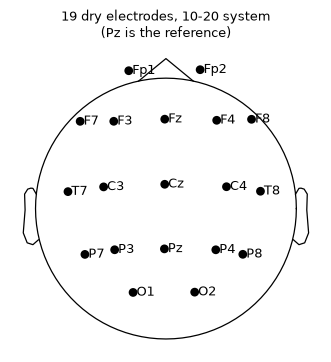

In [9]:
# ---- 1.4 Where the electrodes are -------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(4.5, 4.5))
raws[FIRST_BLOCK].plot_sensors(show_names=True, axes=ax, show=False)
ax.set_title('19 dry electrodes, 10-20 system\n(Pz is the reference)', fontsize=10)
plt.show()

**The 10-20 system.** The letter gives the region: Fp frontopolar, F frontal, C central, T temporal, P parietal, O occipital. Odd numbers are
on the left, even numbers on the right, and z is the midline. Seen from above, the nose is at the top.

In [8]:
# ---- 1.5 The events: one row per word and one per response ------------------------------------------------------------------------
columns = ['onset', 'trial_type', 'stimulus', 'lexicality', 'frequency_class', 'accuracy', 'response_time']
display(events[FIRST_BLOCK][columns].head(7))
words = pd.concat([events[b][events[b]['trial_type'] == 'stimulus'] for b in BLOCKS])   # the 400 words of the 4 blocks
behaviour = words.groupby('frequency_class').agg(trials=('stimulus', 'size'), accuracy=('accuracy', 'mean'),
                                                 median_rt_s=('response_time', 'median'))
behaviour.round(3)

,onset,trial_type,stimulus,lexicality,frequency_class,accuracy,response_time
0,5.033333,recording_start,NaN,NaN,NaN,NaN,NaN
1,7.391411,stimulus,émier,pseudoword,pseudoword,0.0,0.6938
2,8.085211,response,NaN,NaN,NaN,0.0,0.6938
3,9.832668,stimulus,émergé,word,high,1.0,0.8439
4,10.676568,response,NaN,NaN,NaN,1.0,0.8439
5,12.475021,stimulus,nourel,pseudoword,pseudoword,1.0,0.7680
6,13.243021,response,NaN,NaN,NaN,1.0,0.7680


,trials,accuracy,median_rt_s
frequency_class,,,
high,93,0.968,0.698
low,99,0.773,0.814
pseudoword,189,0.851,0.952


**Look.** `onset` is the time in the recording (s), `accuracy` is 1 for a correct answer, and `response_time` is the reaction time (s).
The behaviour already tells a story: frequent words are recognized faster than rare words, and both faster than pseudowords. Accuracy
is high for frequent words (97 %) and lower for rare words (77 %). There are 381 words instead of 400: the recording of block 2 stops
after its 93rd word, and block 3 has 88, with three gaps of about 15 s in its signal (cell 1.9).

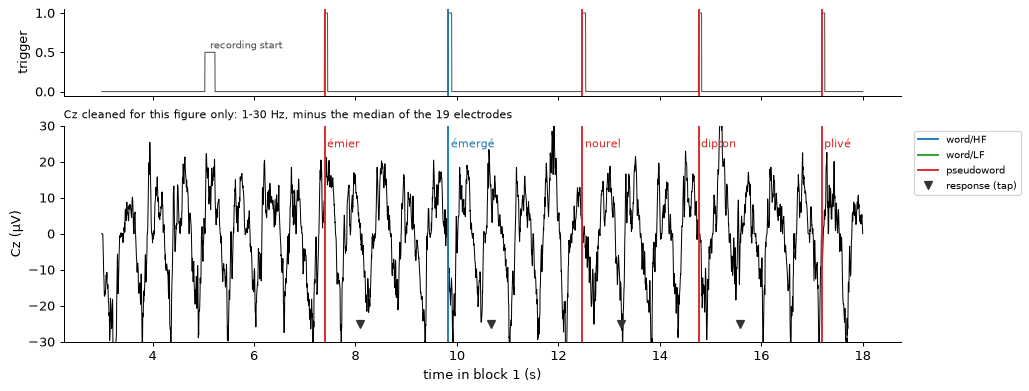

In [9]:
# ---- 1.6 One trial after another: the word onsets, the responses and the trigger channel --------------------------------------------
start, stop = 3, 18                                          # the seconds of the first block we show
piece = raws[FIRST_BLOCK].copy().crop(start, stop)
eeg = piece.copy().pick('eeg').filter(1, 30)                 # the 19 electrodes, filtered only to make the figure readable
# Cz in µV minus a virtual median reference, the median of the 19 electrodes at each sample: cancels the Pz reference of every channel
cz = (eeg.get_data(picks='Cz')[0] - np.median(eeg.get_data(), axis=0)) * 1e6
trigger = piece.get_data(picks='Trigger')[0]
ev = events[FIRST_BLOCK][(events[FIRST_BLOCK]['onset'] >= start) & (events[FIRST_BLOCK]['onset'] <= stop)]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.8), sharex=True, height_ratios=[1, 2.5])
ax1.plot(piece.times + start, trigger / trigger.max(), color='0.3', lw=0.8)
ax2.plot(piece.times + start, cz, color='k', lw=0.8)
for _, row in ev.iterrows():
    if row['trial_type'] == 'stimulus':
        kind = 'pseudoword' if row['lexicality'] == 'pseudoword' else 'word/HF' if row['frequency_class'] == 'high' else 'word/LF'
        for ax in (ax1, ax2):
            ax.axvline(row['onset'], color=CONDITIONS[kind], lw=1.5)
        ax2.text(row['onset'] + 0.05, 24, row['stimulus'], color=CONDITIONS[kind], fontsize=9)
    elif row['trial_type'] == 'response':
        ax2.plot(row['onset'], -25, 'v', color='0.2', ms=7)
    elif row['trial_type'] == 'recording_start':
        ax1.text(row['onset'] + 0.1, 0.55, 'recording start', fontsize=8, color='0.3')
ax1.set(ylabel='trigger')
ax2.set(xlabel=f'time in block {FIRST_BLOCK[-1]} (s)', ylabel='Cz (µV)', ylim=(-30, 30))
ax2.set_title('Cz cleaned for this figure only: 1-30 Hz, minus the median of the 19 electrodes', fontsize=9, loc='left')
for kind, color in CONDITIONS.items():
    ax2.plot([], [], color=color, label=kind)
ax2.plot([], [], 'v', color='0.2', label='response (tap)')
ax2.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
plt.show()


**Look.** Four things to see in these 15 seconds of the first block:

1. **The trigger channel (top).** The tablet played a short tone at each word into the trigger channel of the EEG, so each pulse is one
   tone. The first, smaller pulse marks the start of the recording.
2. **The coloured lines** are the word onsets, one colour per condition. An onset is the moment the tablet drew the word, converted to
   EEG time with the help of the tones, so each pulse starts within a few milliseconds of its line. This is how the EEG and the task
   are synchronized.
3. **The triangles** are the taps. The EEG has no trigger for them: each tap is placed at the word onset plus the reaction time
   measured by the tablet (0.7 to 0.85 s here, the `response_time` column of cell 1.5).
4. **Cz (bottom)** is dominated by a regular wave of about ±25 µV, almost two per second: the steps (cell 1.7). An ERP is a few µV,
   much smaller than this, so we will need to average many trials (step 9). This Cz is cleaned for this figure only (1–30 Hz, minus the
   median of the 19 electrodes at each sample, a virtual median reference that cancels the Pz reference every channel carries; step 2
   explains it). The raw signal is much noisier (cell 1.7).

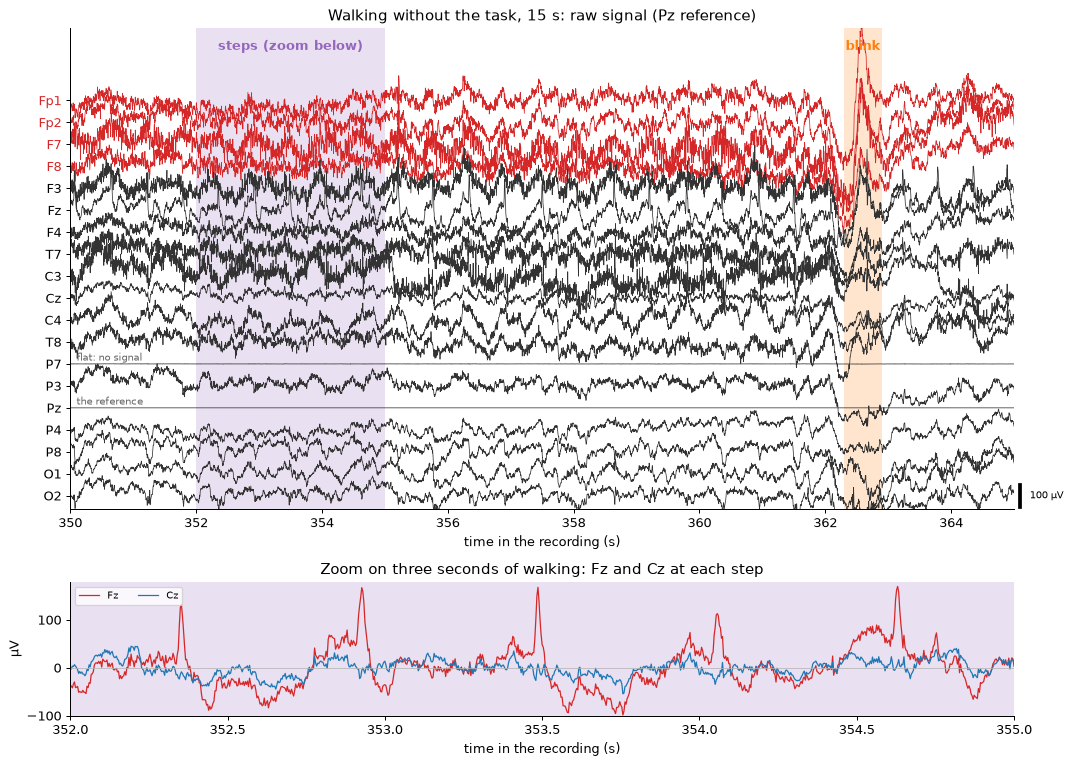

In [10]:
# ---- 1.7 The raw signal while walking: the steps and an eye blink (15 s of walking without the task) ------------------------------------
start, stop = 350, 365                                       # the seconds of the walk we show
eye = ['Fp1', 'Fp2', 'F7', 'F8']                             # the four electrodes closest to the eyes
order = eye + ['F3', 'Fz', 'F4', 'T7', 'C3', 'Cz', 'C4', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'O2']   # the eyes first, then front to back
# the steps of the zoom and the blink of this piece (start, end, name, colour, side of the span where the name is written)
marks = [(352.0, 355.0, 'steps (zoom below)', 'tab:purple', 'center'),
         (362.3, 362.9, 'blink', 'tab:orange', 'center')]
piece = raws['walk_only'].copy().pick('eeg').crop(start, stop)
times = piece.times + start
data = piece.get_data(picks=order) * 1e6                     # the raw signal (Pz reference) in µV
data -= data.mean(axis=1, keepdims=True)                     # each channel around its own mean, as raw.plot() does

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8.6), height_ratios=[4.3, 1.2])
gap = 100                                                    # µV between two channels
for k, (name, y) in enumerate(zip(order, data)):
    ax1.plot(times, y - k * gap, lw=0.6, color='tab:red' if name in eye else '0.2')
ax1.set(yticks=[-k * gap for k in range(len(order))], yticklabels=order, xlim=(start, stop), ylim=(-len(order) * gap + 40, 330),
        xlabel='time in the recording (s)', title='Walking without the task, 15 s: raw signal (Pz reference)')
for label in ax1.get_yticklabels():
    label.set_color('tab:red' if label.get_text() in eye else 'k')
for name, text in (('P7', 'flat: no signal'), ('Pz', 'the reference')):
    ax1.text(start + 0.1, -order.index(name) * gap + 15, text, fontsize=8, color='0.4')
ax1.plot([stop + 0.1] * 2, [-17.5 * gap, -18.5 * gap], color='k', lw=3, clip_on=False)      # the scale bar
ax1.text(stop + 0.25, -18 * gap, '100 µV', va='center', fontsize=8)

zoom = (times >= 352.0) & (times <= 355.0)                   # three seconds of steps, enlarged: Fz and Cz, around their mean
for name, color in (('Fz', 'tab:red'), ('Cz', 'tab:blue')):
    y = data[order.index(name)]
    ax2.plot(times[zoom], (y - y[zoom].mean())[zoom], color=color, lw=1, label=name)
ax2.set(xlim=(352.0, 355.0), ylim=(-100, 180), xlabel='time in the recording (s)', ylabel='µV',
        title='Zoom on three seconds of walking: Fz and Cz at each step')
ax2.axhline(0, color='0.7', lw=0.6)
ax2.legend(loc='upper left', ncol=2, fontsize=8)

for t0, t1, label, color, side in marks:
    for ax in (ax1, ax2):
        ax.axvspan(t0, t1, color=color, alpha=0.2, lw=0)
    x = {'center': (t0 + t1) / 2, 'right': t0 - 0.05, 'left': t1 + 0.05}[side]
    ax1.text(x, 0.975, label, color=color, ha=side, va='top', weight='bold', transform=ax1.get_xaxis_transform())
plt.tight_layout()
plt.show()


**Look.** This is the raw signal (no filter, Pz reference) of 15 seconds of walking without the task, from the front of the head to the
back. The four electrodes closest to the eyes (Fp1, Fp2, F7, F8) are in red.

1. **The steps** (purple, zoom below). Every channel moves with a rhythm of almost two waves per second: the participant takes about
   1.8 steps per second (the heel contacts measured in the Brain Walk project are 0.56 s apart in this recording). Each step shakes the
   electrodes and their cables. At Fz it gives a sharp peak of 100 to 170 µV at every step; at Cz, a slower wave of a few tens of µV.
2. **Eye blink** (362.6 s, orange). A sharp wave of about half a second on Fp1, Fp2, F7 and F8, which stands out above the steps at the
   front of the head.
3. **P7** is a flat line: its sensor does not work and gives the same voltage as the reference, so P7 − Pz = 0.
4. **Pz** is flat by construction: it is the reference, Pz − Pz = 0.

The steps are artifacts too, and they never stop: unlike a blink, they are in every trial. This notebook applies the seated pipeline to
them unchanged, to see what it does and does not remove (steps 6 to 9).

To scroll through a recording yourself, run `raws['walk_only'].plot()` on your own computer with an interactive backend (`%matplotlib
qt` or `%matplotlib widget`).

In [ ]:
%matplotlib qt
mne.viz.set_browser_backend('matplotlib')

fig = raws['walk_only'].plot(picks='eeg', start=100, duration=20, scalings=dict(eeg=100e-6))


### 1.9 Keep what we analyze, label the words, join the four blocks

- **Cut at the triggers**: keep each recording between its triggers. A block runs from the start pulse to the stop pulse of the headset
  hub, the walk without the task from its `walk_start` to its `walk_end` event (the events of cell 1.5). What comes before and after is not the task, and it can hold
  very strong artifacts. `raw.crop(tmin, tmax)` removes it from the data, so every later step sees only the part we keep. Marking it as
  `BAD` would not be enough: the filters and the blink detection do not skip `BAD` segments.
- **Task**: turn each word into an **annotation**, a label at a time in the recording. The label is the condition: `word/HF`, `word/LF`
  or `pseudoword`; the `/` lets us later select all words at once with `epochs['word']`. When the wireless link of the headset lost samples
  (`data_gap` in the events), we mark 2 s around it as `BAD_gap`: MNE ignores segments whose annotation starts with `BAD`.
- Then **join** the four blocks into one task recording with `mne.concatenate_raws`. MNE marks each junction with a `BAD boundary`
  annotation (no epoch may cross it) and an `EDGE boundary` (filters treat each block separately).

In [11]:
# ---- 1.9 Cut at the triggers, label the words and join the blocks ----------------------------------------------------------------
def condition_of(row):
    """word/HF, word/LF or pseudoword, from one row of an events.tsv file."""
    if row['lexicality'] == 'pseudoword':
        return 'pseudoword'
    return 'word/HF' if row['frequency_class'] == 'high' else 'word/LF'


def label_words(raw, ev):
    """A copy of raw whose annotations are the word onsets (named by condition) and the data gaps (BAD)."""
    raw = raw.copy()
    sfreq = raw.info['sfreq']
    stim = ev[ev['trial_type'] == 'stimulus']
    annotations = mne.Annotations(onset=stim['sample'] / sfreq, duration=0.0, description=list(stim.apply(condition_of, axis=1)))
    gaps = ev.loc[ev['trial_type'] == 'data_gap', 'sample'] / sfreq     # where the wireless link lost samples
    if len(gaps):
        annotations += mne.Annotations(onset=np.maximum(gaps - 1, 0), duration=2.0, description='BAD_gap')
    raw.set_annotations(annotations)
    return raw


def cut_at_triggers(raw, ev, first, last):
    """A copy of raw cut between two triggers of its events table (or at the start and end of the file, when a trigger is missing).
    crop() removes the rest from the data and moves the annotations with it."""
    start = ev.loc[ev['trial_type'] == first, 'onset']
    stop = ev.loc[ev['trial_type'] == last, 'onset']
    begin = start.iloc[0] if len(start) else 0.0
    end = min(stop.iloc[0], raw.times[-1]) if len(stop) else raw.times[-1]
    return raw.copy().crop(begin, end)


cut_raws = {}                                                # the five recordings, each cut between its triggers
for name in raws:
    if name in BLOCKS:                                       # a block: from the start pulse to the stop pulse of the hub, words labelled
        cut_raws[name] = cut_at_triggers(label_words(raws[name], events[name]), events[name], 'recording_start', 'recording_stop')
    else:                                                    # walking without the task: from the start to the end of the walk
        cut_raws[name] = cut_at_triggers(raws[name].copy().set_annotations(None), events[name], 'walk_start', 'walk_end')
    print(f'{name:9s} kept {cut_raws[name].times[-1]:4.0f} s of {raws[name].times[-1]:4.0f} s')

recordings = {}                                              # walking without the task, then the task (the blocks joined)
if 'walk_only' in cut_raws:
    recordings['walk_only'] = cut_raws['walk_only'].copy()
recordings['task'] = mne.concatenate_raws([cut_raws[b].copy() for b in BLOCKS])   # (this function changes the first recording it gets: we give copies)
trials = pd.concat([events[b][events[b]['trial_type'] == 'stimulus'] for b in BLOCKS], ignore_index=True)   # one row per word
trials['condition'] = trials.apply(condition_of, axis=1)
for name, raw in recordings.items():
    labels = pd.Series(raw.annotations.description).value_counts().to_dict()
    print(f'{name:10s} {raw.times[-1] / 60:5.1f} min   annotations: {labels if labels else "none"}')

walk_only kept  300 s of  384 s
block1    kept  252 s of  260 s
block2    kept  236 s of  238 s
block3    kept  214 s of  218 s
block4    kept  250 s of  258 s
walk_only    5.0 min   annotations: none
task        15.9 min   annotations: {'pseudoword': 189, 'word/LF': 99, 'word/HF': 93, 'BAD_gap': 5, 'BAD boundary': 3, 'EDGE boundary': 3}


## 2. Find the bad channels

**What.** Find the electrodes whose signal is not EEG: **flat** (no contact, broken electrode) or **noisy** (much larger than the others:
poor contact, an electrode that moves). Dry electrodes have more of these problems than gel electrodes. In three studies, 5.3 faulty
electrodes had to be interpolated on average with dry electrodes against 2.0 with gel (Kam et al., 2019), 16 % of the channels were bad
against 3 % (Fiedler et al., 2022), and 10.5 % of the data was rejected against 3.9 % (Heijs et al., 2021). We also write down the short periods when one channel, or the
whole scalp, looks suspicious (cell 2.5).

**Why now.** A bad channel spreads to every channel when we re-reference to the average (step 4) and it disturbs ICA (step 6). We mark
the bad channels now (`raw.info['bads']`), and they stay marked until the end: MNE leaves them out where it should (the average reference,
ICA, the rejection of epochs), and this notebook never rebuilds them from their neighbours (step 8 says why).

**How.** For each channel, measure its amplitude and compare it with the typical amplitude of the same recording: the median of the amplitudes of all the channels. Which measure of
amplitude? The usual one, the standard deviation, is pulled up by rare large events (a movement, a burst of muscle activity): they can
make a good channel look noisy. A **robust** measure, the median absolute deviation (MAD), ignores them. The order of the checks matters too. Flat
channels are looked for on the signal as it was recorded. Noisy channels are looked for after a temporary
**virtual median reference**, which cancels the Pz reference that every recorded channel carries (cell 2.2). It is a tool for the detection only: the
data keep the Pz reference until step 4.

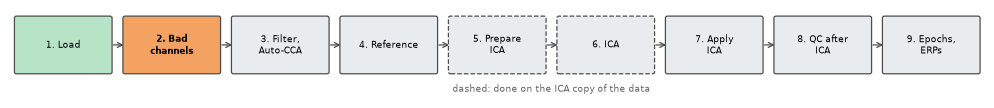

In [15]:
pipeline_map(2)

### Before we measure

Published pipelines prepare the data before they look for bad channels. We do the same here:

1. **Leave out what is not scalp EEG.** `A1`, `A2`, `CM` and `Trigger` are not EEG: we gave them other types when we loaded the data
   (cell 1.3).
2. **Measure on a copy filtered at 1–40 Hz.** Below 1 Hz, slow drifts (sweat, an electrode that moves) would dominate the amplitude of a
   channel, and above 40 Hz the 60 Hz of the electrical network would add to it. The recording itself stays unfiltered.
3. **Look for flat channels before changing the reference.** On the DSI-24, a sensor that does not work gives the same voltage as the
   reference, so its channel is Pz − Pz = 0: flat, like Pz itself (P7 here). A new reference subtracts the same signal from every
   channel, so it would turn a flat channel into a copy of the re-referenced Pz, which no longer looks flat. Flat channels are found
   first, on the signal as recorded, and set aside: they are not re-referenced, and they do not enter the median reference of item 4.
4. **Cancel the reference term that every channel carries before looking for noisy ones.** The reference sensor at Pz measures the voltage of the body
   against the headset's ground, which is large and common to the whole body (static, movements, the electrical network: the `CM`
   channel). The headset records every channel relative to that sensor, so this common voltage cancels (Wearable Sensing, 2023). What the
   subtraction puts into every channel, with a minus sign, is the activity under Pz: the EEG there and the noise of the Pz sensor. Before
   we look for noisy channels, a temporary virtual median reference cancels this term (cell 2.2).
5. **Cut each recording at its triggers.** Cell 1.9 keeps a block between the start pulse and the stop pulse of the headset hub, and the
   walk without the task between its `walk_start` and `walk_end` events. What comes before and after is not the task, and it can hold very strong artifacts that
   affect channel rejection and ICA (Klug et al., 2022).

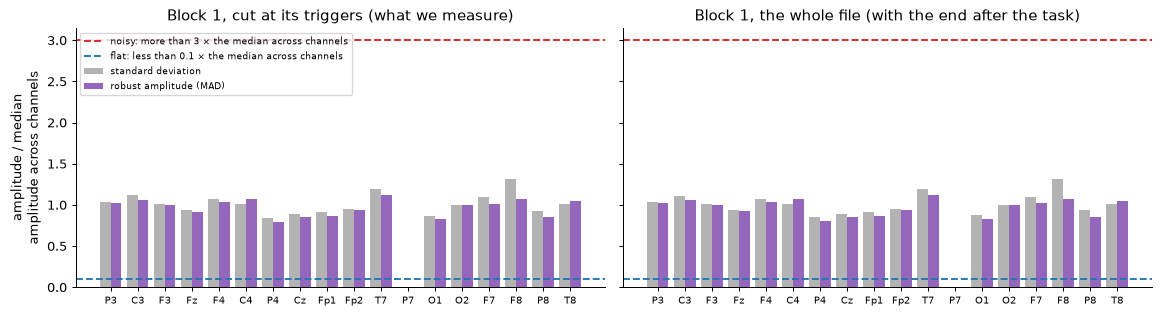

In [12]:
# ---- 2.1 Standard deviation or robust amplitude? ------------------------------------------------------------------------------------
def amplitudes(raw, reference_channels=None):
    """Standard deviation and robust amplitude (1.4826 x MAD) of each EEG channel except Pz (µV), on a 1-40 Hz copy of raw.
    reference_channels=None: the signal as recorded, every channel minus Pz. Otherwise, only to look for noisy channels: the temporary
    virtual median reference of cell 2.2 (at each sample, the median of reference_channels) is subtracted from reference_channels, and
    the other channels (the flat ones) are left out (NaN). raw itself is never changed."""
    eeg = raw.copy().pick('eeg').filter(1, 40)               # 1-40 Hz: ignore the slow drifts and the 60 Hz noise
    x = eeg.get_data() * 1e6                                  # as recorded: every channel minus Pz (µV)
    if reference_channels is not None:
        rows = [eeg.ch_names.index(ch) for ch in reference_channels]
        y = np.full_like(x, np.nan)                           # the channels outside reference_channels are left out
        y[rows] = x[rows] - np.median(x[rows], axis=0)        # each channel minus the sample-wise median reference
        x = y
    sd = x.std(axis=1)
    mad = 1.4826 * np.median(np.abs(x - np.median(x, axis=1, keepdims=True)), axis=1)   # equals the SD for Gaussian noise
    return pd.DataFrame({'sd': sd, 'robust': mad}, index=eeg.ch_names).drop(index='Pz')   # Pz, the reference, is not judged


fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, (title, raw) in zip(axes, [(f'Block {FIRST_BLOCK[-1]}, cut at its triggers (what we measure)', cut_raws[FIRST_BLOCK]),
                                   (f'Block {FIRST_BLOCK[-1]}, the whole file (with the end after the task)', raws[FIRST_BLOCK])]):
    ratio1 = amplitudes(raw)
    ratio1 = ratio1 / ratio1.median()                        # each channel / the median across channels, for each measure
    x = np.arange(len(ratio1))
    ax.bar(x - 0.2, ratio1['sd'], 0.4, color='0.7', label='standard deviation')
    ax.bar(x + 0.2, ratio1['robust'], 0.4, color='tab:purple', label='robust amplitude (MAD)')
    ax.axhline(NOISY_RATIO, color='tab:red', ls='--', label=f'noisy: more than {NOISY_RATIO:g} × the median across channels')
    ax.axhline(FLAT_RATIO, color='tab:blue', ls='--', label=f'flat: less than {FLAT_RATIO:g} × the median across channels')
    ax.set(xticks=x, xticklabels=ratio1.index, title=title)
    ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('amplitude / median\namplitude across channels')
axes[0].legend(fontsize=7.5, loc='upper left')
plt.tight_layout()
plt.show()

**Look.** Left: block 1 cut at its triggers. The standard deviation (grey) and the robust amplitude (purple) agree, and only **P7** stands
out, far below the flat line. Right: the whole file, with 5 s before the task and 3 s after it. In this block it changes almost nothing,
but the end of a recording can hold large bursts that push the standard deviation of a channel above the "noisy" line while its robust
amplitude stays normal. The mean and the standard deviation are moved by the very values they are meant to detect; the median and the MAD
are not (Leys et al., 2013). PREP's noisy-channel criterion is robust for the same reason: it "does not identify channels that capture
eye-blinks and most muscle activity as noisy" (Bigdely-Shamlo et al., 2015). Leys et al. recommend flagging the values beyond the median
± 2.5 MAD; we compare each channel with the typical amplitude, the median robust amplitude across channels, instead. We measure the
recordings cut at their triggers (cell 1.9): what comes before and after is not the task.

### A temporary virtual median reference, only to find noisy channels

The DSI-24 records every channel relative to Pz. With $V_i$ the voltage under electrode $i$:

$$x_i(t) = V_i(t) - V_{Pz}(t), \qquad \text{so the stored Pz channel is } V_{Pz} - V_{Pz} = 0.$$

Every recorded channel therefore contains the same term, $-V_{Pz}$. A large shared term makes the channels look alike, and can hide a
channel that is noisy on its own. To look for noisy channels, we cancel it with a **virtual median reference**. At each sample $t$, it is
the median of the usable channels: the EEG channels except Pz and the flat channels found on the signal as recorded. There is no median
electrode: this reference is computed, not recorded.

$$m(t) = \operatorname{median}_i \, x_i(t) = \operatorname{median}_i V_i(t) - V_{Pz}(t)$$

$$y_i(t) = x_i(t) - m(t) = V_i(t) - \operatorname{median}_i V_i(t)$$

The median contains the same $-V_{Pz}$ term as every channel, so the subtraction cancels the Pz reference. Unlike a mean, a median is not
pulled by one or two extreme channels, so a noisy electrode barely changes the reference it is compared with. Pz becomes
$y_{Pz}(t) = V_{Pz}(t) - \operatorname{median}_i V_i(t)$: Pz **relative to the virtual reference**, not a recovered absolute voltage of Pz
(a voltage is always a difference between two points, step 4).

Two different medians are used in this step:

- the **sample-wise median reference** $m(t)$: at each sample, the median of the channel values. It is a signal.
- the **typical amplitude**: the median of the robust amplitudes of the channels, one number per recording. The flat and noisy thresholds
  are multiples of it.

**For detection only.** The median reference is computed on 1–40 Hz copies and never changes the data. Once the bad channels are found
(cell 2.4), they are stored in `raw.info['bads']`, and the next steps use the recordings as they are, still referenced to Pz. The real
reference comes at step 4: the average of the good channels, Pz included with its zeros. The idea of a median as a robust first estimate of
the reference comes from the robust referencing of PREP (Bigdely-Shamlo et al., 2015). Our criterion is much simpler, and this notebook does
not implement PREP.

Median reference of block 1: at each sample, the median of 17 channels (P3, C3, F3, Fz, F4, C4, P4, Cz, Fp1, Fp2, T7, O1, O2, F7, F8, P8, T8). Left out: Pz, the reference, and the flat channels (P7).


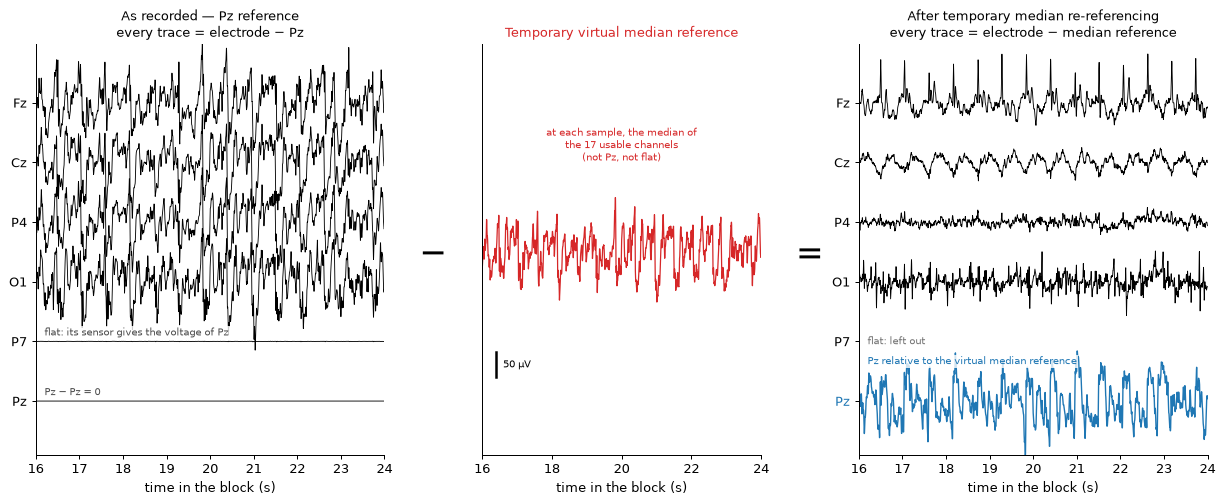

In [13]:
# ---- 2.2 The temporary virtual median reference, on block 1 -------------------------------------------------------------------------
eeg_1 = cut_raws[FIRST_BLOCK].copy().pick('eeg').filter(1, 40)          # a 1-40 Hz copy of the block: the recording is not changed
names = eeg_1.ch_names                                                   # the 19 EEG channels, Pz included
x = eeg_1.get_data() * 1e6                                               # as recorded: every channel minus Pz (µV); Pz - Pz = 0
as_recorded = amplitudes(cut_raws[FIRST_BLOCK])                          # the flat channels are found on the signal as recorded
flat_1 = list(as_recorded.index[(as_recorded['robust'] / as_recorded['robust'].median() < FLAT_RATIO) | (as_recorded['sd'] < FLAT_SD_UV)])
usable_1 = [ch for ch in names if ch != 'Pz' and ch not in flat_1]      # the channels of the median reference: not Pz, not flat
median_ref = np.median(x[[names.index(ch) for ch in usable_1]], axis=0)   # at each sample, the median of the usable channels
y = x - median_ref                                                       # every channel minus the median reference ...
y[[names.index(ch) for ch in flat_1]] = np.nan                           # ... except the flat channels: left out, not re-referenced
print(f'Median reference of block {FIRST_BLOCK[-1]}: at each sample, the median of {len(usable_1)} channels ({", ".join(usable_1)}). '
      f'Left out: Pz, the reference, and the flat channels ({", ".join(flat_1) or "none"}).')

start, length, gap = 16, 8, 120                                          # the seconds of the block we show; µV between two traces
piece = slice(int(start * eeg_1.info['sfreq']), int((start + length) * eeg_1.info['sfreq']))
t = eeg_1.times[piece]
shown = ['Fz', 'Cz', 'P4', 'O1', 'P7', 'Pz']
label_box = dict(fc='white', ec='none', alpha=0.8, pad=1)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6), width_ratios=[1, 0.8, 1])
fig.subplots_adjust(left=0.05, right=0.98, top=0.86, bottom=0.1, wspace=0.3)
for ax, data in ((ax1, x), (ax3, y)):
    for k, ch in enumerate(shown):
        trace = data[names.index(ch)][piece]
        if np.isnan(trace).all():
            ax.text(start + 0.2, -k * gap, 'flat: left out', va='center', fontsize=8, color='0.45')
        else:
            pz_after = ch == 'Pz' and data is y
            ax.plot(t, trace - k * gap, color='tab:blue' if pz_after else 'k', lw=1.1 if pz_after else 0.7)
    ax.set(yticks=[-k * gap for k in range(len(shown))], yticklabels=shown, xlabel='time in the block (s)')
ax1.text(start + 0.2, -shown.index('Pz') * gap + 12, 'Pz − Pz = 0', fontsize=8, color='0.3', bbox=label_box)
ax1.text(start + 0.2, -shown.index('P7') * gap + 12, 'flat: its sensor gives the voltage of Pz', fontsize=8, color='0.3', bbox=label_box)
ax3.text(start + 0.2, -shown.index('Pz') * gap + 0.62 * gap, 'Pz relative to the virtual median reference', fontsize=8, color='tab:blue',
         bbox=label_box)
ax3.get_yticklabels()[shown.index('Pz')].set_color('tab:blue')
ax2.plot(t, median_ref[piece] - 2.5 * gap, color='tab:red', lw=1)
ax2.text(start + length / 2, -0.4 * gap, f'at each sample, the median of\nthe {len(usable_1)} usable channels\n(not Pz, not flat)', ha='center',
         va='top', fontsize=8, color='tab:red')
ax2.plot([start + 0.4] * 2, [-4.6 * gap, -4.6 * gap + 50], color='k', lw=2)      # the scale bar, the same in the three panels
ax2.text(start + 0.6, -4.6 * gap + 25, '50 µV', va='center', fontsize=8)
ax2.set(yticks=[], xlabel='time in the block (s)')
for ax in (ax1, ax2, ax3):
    ax.set(xlim=(start, start + length), ylim=(-(len(shown) - 1) * gap - 0.9 * gap, 0.98 * gap))
ax1.set_title('As recorded — Pz reference\nevery trace = electrode − Pz', fontsize=10)
ax2.set_title('Temporary virtual median reference', fontsize=10, color='tab:red')
ax3.set_title('After temporary median re-referencing\nevery trace = electrode − median reference', fontsize=10)
for left, right, sign in ((ax1, ax2, '−'), (ax2, ax3, '=')):
    fig.text((left.get_position().x1 + right.get_position().x0) / 2, 0.47, sign, ha='center', va='center', fontsize=26)
plt.show()

**Look.** Read the figure as a subtraction, with the same scale in the three panels. Left: as recorded, every trace is the electrode minus
Pz. Pz itself is a flat line, and so is P7, whose sensor gives the same voltage as the reference. Large regular waves, almost two per
second, appear in every channel at the same time: the steps. Middle: the temporary virtual median reference (red), computed at each
sample from the 17 usable channels, with Pz and P7 left out. It contains the same $-V_{Pz}$ term as every recorded channel. Right: each
channel minus the median reference. The $-V_{Pz}$ term cancels, and so does most of what the channels shared: P4 becomes small. What is
left belongs to each electrode: Fz keeps a sharp peak at every step (cell 1.7) and Cz a smaller regular wave. Pz (blue) now has a signal,
0 minus the median reference: the red trace upside down. It is Pz relative to the virtual median reference, not a recovered voltage of Pz,
and it is the largest trace: while walking, the reference sensor at Pz records large signals of its own. P7 is left out: a flat channel
is never re-referenced.

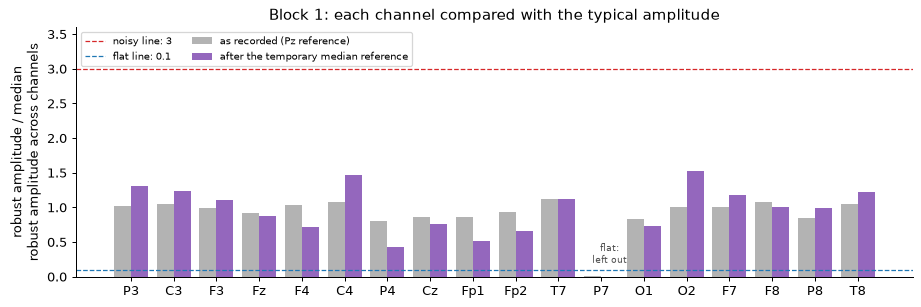

Typical amplitude (the median robust amplitude across channels): 37.4 µV as recorded, 17.1 µV after the temporary median reference.
The median reference itself: 30.2 µV, that is 65 % of the variance of a typical recorded channel.
Channels that are not flat: from 0.80 to 1.12 × the typical amplitude as recorded, from 0.42 to 1.52 after the median reference.
The CM channel (the voltage common to the whole body): 53 µV, 1.4 times a typical recorded channel.


In [14]:
# ---- 2.2 (continued) Each channel compared with the typical amplitude, before and after the temporary median reference --------------
after_ref = amplitudes(cut_raws[FIRST_BLOCK], reference_channels=usable_1)   # robust amplitudes after the median reference
before = as_recorded['robust'] / as_recorded['robust'].median()             # robust amplitude / median robust amplitude across channels
after = after_ref['robust'] / after_ref['robust'].median()                  # the same after the median reference (flat channels: NaN)
bars = np.arange(len(before))
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(bars - 0.2, before, 0.4, color='0.7', label='as recorded (Pz reference)')
ax.bar(bars + 0.2, after, 0.4, color='tab:purple', label='after the temporary median reference')
ax.axhline(NOISY_RATIO, color='tab:red', ls='--', lw=1, label=f'noisy line: {NOISY_RATIO:g}')
ax.axhline(FLAT_RATIO, color='tab:blue', ls='--', lw=1, label=f'flat line: {FLAT_RATIO:g}')
for ch in flat_1:
    ax.text(list(before.index).index(ch) + 0.2, 0.2, 'flat:\nleft out', ha='center', fontsize=7, color='0.3')
ax.set(xticks=bars, xticklabels=before.index, ylim=(0, NOISY_RATIO + 0.6), ylabel='robust amplitude / median\nrobust amplitude across channels',
       title=f'Block {FIRST_BLOCK[-1]}: each channel compared with the typical amplitude')
ax.legend(fontsize=8, loc='upper left', ncol=2)
plt.show()

typical_before, typical_after = as_recorded['robust'].median(), after_ref['robust'].median()
reference_amp = 1.4826 * np.median(np.abs(median_ref - np.median(median_ref)))   # the robust amplitude of the median reference itself
cm = cut_raws[FIRST_BLOCK].copy().pick(['CM']).filter(1, 40, picks='all').get_data()[0] * 1e6   # the voltage common to the whole body
cm_amp = 1.4826 * np.median(np.abs(cm - np.median(cm)))
print(f'Typical amplitude (the median robust amplitude across channels): {typical_before:.1f} µV as recorded, {typical_after:.1f} µV after '
      f'the temporary median reference.')
print(f'The median reference itself: {reference_amp:.1f} µV, that is {100 * (reference_amp / typical_before) ** 2:.0f} % of the variance '
      f'of a typical recorded channel.')
print(f'Channels that are not flat: from {before.drop(flat_1).min():.2f} to {before.drop(flat_1).max():.2f} × the typical amplitude as '
      f'recorded, from {after.min():.2f} to {after.max():.2f} after the median reference.')
print(f'The CM channel (the voltage common to the whole body): {cm_amp:.0f} µV, {cm_amp / typical_before:.1f} times a typical recorded channel.')

**Look.** Each bar is a channel's robust amplitude divided by the typical amplitude: the median robust amplitude across channels, one
number for the block (not the median reference of the figure above, which is a signal). As recorded (grey), every channel except P7 is
between 0.80 and 1.12 times the typical amplitude. The channels look alike because a large part of each recorded channel is shared by all
of them: the median reference alone is 30.2 µV, about 65 % of the variance of a typical recorded channel (37.4 µV; 13.7 µV in the seated
blocks of this participant). A noisy electrode would be partly hidden by this shared part. After the temporary median reference (purple),
the typical amplitude falls to 17.1 µV and the differences between electrodes show, from 0.42 (P4) to 1.52 (O2). No channel reaches the
noisy line (3) in this block. P7 is far below the flat line as recorded, and it is left out after.

C4: noisy (up to 4.5 × the typical amplitude, after the temporary median reference)
P7: flat on the signal as recorded (as low as 0.00 × the typical amplitude, SD as low as 0.18 µV)
The other channels, after the temporary median reference: from 0.4 to 4.5 × the typical amplitude (noisy line: 3).
Report: the typical amplitude is the median robust amplitude across channels, in each recording. Flat = below 0.1 × the typical amplitude or SD below 1 µV, on the signal as recorded; noisy = above 3 × the typical amplitude after a temporary median reference (the median of the 17 channels that are neither Pz nor flat); a channel bad in any of the 5 recordings is bad in all. Bad channels: ['C4', 'P7'] (2 of 18), kept in raw.info['bads'] until the end: never rebuilt.
The recordings themselves are not changed: still referenced to Pz (largest |Pz| in the task: 0.0 µV).


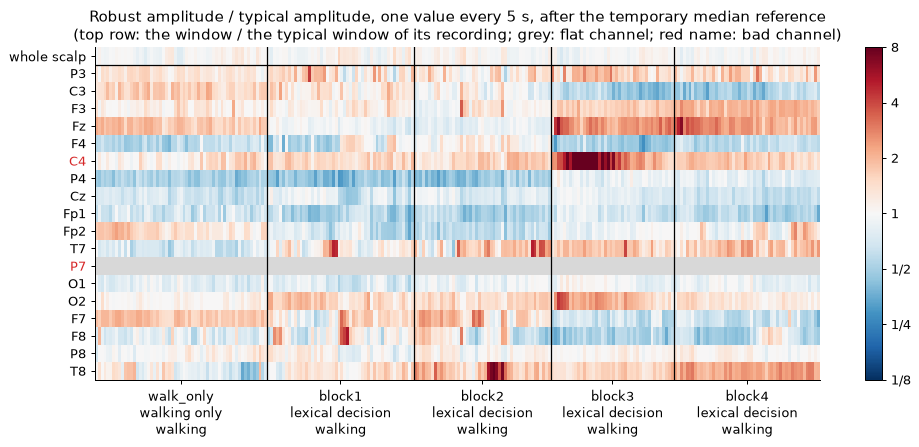

In [15]:
# ---- 2.4 The bad channels, and the quality of every 5-s window ----------------------------------------------------------------------
# One number per channel and recording. 1. Flat: on the signal as recorded. 2. Noisy: after the temporary median reference of cell 2.2
amp_pz = {name: amplitudes(raw) for name, raw in cut_raws.items()}                              # the signal as recorded (Pz reference)
ratio_pz = pd.DataFrame({name: a['robust'] for name, a in amp_pz.items()})
ratio_pz = ratio_pz / ratio_pz.median()                      # robust amplitude / typical amplitude (the median across channels)
sd = pd.DataFrame({name: a['sd'] for name, a in amp_pz.items()})
flat = ((ratio_pz < FLAT_RATIO) | (sd < FLAT_SD_UV)).any(axis=1)        # flat in at least one recording, on the recorded signal
flat_channels = sorted(flat.index[flat])
eeg_channels = cut_raws[FIRST_BLOCK].copy().pick('eeg').ch_names       # the 19 EEG channels, Pz included
usable = [ch for ch in eeg_channels if ch != 'Pz' and ch not in flat_channels]   # the channels of the median reference: not Pz, not flat
amp_median = {name: amplitudes(raw, reference_channels=usable) for name, raw in cut_raws.items()}   # after the median reference
ratio = pd.DataFrame({name: a['robust'] for name, a in amp_median.items()})   # the flat channels are left out (NaN)
ratio = ratio / ratio.median()                               # robust amplitude / typical amplitude of the usable channels
noisy = (ratio > NOISY_RATIO).any(axis=1) & ~flat            # noisy in at least one recording, after the median reference
BAD_CHANNELS = sorted(ratio.index[flat | noisy])
for raw in recordings.values():
    raw.info['bads'] = list(BAD_CHANNELS)                    # MNE now leaves these channels out where it should, until the end
good = [ch for ch in ratio.index if ch not in BAD_CHANNELS]            # the good channels, without Pz

for ch in BAD_CHANNELS:
    if flat[ch]:
        print(f'{ch}: flat on the signal as recorded (as low as {ratio_pz.loc[ch].min():.2f} × the typical amplitude, SD as low as '
              f'{sd.loc[ch].min():.2f} µV)')
    else:
        print(f'{ch}: noisy (up to {ratio.loc[ch].max():.1f} × the typical amplitude, after the temporary median reference)')
print(f'The other channels, after the temporary median reference: from {ratio.min().min():.1f} to {ratio.max().max():.1f} × the typical '
      f'amplitude (noisy line: {NOISY_RATIO:g}).')
print(f'Report: the typical amplitude is the median robust amplitude across channels, in each recording. Flat = below {FLAT_RATIO:g} × the '
      f'typical amplitude or SD below {FLAT_SD_UV:g} µV, on the signal as recorded; noisy = above {NOISY_RATIO:g} × the typical amplitude after '
      f'a temporary median reference (the median of the {len(usable)} channels that are neither Pz nor flat); a channel bad in any of the '
      f'{len(cut_raws)} recordings is bad in all. Bad channels: {BAD_CHANNELS} ({len(BAD_CHANNELS)} of {len(ratio)}), kept in '
      f"raw.info['bads'] until the end: never rebuilt.")
print(f'The recordings themselves are not changed: still referenced to Pz (largest |Pz| in the task: '
      f'{np.abs(recordings["task"].get_data(picks="Pz")).max() * 1e6:.1f} µV).')
if len(BAD_CHANNELS) > MAX_BAD:
    print(f'WARNING: more than {MAX_BAD} bad channels (about one fifth of the 18 recorded). Look at the recordings before going on.')

# The same measure, one value every QC_WINDOW_S seconds: when was a channel, or the whole scalp, abnormal?
TASK_NAMES = {'RestingState': 'resting state', 'LexicalDecision': 'lexical decision', 'WalkingOnly': 'walking only'}
PARTS, first_sample = {}, 0                                  # each recording cut at its triggers: where it is in `recordings`
for name, raw in cut_raws.items():
    PARTS[name] = ('task', first_sample) if name in BLOCKS else (name, 0)
    first_sample += raw.n_times if name in BLOCKS else 0


def block_label(name):
    """The name of the recording, its task and its posture, from its BIDS name (cell 1.1): block1, lexical decision, seated."""
    task, acq = LABELS[name].removeprefix('task-').split('_acq-')
    return f"{name}\n{TASK_NAMES.get(task, task)}\n{'seated' if acq.startswith('seated') else 'walking'}"


def window_quality(data):
    """The 5-s check of `data` (walking without the task, then the task, as in `recordings`). Each part (the walk, each block) is
    cut into QC_WINDOW_S windows. In each window: the robust amplitude of each usable channel after the temporary median reference
    (1-40 Hz) divided by the typical amplitude of the window, and in the row 'whole scalp' the typical amplitude of the window divided by
    the typical window of its part. Returns this table (one column per window) and the windows (part, recording, start in s)."""
    columns, windows = [], []
    for part, (recording, first) in PARTS.items():
        raw = data[recording]
        x = raw.get_data(picks=usable, start=first, stop=first + cut_raws[part].n_times) * 1e6   # this part, the usable channels (µV)
        x = mne.filter.filter_data(x, raw.info['sfreq'], 1, 40)                          # 1-40 Hz, as in cell 2.1
        x = x - np.median(x, axis=0)                                                      # minus the temporary median reference
        n = int(QC_WINDOW_S * raw.info['sfreq'])
        mad = np.array([1.4826 * np.median(np.abs(p - np.median(p, axis=1, keepdims=True)), axis=1)
                        for p in (x[:, k:k + n] for k in range(0, x.shape[1] - n + 1, n))]).T   # channels × windows
        typical = np.median(mad, axis=0)                                                  # the typical amplitude of each window
        columns.append(np.vstack([typical / np.median(typical), mad / typical]))
        windows += [(part, recording, (first + k * n) / raw.info['sfreq']) for k in range(mad.shape[1])]
    return (pd.DataFrame(np.hstack(columns), index=['whole scalp'] + usable),
            pd.DataFrame(windows, columns=['part', 'recording', 'start']))


def plot_quality(table, ax, title):
    """A table of window_quality as a heatmap: one column per window; the row 'whole scalp' on top, then every EEG channel but Pz (the
    flat ones have no value: grey). The colour is log2 of the ratio, from 1/8 to 8, the same in every figure."""
    rows = ['whole scalp'] + list(ratio.index)
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('0.85')
    image = ax.imshow(np.log2(table.reindex(rows).to_numpy()), cmap=cmap, vmin=-3, vmax=3, aspect='auto', interpolation='nearest')
    parts = windows['part'].to_numpy()
    edges = np.flatnonzero(parts[1:] != parts[:-1]) + 1      # the first window of each part after the first
    for edge in edges:
        ax.axvline(edge - 0.5, color='k', lw=1)
    ax.axhline(0.5, color='k', lw=1)                         # the whole scalp above, the channels below
    ax.set(yticks=range(len(rows)), yticklabels=rows, xticks=(np.r_[0, edges] + np.r_[edges, len(parts)]) / 2 - 0.5,
           xticklabels=[block_label(part) for part in PARTS], title=title)
    for label in ax.get_yticklabels():
        if label.get_text() in BAD_CHANNELS:
            label.set_color('tab:red')                       # the bad channels: their name in red
    return image


quality, windows = window_quality(recordings)
fig, ax = plt.subplots(figsize=(13, 4.8))
image = plot_quality(quality, ax, f'Robust amplitude / typical amplitude, one value every {QC_WINDOW_S:g} s, after the temporary median '
                                  f'reference\n(top row: the window / the typical window of its recording; grey: flat channel; red name: bad channel)')
cbar = fig.colorbar(image, ax=ax, ticks=[-3, -2, -1, 0, 1, 2, 3])
cbar.ax.set_yticklabels(['1/8', '1/4', '1/2', '1', '2', '4', '8'])
plt.show()

**Look.** The printed report says which channels are bad and why. **P7** is flat: on the signal as recorded its robust amplitude is about
0.00 times the typical amplitude and its standard deviation as low as 0.18 µV (the flat line is 1 µV), because its sensor gives the same
voltage as the reference. **C4** is noisy: after the temporary median reference it reaches 4.5 times the typical amplitude (the noisy line
is 3). The figure shows when: in the first part of block 3, C4 is 4 to 8 times the typical amplitude of its windows, and close to normal
elsewhere. A channel that is bad in one recording is bad in all of them, so that every recording has the same good channels (one ICA for
all, step 6): C4 is left out of the whole session. With too many bad channels, the average reference and ICA rest on too few electrodes:
BeMoBIL limits the fraction it removes (for example one fifth, Klug et al., 2022), and with 18 recorded channels we set `MAX_BAD = 3`:
with more, we look at the recording before going on. The median reference only served to measure: the recordings are still referenced to
Pz, with the bad channels listed in `raw.info['bads']`, where they stay until the end (they are never rebuilt), and step 4 makes the real
reference.

The figure shows when each channel was abnormal. Each column is 5 seconds and each row a channel. Red means louder than the typical
amplitude of that window, blue quieter. The top row, **whole scalp**, compares the typical amplitude of each window with the typical window
of its recording: a movement, or a problem of the reference, would turn the whole column red there. A channel that lost contact for a
while would appear as a red band, and one that was never in contact as a row that stays red or blue. P7 is grey: it is flat the whole
time. While walking, more rows have red bands than seated: Fz is 2 to 4 times the typical amplitude for most of blocks 3 and 4 (its sharp
peak at every step, cell 1.7), T8 has a dark spot at the end of block 2, T7 spots in blocks 1 and 2, O2 at the start of block 3. A few
rows stay bluer (P4, Cz, Fp1, and F4 and C3 in blocks 3 and 4): steady differences between electrodes. The whole-scalp row stays white:
the steps shake all the channels, but the typical amplitude of the windows does not jump. Published pipelines judge short windows (1 s in
PREP, 5 s in BeMoBIL) and remove a channel only when it is abnormal in more than a given fraction of the windows (Bigdely-Shamlo et al.,
2015; Klug et al., 2022). We use one number per recording, and this figure shows what that number hides. Cell 2.5 turns the windows that
cross a threshold into annotations.

### Suspicious periods: QC annotations, not BAD annotations

Some problems last only a few seconds: an electrode that loses contact for a moment, a burst of muscle activity, a movement. The channel is
not bad for the whole recording, so it does not go into `raw.info['bads']`. We write down **when** and **where** with an **annotation**: a
label with an onset, a duration and a description, attached to the recording (cell 1.9 already uses annotations for the words).

**`BAD` means something to MNE.** An annotation whose description starts with `BAD` is skipped automatically: `mne.Epochs` drops every
epoch that overlaps it, and `ica.fit(..., reject_by_annotation=True)` does not learn from it. A suspicious period is not necessarily
unusable, so we do **not** call every suspicious window BAD. We use two families:

| Prefix | Meaning | Does MNE skip it? |
|---|---|---|
| `QC_` (quality control) | suspicious, worth remembering: `QC_large_amplitude`, `QC_contact`, `QC_motion`, `QC_slow_shift`... | no |
| `BAD_` | to exclude: `BAD_ICA_...` only on the copy that trains ICA (step 5), `BAD_final_...` for what is still unusable after ICA (step 8) | yes |

**One channel or the whole scalp.** An annotation can name its channels (`ch_names`). A dry electrode can lose contact for a few seconds
while the other 18 are fine, so the annotation says which electrode. A problem of the whole scalp (a movement, for example) gets an annotation
without `ch_names`. Careful: MNE does not use the `ch_names` of a `BAD` annotation to leave out only that channel. `mne.Epochs` drops the
whole epoch, and ICA skips the whole period (checked with MNE 1.13). One more reason to keep channel problems as `QC_`.

**The rule** (cell 0.3). In each 5-s window of cell 2.4, a channel above `QC_RATIO` (3) times the typical amplitude of its window gets
`QC_large_amplitude` on that channel, and a channel below `FLAT_RATIO` (0.1) gets `QC_contact`. A window whose typical amplitude is above 3
times the typical window of its recording (row "whole scalp") gets `QC_large_amplitude` without channel. Consecutive windows with the same
problem become one period.

In [16]:
# ---- 2.5 The suspicious periods: QC annotations, from the same 5-s windows ----------------------------------------------------------
found = []                                                   # one row per suspicious window and channel
for k, window in windows.iterrows():
    column = quality.iloc[:, k]
    if column['whole scalp'] > QC_RATIO:
        found.append((window.recording, window.part, window.start, 'QC_large_amplitude', 'all', column['whole scalp']))
    for ch in [ch for ch in usable if ch not in BAD_CHANNELS]:   # a bad channel is out for the whole session: no QC period for it
        if column[ch] > QC_RATIO:
            found.append((window.recording, window.part, window.start, 'QC_large_amplitude', ch, column[ch]))
        elif column[ch] < FLAT_RATIO:
            found.append((window.recording, window.part, window.start, 'QC_contact', ch, column[ch]))

periods = []                                                 # consecutive windows with the same problem become one period
for f in sorted(found, key=lambda f: (f[0], f[4], f[3], f[2])):
    recording, part, start, description, channels, value = f
    last = periods[-1] if periods else None
    if (last and (last['recording'], last['channels'], last['description']) == (recording, channels, description)
            and abs(last['onset'] + last['duration'] - start) < 1e-6):
        last['duration'] += QC_WINDOW_S                      # the next window of the same problem: the period grows
        last['ratio'] = min(last['ratio'], value) if description == 'QC_contact' else max(last['ratio'], value)
    else:
        periods.append(dict(recording=recording, part=part, onset=start, duration=QC_WINDOW_S, description=description,
                            channels=channels, ratio=value))
qc_table = pd.DataFrame(periods, columns=['recording', 'part', 'onset', 'duration', 'description', 'channels', 'ratio'])

for raw in recordings.values():                              # (running this cell again adds nothing twice)
    raw.annotations.delete([i for i, d in enumerate(raw.annotations.description) if d.startswith('QC_')])
for p in qc_table.itertuples():
    raw = recordings[p.recording]
    raw.annotations.append(onset=raw.first_time + p.onset, duration=p.duration, description=p.description,
                           ch_names=None if p.channels == 'all' else [[p.channels]])   # one channel, or the whole scalp
print(f'{len(qc_table)} QC periods: {(qc_table["channels"] == "all").sum()} on the whole scalp, {(qc_table["channels"] != "all").sum()} '
      f'on one channel. Onset: seconds from the start of the recording (the task: the four blocks joined).')
qc_table.round(2)

24 QC periods: 0 on the whole scalp, 24 on one channel. Onset: seconds from the start of the recording (the task: the four blocks joined).


,recording,part,onset,duration,description,channels,ratio
0,task,block2,331.93,5.0,QC_large_amplitude,F3,3.60
1,task,block1,125.00,5.0,QC_large_amplitude,F7,3.27
2,task,block2,351.93,5.0,QC_large_amplitude,F7,3.23
3,task,block2,361.93,5.0,QC_large_amplitude,F7,3.37
4,task,block1,125.00,15.0,QC_large_amplitude,F8,5.42
5,task,block3,492.55,25.0,QC_large_amplitude,Fz,6.58
6,task,block3,552.55,5.0,QC_large_amplitude,Fz,3.19
7,task,block3,672.55,5.0,QC_large_amplitude,Fz,3.47
8,task,block3,682.55,10.0,QC_large_amplitude,Fz,3.40
9,task,block4,701.79,15.0,QC_large_amplitude,Fz,6.65


**Look.** In P010 while walking, 24 periods are suspicious, each on one channel: Fz most often (7 periods in blocks 3 and 4, up to 6.7
times the typical amplitude of their window), then T7 (5), T8 (3, up to 8.7 times in block 2), F7 and P3 (3 each), F3, F8 and O2 (1
each). No window is suspicious on the whole scalp, and no channel loses contact. C4 has no period: a bad channel is out for the whole
session. The 24 annotations are now attached to the recordings, each with its channel (`ch_names`): they follow the data through
filtering, re-referencing, ICA and saving, and they reject nothing. Step 5 decides which of them ICA should not learn from, and step 8
looks at them again after ICA.

## 3. Filter, and remove the muscle activity with Auto-CCA

**What.** Remove the frequencies we do not want. The signal of an electrode is a **sum of many frequencies**. Some of them are what we
want to study: the brain rhythms and the slow waves of the ERPs. Others are artifacts, each at its own frequencies:

- **slow drifts** (sweat, slow movements of the electrode on the skin): below about 0.5 Hz;
- **muscles**: fast and irregular activity, mostly above 20–30 Hz.

The power line (60 Hz in North America) is another classic artifact, but our recordings have practically none: its voltage is common to
the whole body, and the headset cancels it (step 2, "Before we measure"). This pipeline does not need to remove it.

**Why.** An artifact hides what we want to measure: a drift of tens of µV is larger than an ERP of a few µV.

**How.** First, what the basic filters do, on a made-up signal (3.1) and on this participant's EEG (3.2 and 3.3), and how low the high-pass
cut-off must be for the ERPs we study (3.4 and 3.5). Then the filter of this pipeline: one copy of the data, band-passed from 0.1 to 100 Hz
(3.6 and 3.7). ICA needs a different filter: step 5 makes a copy of the data for it. Last, Auto-CCA removes the muscle activity
spread over the scalp (3.8): from step 4 on, the analysis data are filtered and cleaned.

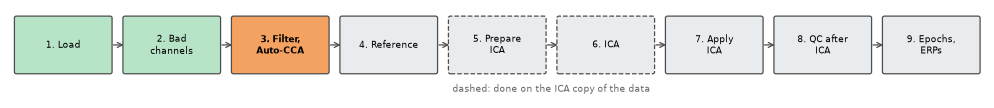

In [21]:
pipeline_map(3)

### The three filters

| Filter | Keeps | Removes | Used for |
|---|---|---|---|
| **high-pass** | the frequencies above its cut-off | the ones below | slow drifts |
| **low-pass** | the frequencies below its cut-off | the ones above | muscles |
| **band-pass** | the frequencies between two cut-offs | the others | both at once |

In MNE, `raw.filter(l_freq, h_freq)` is a high-pass if you give only `l_freq`, a low-pass if you give only `h_freq`, and a band-pass if you
give both. By default MNE uses zero-phase FIR filters: they do not shift the peaks in time (Widmann et al., 2015).

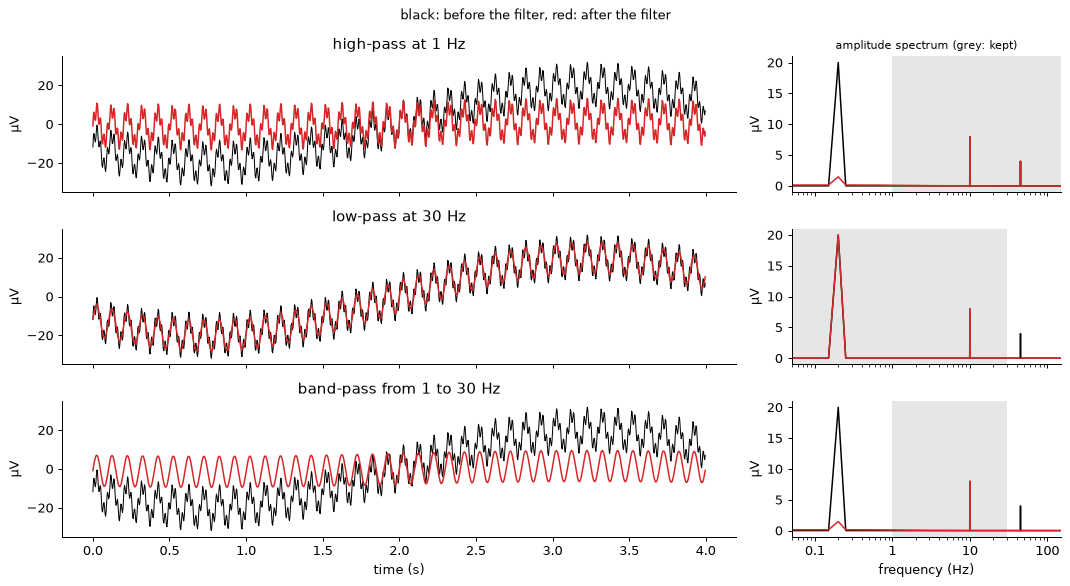

In [17]:
# ---- 3.1 High-pass, low-pass and band-pass on a made-up signal ----------------------------------------------------------------------
sf_demo = 300                                                # samples per second, as in our recordings
t_demo = np.arange(0, 20, 1 / sf_demo)                       # 20 s: the filters need room at the edges
made_up = (20 * np.sin(2 * np.pi * 0.2 * t_demo)             # a slow drift (0.2 Hz) ...
           + 8 * np.sin(2 * np.pi * 10 * t_demo)             # ... an alpha rhythm (10 Hz) ...
           + 4 * np.sin(2 * np.pi * 45 * t_demo))            # ... and fast activity (45 Hz), like that of the muscles (µV)
three_filters = {'high-pass at 1 Hz': (1, None), 'low-pass at 30 Hz': (None, 30), 'band-pass from 1 to 30 Hz': (1, 30)}
shown = (t_demo >= 8) & (t_demo < 12)                        # 4 s from the middle of the signal
freqs_demo = np.fft.rfftfreq(len(t_demo), 1 / sf_demo)[1:]   # the frequencies of the spectrum (0 Hz left out: log scale)

fig, axes = plt.subplots(3, 2, figsize=(12, 6.6), width_ratios=[2.5, 1], sharex='col', sharey='col')
for (ax_time, ax_freq), (label, (l_freq, h_freq)) in zip(axes, three_filters.items()):
    after = mne.filter.filter_data(made_up, sf_demo, l_freq, h_freq)
    ax_time.plot(t_demo[shown] - 8, made_up[shown], color='k', lw=0.8)
    ax_time.plot(t_demo[shown] - 8, after[shown], color='tab:red', lw=1.2)
    ax_time.set(ylabel='µV', title=label)
    ax_freq.axvspan(l_freq or 0.05, h_freq or 150, color='0.9', lw=0)   # grey: the frequencies the filter keeps
    for signal, color in ((made_up, 'k'), (after, 'tab:red')):
        ax_freq.plot(freqs_demo, np.abs(np.fft.rfft(signal))[1:] / len(t_demo) * 2, color=color, lw=1.2)   # the size of each sine
    ax_freq.set(xscale='log', xlim=(0.05, 150), ylabel='µV')
    ax_freq.set_xticks([0.1, 1, 10, 100], ['0.1', '1', '10', '100'])
axes[0, 1].set_title('amplitude spectrum (grey: kept)', fontsize=9)
axes[-1, 0].set_xlabel('time (s)')
axes[-1, 1].set_xlabel('frequency (Hz)')
fig.suptitle('black: before the filter, red: after the filter', fontsize=10)
plt.tight_layout()
plt.show()

**Look.** The made-up signal (black) is the sum of a slow drift (0.2 Hz), an alpha rhythm (10 Hz) and fast activity (45 Hz). On the right,
each of them is one peak of the spectrum. Each filter keeps the frequencies in its grey band and removes the others (red: after the filter):

1. **High-pass at 1 Hz**: the drift is almost gone; the alpha rhythm and the fast activity are kept.
2. **Low-pass at 30 Hz**: the fast activity is gone; the drift and the alpha rhythm are kept.
3. **Band-pass from 1 to 30 Hz**: the drift is almost gone and the fast activity is gone: only the alpha rhythm is left.

### The same filters on the real EEG

Real EEG has the same problems. Cell 3.2 finds two examples in this participant's task (the good channels, as recorded: Pz reference,
no filter yet), and filters each of them:

- **a slow drift**, in 30 s: how much the level of a channel moves between the first and the last 5 s. The largest drifts can be so large
  that the EEG would look like a flat line next to them, so we take a strong one that is not extreme (98 % of the 30-s windows of all
  channels drift less). Filter: a **high-pass at 1 Hz**.
- **muscle activity**, in 5 s: the window with the strongest fast activity (above 30 Hz). Filter: a **low-pass at 30 Hz**.

**These cut-offs are chosen to make the effects easy to see. They are not the filters of our pipeline:** a high-pass at 1 Hz would distort
the slow ERPs (cells 3.4 and 3.5), and our analysis keeps the frequencies up to 100 Hz (cell 3.6).

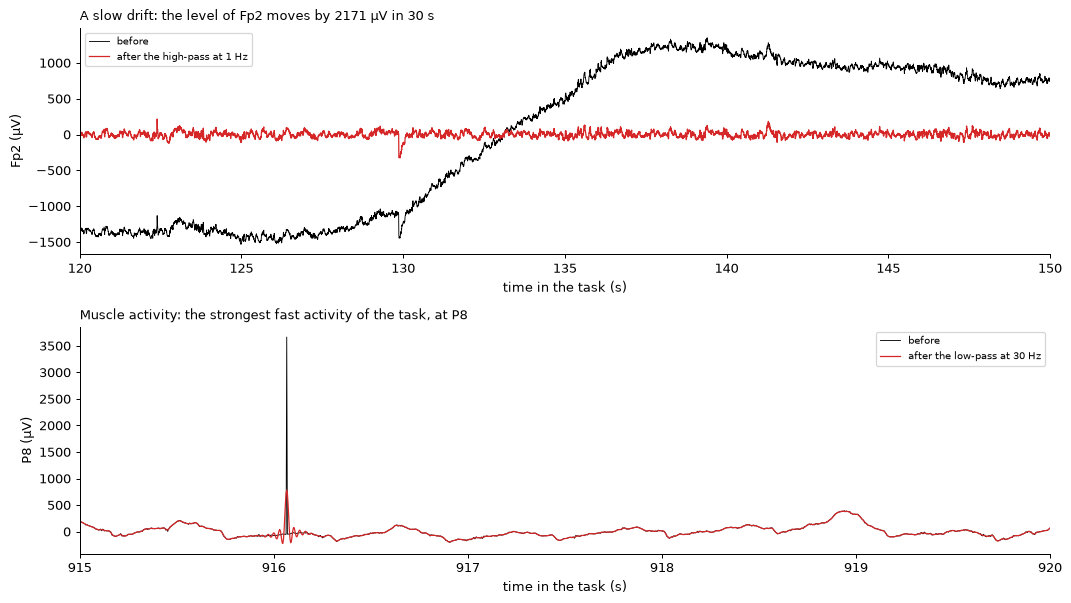

In [18]:
# ---- 3.2 A slow drift and muscle activity in the task, before and after a filter ----------------------------------------------------
task = recordings['task'].copy().pick(good)                  # the good channels of step 2 (Pz left out), as recorded
sfreq = task.info['sfreq']
# Windows that do not cross the junction of two blocks or a data gap (make_fixed_length_epochs leaves those out)
long_windows = mne.make_fixed_length_epochs(task, duration=30, preload=True)                          # 30 s, as recorded
short_windows = mne.make_fixed_length_epochs(task.copy().filter(30, None), duration=5, preload=True)  # 5 s, above 30 Hz only
level = long_windows.get_data() * 1e6                        # windows x channels x samples (µV)
n5 = int(5 * sfreq)
drift = pd.DataFrame(np.abs(level[:, :, -n5:].mean(axis=-1) - level[:, :, :n5].mean(axis=-1)), columns=good,
                     index=(long_windows.events[:, 0] - task.first_samp) / sfreq).stack()     # mean of the last 5 s - first 5 s
muscle = pd.DataFrame(short_windows.get_data().std(axis=-1) * 1e6, columns=good,
                      index=(short_windows.events[:, 0] - task.first_samp) / sfreq).stack()   # how strong the fast part is
drift_start, drift_channel = (drift - drift.quantile(0.98)).abs().idxmin()   # a strong drift, but not one of the extreme ones
muscle_start, muscle_channel = muscle.idxmax()                               # the strongest fast activity


def plot_before_after(ax, channel, start, length, l_freq, h_freq, label):
    """One channel of the task from start to start + length (s), before (black) and after (red) a filter. The filter is applied to the
    whole recording, then the window is cut out. Each trace is drawn around its own mean, as raw.plot() does."""
    before = recordings['task'].copy().pick([channel])
    after = before.copy().filter(l_freq, h_freq)
    for data, color, lw, name in ((before, 'k', 0.7, 'before'), (after, 'tab:red', 1.0, f'after the {label}')):
        piece = data.copy().crop(start, start + length)
        y = piece.get_data()[0] * 1e6
        ax.plot(piece.times + start, y - y.mean(), color=color, lw=lw, label=name)
    ax.set(xlim=(start, start + length), xlabel='time in the task (s)', ylabel=f'{channel} (µV)')
    ax.legend(loc='best', fontsize=8)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.8))
plot_before_after(ax1, drift_channel, drift_start, 30, 1.0, None, 'high-pass at 1 Hz')
ax1.set_title(f'A slow drift: the level of {drift_channel} moves by {drift[drift_start, drift_channel]:.0f} µV in 30 s', loc='left',
              fontsize=10)
plot_before_after(ax2, muscle_channel, muscle_start, 5, None, 30.0, 'low-pass at 30 Hz')
ax2.set_title(f'Muscle activity: the strongest fast activity of the task, at {muscle_channel}', loc='left', fontsize=10)
plt.tight_layout()
plt.show()

**Look.** Top: the level of Fp2 moves by about 2,200 µV in 30 s (black), far more than the EEG riding on it. After the high-pass at 1 Hz
(red), the drift is gone and the faster activity stays, with a few sharp spikes. Bottom: while walking, the strongest fast activity of the
task is not muscle activity: it is a single spike of about 3,600 µV at P8, an electrode "pop" (a sudden change of the contact between the
electrode and the skin). After the low-pass at 30 Hz (red), the spike is smaller but still there: a filter only removes frequencies, and
this jump also has energy at the frequencies the filter keeps. Both artifacts are hundreds of times larger than an ERP of a few µV.

Cell 3.3 lets you choose a channel, a moment of the task and one of the three filters. It needs the ipywidgets package, and works only while
the notebook runs.

In [19]:
# ---- 3.3 Explore: any channel, any moment, any of the three filters (only while the notebook runs) ----------------------------------
try:
    from ipywidgets import interact, Dropdown, IntSlider
except ImportError:
    print('This explorer needs the ipywidgets package: pip install ipywidgets')
else:
    FILTERS = {'high-pass at 1 Hz': (1.0, None), 'low-pass at 30 Hz': (None, 30.0), 'band-pass from 1 to 30 Hz': (1.0, 30.0)}
    last_start = int(recordings['task'].times[-1]) - 60      # the latest start that leaves room for 60 s

    @interact(channel=Dropdown(options=good, value=drift_channel, description='channel'),
              filter_name=Dropdown(options=list(FILTERS), description='filter'),
              length=Dropdown(options=[5, 10, 30, 60], value=30, description='seconds'),
              start=IntSlider(value=int(drift_start), min=0, max=last_start, description='start (s)', continuous_update=False))
    def explore(channel, filter_name, length, start):
        fig, ax = plt.subplots(figsize=(12, 3.4))
        plot_before_after(ax, channel, start, length, *FILTERS[filter_name], filter_name)
        plt.show()

interactive(children=(Dropdown(description='channel', index=8, options=('P3', 'C3', 'F3', 'Fz', 'F4', 'P4', 'C…

### The cut-off of the high-pass filter depends on the ERP

The N400 and the LPC (late positive component) are slow waves that last several hundred milliseconds, so they contain the low frequencies
that a high-pass filter removes. A cut-off that is too high **shrinks** them and adds **fake waves of the opposite polarity** around them,
for example a fake negativity before a late positivity, which can be mistaken for an N400 effect. What the literature says:

- Tanner et al. (2015) filtered N400 and P600 (late positivity) data from a sentence-reading task with cut-offs from 0.01 to 1 Hz. Cut-offs of
  0.3 Hz and above produced fake effects of opposite polarity, and cut-offs between 0.01 and 0.1 Hz gave the best statistical power. High-pass
  filters should be applied to the continuous EEG, not to epochs or averaged ERPs.
- Zhang et al. (2024) compared many filters on the ERP CORE data and recommend a high-pass at 0.2 Hz for the N400 and for the P3 (a late
  positivity), with no low-pass filter or a low-pass at 10 Hz or above.

Our pipeline uses a high-pass at 0.1 Hz, at or below these recommendations. Both papers use other filters than MNE's, so take their cut-offs
as a guide, not as exact values.

**Animation 3.4.** The animation filters a made-up ERP (a P2, an N400 and an LPC, in grey) with high-pass filters of increasing cut-off. Press
play, and read in the title the mean amplitude in the N400 window and in the LPC window.

In [20]:
# ---- 3.4 Animation: what a high-pass filter does to the N400 and the LPC ------------------------------------------------------------
sf_demo = 100
t_erp = np.arange(-1, 2, 1 / sf_demo)                        # one trial, from -1 to 2 s


def bump(centre, width, size):
    """A smooth wave of the given size (µV), centred on the given time (s)."""
    return size * np.exp(-((t_erp - centre) / width) ** 2)


erp = bump(0.20, 0.035, 2.0) + bump(0.45, 0.11, -3.0) + bump(0.72, 0.18, 4.0)   # a P2, an N400 and an LPC (slow)
n400_window = COMPONENTS['N400']['window']
lpc_window = COMPONENTS['LPC']['window']
in_n400 = (t_erp >= n400_window[0]) & (t_erp <= n400_window[1])
in_lpc = (t_erp >= lpc_window[0]) & (t_erp <= lpc_window[1])


def high_pass(cutoff):
    """The made-up ERP after a high-pass filter. 60 s of silence on each side leave room for the long filters."""
    room = 60 * sf_demo
    return mne.filter.filter_data(np.r_[np.zeros(room), erp, np.zeros(room)], sf_demo, l_freq=cutoff, h_freq=None)[room:-room]


cutoffs = [0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]   # high-pass cut-off frequencies (Hz)
filtered = [high_pass(c) for c in cutoffs]

fig, ax = plt.subplots(figsize=(9, 3.8))


def draw(k):
    ax.clear()
    ax.plot(t_erp, erp, color='0.6', lw=3, label='ERP before filtering')
    ax.plot(t_erp, filtered[k], color='tab:red' if cutoffs[k] > 0.3 else 'tab:green', lw=2, label='after the high-pass filter')
    for name, window, shade in [('N400', n400_window, '0.93'), ('LPC', lpc_window, '0.86')]:
        ax.axvspan(*window, color=shade)
        ax.text(np.mean(window), 4.6, name, ha='center', fontsize=9)
    ax.set(xlim=(-0.5, 1.5), ylim=(-4.5, 5.2), xlabel='time from word onset (s)', ylabel='µV')
    ax.set_title(f'High-pass at {cutoffs[k]:g} Hz: N400 window {filtered[k][in_n400].mean():+.1f} µV (true {erp[in_n400].mean():+.1f}), '
                 f'LPC window {filtered[k][in_lpc].mean():+.1f} µV (true {erp[in_lpc].mean():+.1f})', fontsize=9)
    ax.axhline(0, color='0.5', lw=0.6)
    ax.legend(loc='lower right', fontsize=8)


anim = animation.FuncAnimation(fig, draw, frames=len(cutoffs), interval=1200)
show_animation(fig, anim)

**Look.** At 0.1 Hz the filtered ERP (green) is almost the original (grey): the N400 window is −1.9 µV for −1.8 µV, and the LPC window
+1.6 µV for +1.7 µV. From about 0.5 Hz (red) the LPC shrinks, and the filter creates slow fake waves of the opposite polarity around it. The
fake negativity before the LPC adds to the N400, so the N400 window becomes **more** negative than it really is, while the LPC window becomes
smaller: at 1 Hz, −2.3 µV and +1.0 µV. Both amplitudes are wrong, in opposite directions, and the fake waves could be taken for real effects
(Tanner et al., 2015).

### The filter of this pipeline: a band-pass from 0.1 to 100 Hz

From here on we filter the data we analyze, not examples. We keep **one copy** of the data, band-passed from **0.1 to 100 Hz**
(`ANALYSIS_BAND` in cell 0.3):

- **0.1 Hz**: removes the slowest drifts and keeps the N400 and the late positivity (cells 3.4 and 3.5).
- **100 Hz**: keeps the fast activity of the muscles, which ICA needs to find the muscle components (ICLabel looks at the frequencies up to
  100 Hz, step 6). The ERPs do not need a low-pass: the mean amplitude over a time window averages most of the fast activity out (Zhang et
  al., 2024: no low-pass, or one at 10 Hz or above).

In [21]:
# ---- 3.7 Filter the two recordings from 0.1 to 100 Hz -------------------------------------------------------------------------------
filtered_pz = {name: raw.copy().filter(*ANALYSIS_BAND, picks='eeg') for name, raw in recordings.items()}   # "_pz": still referenced to Pz
print(f'Band-pass {ANALYSIS_BAND[0]:g}-{ANALYSIS_BAND[1]:g} Hz:', ', '.join(filtered_pz))

Band-pass 0.1-100 Hz: walk_only, task


### Muscle activity spread over the scalp: Auto-CCA

**What.** Remove the muscle activity that reaches many channels at once. The forehead, the temples, the jaw and the neck are never
completely relaxed, and their activity spreads to the electrodes at the edge of the cap and beyond. This is the last cleaning of the
analysis data before step 4.

**Why not a filter.** Muscle activity is fast, but from about 20 Hz upward its frequencies are also those of the EEG, which our analysis
keeps up to 100 Hz (cell 3.6). A low-pass would remove the brain activity at these frequencies too, and the muscle activity ICLabel needs to
recognize the muscle components that remain (step 6).

**How: autocorrelation.** Brain activity changes smoothly: at 300 samples per second, the signal one sample later (3.3 ms) is almost the
same, so its **autocorrelation** is close to 1. Muscle activity is fast and irregular, close to random noise: one sample says little about
the next, and its autocorrelation is lower. BSS-CCA (De Clercq et al., 2006) uses this. A canonical correlation analysis (CCA) between the
data and the same data one sample earlier unmixes the channels into components ordered by their autocorrelation: component 0 is the most
autocorrelated, the last one the least. Like ICA, it combines the electrodes at each moment. Each component then gets the **slope** of its
spectrum, a straight line fitted to log power against log frequency between 7 and 75 Hz: brain activity falls steeply with frequency (slope
about −1 to −2), muscle activity does not (slope near 0 or above). The components whose slope is above `CCA_SLOPE` (cell 0.3) are removed,
and the channels are rebuilt from the others (Janani et al., 2018). Muscle activity comes and goes, so this is done in 10-s windows that
overlap by half and blend smoothly into each other. Done automatically like this, the method is often called **Auto-CCA**.

**Why here.** ICA (step 6) learns from a copy of these cleaned data, and step 7 applies it to the same cleaned data: an ICA solution must
be applied to the kind of signal it learned from. With the diffuse muscle activity gone, fewer of ICA's 16 components are spent on it. The
two methods share the work: **Auto-CCA** removes the diffuse, fast muscle activity; **ICA** removes the sources with a fixed map, which are
the blinks, the eye movements and the clear muscle components that remain. Blinks and eye movements are slow, with a high autocorrelation:
Auto-CCA leaves them to ICA.

**Caution.** CCA components are mixtures: a component that is mostly muscle can also carry some brain activity, which goes with it (Janani
et al., 2018). The threshold is a trade-off, and it depends on the headset. Janani et al. used −0.48 with 115 electrodes; on the 17
channels of P010's seated data, −0.48 removed four components per window and most of the alpha rhythm at O1 and O2. `CCA_SLOPE = 0` removes only the
components whose power does not fall at all with frequency, and cell 3.8 measures what that still costs.

walk_only   59 windows; components removed per window: median 1, at most 3 of 16. Power removed: 30-100 Hz at F7/F8/T7/T8 11 %, 8-13 Hz (alpha) at O1/O2 0 %
task       190 windows; components removed per window: median 0, at most 0 of 16. Power removed: 30-100 Hz at F7/F8/T7/T8 0 %, 8-13 Hz (alpha) at O1/O2 0 %
The average blink at Fp1 (150 blinks): 516 µV peak to peak; Auto-CCA removed 0.0 µV of it


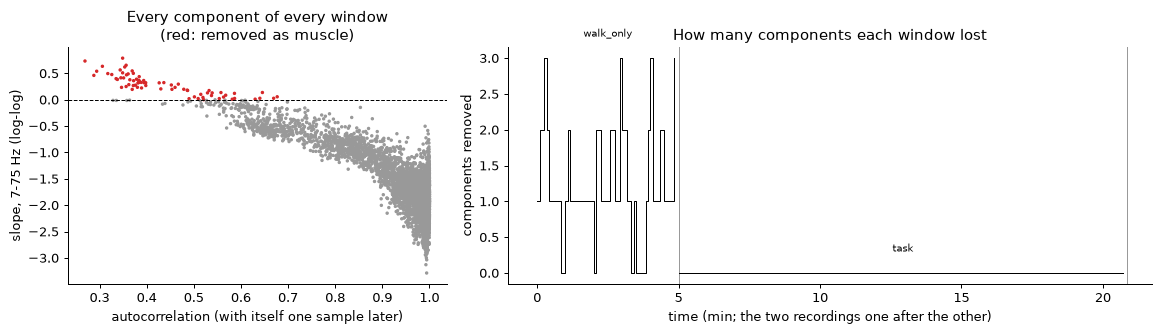

In [22]:
# ---- 3.8 Auto-CCA: find the muscle components, 10 s at a time, and remove them ------------------------------------------------------
from scipy.linalg import eigh                                # the eigenvalue problem that CCA solves
from scipy.signal import welch                               # spectra


def auto_cca(raw):
    """BSS-CCA (De Clercq et al., 2006) with the slope rule (Janani et al., 2018), in windows of CCA_WINDOW_S that overlap by half.
    Returns a cleaned copy (only the good channels other than Pz change) and one row per component of each window."""
    channels = [ch for ch in raw.copy().pick('eeg').ch_names if ch not in raw.info['bads'] and ch != 'Pz']   # Pz is all zeros here
    x = raw.get_data(picks=channels)
    n = int(CCA_WINDOW_S * sfreq)
    starts = list(range(0, x.shape[1] - n, n // 2)) + [x.shape[1] - n]   # the last window ends with the recording
    cleaned, weight, rows = np.zeros_like(x), np.zeros(x.shape[1]), []
    for k, start in enumerate(starts):
        piece = x[:, start:start + n]
        mean = piece.mean(axis=1, keepdims=True)
        now, before = piece[:, 1:] - mean, piece[:, :-1] - mean          # the signal, and the same signal one sample earlier
        cross = now @ before.T
        autocorrelation, unmixing = eigh((cross + cross.T) / 2, (now @ now.T + before @ before.T) / 2)
        order = np.argsort(autocorrelation)[::-1]                        # component 0: the most similar to itself one sample later
        autocorrelation, unmixing = autocorrelation[order], unmixing[:, order]
        components = unmixing.T @ (piece - mean)
        f, power = welch(components, fs=sfreq, nperseg=int(2 * sfreq))
        band = (f >= CCA_SLOPE_BAND[0]) & (f <= CCA_SLOPE_BAND[1])
        slope = np.polyfit(np.log10(f[band]), np.log10(power[:, band]).T, 1)[0]   # a straight line on the log-log spectrum
        muscle = slope > CCA_SLOPE
        mixing = np.linalg.inv(unmixing.T)                               # column j: how component j appears at each channel
        taper = np.hanning(n)                                            # each window fades in and out: the windows blend smoothly
        if k == 0:
            taper[:n // 2] = 1                                           # (except at the start and at the end of the recording)
        if k == len(starts) - 1:
            taper[n // 2:] = 1
        cleaned[:, start:start + n] += taper * (mixing[:, ~muscle] @ components[~muscle] + mean)
        weight[start:start + n] += taper
        rows += [(start / sfreq, j, a, s, m) for j, (a, s, m) in enumerate(zip(autocorrelation, slope, muscle))]
    out = raw.copy()
    out[channels] = cleaned / weight
    return out, pd.DataFrame(rows, columns=['window start (s)', 'component', 'autocorrelation', 'slope', 'muscle'])


def removed_share(name, channels, fmin, fmax):
    """The share of the power between fmin and fmax (Hz) that Auto-CCA removed from a recording (median over the channels)."""
    before = filtered_pz[name].get_data(picks=channels)
    f, power_before = welch(before, fs=sfreq, nperseg=int(2 * sfreq))
    _, power_removed = welch(before - analysis_pz[name].get_data(picks=channels), fs=sfreq, nperseg=int(2 * sfreq))
    band = (f >= fmin) & (f < fmax)
    return np.median(power_removed[:, band].sum(axis=1) / power_before[:, band].sum(axis=1))


analysis_pz, cca_tables = {}, {}                             # the analysis data from here on: filtered, then cleaned by Auto-CCA
for name, raw in filtered_pz.items():
    analysis_pz[name], cca_tables[name] = auto_cca(raw)
edge = [ch for ch in ['F7', 'F8', 'T7', 'T8'] if ch not in BAD_CHANNELS]   # the temples: muscles
back = [ch for ch in ['O1', 'O2', 'P3', 'P4'] if ch not in BAD_CHANNELS][:2]   # the back of the head (alpha): O1 and O2 if recorded
for name, table in cca_tables.items():
    per_window = table.groupby('window start (s)')['muscle'].sum()
    print(f'{name:10s} {len(per_window):3d} windows; components removed per window: median {per_window.median():.0f}, at most '
          f'{per_window.max()} of {table["component"].nunique()}. Power removed: 30-100 Hz at {"/".join(edge)} '
          f'{100 * removed_share(name, edge, 30, 100):.0f} %, 8-13 Hz (alpha) at {"/".join(back)} {100 * removed_share(name, back, 8, 13):.0f} %')

# Blinks are slow: Auto-CCA should leave them to ICA. The average blink at the electrode closest to the eyes, and what was removed of it
above_eyes = [ch for ch in ['Fp1', 'Fp2', 'F7', 'F8', 'Fz'] if ch not in BAD_CHANNELS][0]
peaks = mne.preprocessing.find_eog_events(filtered_pz['task'], ch_name=above_eyes)[:, 0] - filtered_pz['task'].first_samp
half = int(0.5 * sfreq)
peaks = peaks[(peaks > half) & (peaks < filtered_pz['task'].n_times - half)]
signal = filtered_pz['task'].get_data(picks=above_eyes)[0]
removed = signal - analysis_pz['task'].get_data(picks=above_eyes)[0]
average_blink = lambda x: np.mean([x[p - half:p + half] for p in peaks], axis=0)
print(f'The average blink at {above_eyes} ({len(peaks)} blinks): {np.ptp(average_blink(signal)) * 1e6:.0f} µV peak to peak; '
      f'Auto-CCA removed {np.ptp(average_blink(removed)) * 1e6:.1f} µV of it')

cca_table = pd.concat(cca_tables, names=['recording']).reset_index(level=0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), width_ratios=[1, 1.7])
ax1.scatter(cca_table['autocorrelation'], cca_table['slope'], s=3, c=np.where(cca_table['muscle'], 'tab:red', '0.6'))
ax1.axhline(CCA_SLOPE, color='k', ls='--', lw=0.8)
ax1.set(xlabel='autocorrelation (with itself one sample later)', ylabel=f'slope, {CCA_SLOPE_BAND[0]:g}-{CCA_SLOPE_BAND[1]:g} Hz (log-log)',
        title='Every component of every window\n(red: removed as muscle)')
offset = 0
for name, table in cca_tables.items():
    per_window = table.groupby('window start (s)')['muscle'].sum()
    ax2.step((offset + per_window.index) / 60, per_window.to_numpy(), where='post', color='k', lw=0.8)
    ax2.text((offset + filtered_pz[name].times[-1] / 2) / 60, per_window.max() + 0.3, name, ha='center', fontsize=8)
    offset += filtered_pz[name].times[-1]
    ax2.axvline(offset / 60, color='0.6', lw=0.8)
ax2.set(xlabel='time (min; the two recordings one after the other)', ylabel='components removed',
        title='How many components each window lost')
plt.tight_layout()
plt.show()

**Look.** In the walk without the task, Auto-CCA removes one component per 10-s window (median) and at most 3, which takes 11 % of the
power above 30 Hz at the temples and nothing of the alpha band at O1 and O2. In the task it removes nothing: in none of its 190 windows
does a component have a spectrum that does not fall with frequency (right: zero after the first recording; left: the red points, above
the dashed line, all come from the walk without the task). Cell 3.8 (continued) shows the same: before and after are identical, and the
removed part is zero. The threshold `CCA_SLOPE = 0` (cell 0.3) was chosen on seated data; walking will need its own. The left figure shows
why the two measures go together: each point is a component of one window, and the less a component resembles itself one sample later,
the flatter its spectrum. The average blink printed above is not a real test here: while walking, `find_eog_events` also fires at the
steps (cell 4.2).

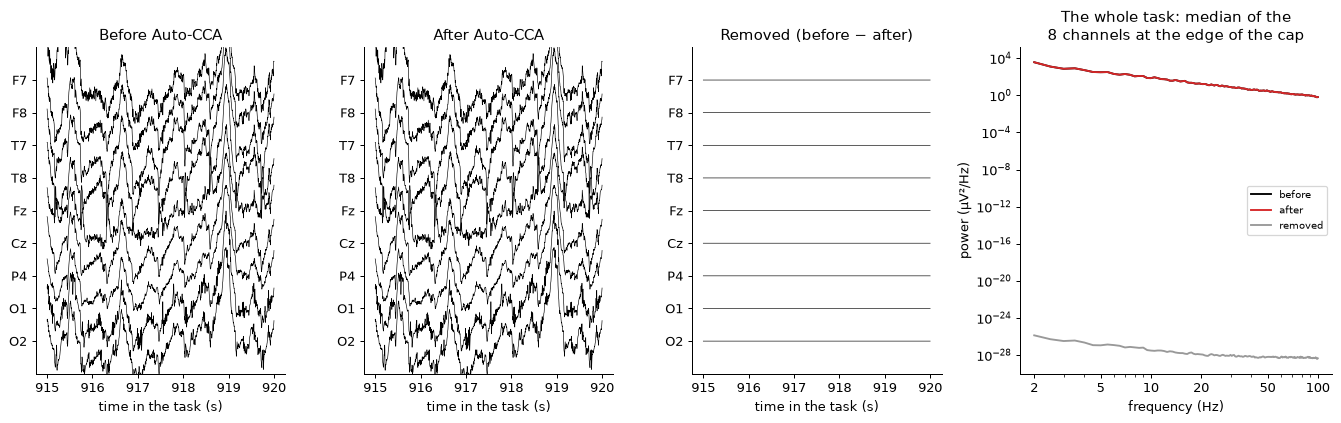

In [23]:
# ---- 3.8 (continued) The muscle burst of cell 3.2: before, after, and what Auto-CCA removed -----------------------------------------
show = [ch for ch in ['F7', 'F8', 'T7', 'T8', 'Fz', 'Cz', 'P4', 'O1', 'O2'] if ch not in BAD_CHANNELS]   # Pz is still all zeros
gap = 150                                                    # µV between two traces, the same in the three panels
before = filtered_pz['task'].copy().crop(muscle_start, muscle_start + 5).get_data(picks=show) * 1e6
after = analysis_pz['task'].copy().crop(muscle_start, muscle_start + 5).get_data(picks=show) * 1e6
t = muscle_start + np.arange(before.shape[1]) / sfreq
fig, axes = plt.subplots(1, 4, figsize=(15, 4.8), width_ratios=[1, 1, 1, 1.25])
for ax, (title, data) in zip(axes, [('Before Auto-CCA', before), ('After Auto-CCA', after), ('Removed (before − after)', before - after)]):
    for k, y in enumerate(data):
        ax.plot(t, y - y.mean() - gap * k, color='k', lw=0.5)
    ax.set(title=title, yticks=-gap * np.arange(len(show)), yticklabels=show, ylim=(-gap * len(show), gap), xlabel='time in the task (s)')

edges = [ch for ch in ['Fp1', 'Fp2', 'F7', 'F8', 'T7', 'T8', 'O1', 'O2'] if ch not in BAD_CHANNELS]   # the edge of the cap
whole_before = filtered_pz['task'].get_data(picks=edges)
whole_after = analysis_pz['task'].get_data(picks=edges)
for label, data, color in [('before', whole_before, 'k'), ('after', whole_after, 'tab:red'), ('removed', whole_before - whole_after, '0.6')]:
    f, power = welch(data, fs=sfreq, nperseg=int(2 * sfreq))
    inside = (f >= 2) & (f <= 100)
    axes[3].loglog(f[inside], np.median(power[:, inside], axis=0) * 1e12, color=color, label=label)
axes[3].set(xlabel='frequency (Hz)', ylabel='power (µV²/Hz)', title=f'The whole task: median of the\n{len(edges)} channels at the edge of the cap')
axes[3].set_xticks([2, 5, 10, 20, 50, 100], ['2', '5', '10', '20', '50', '100'])
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Re-reference to the average

**What.** Choose the zero of the voltage. A voltage is always a difference between two points. The DSI-24 measures each electrode
relative to Pz (the online reference), so Pz itself is 0. We change to the **average reference**: from each channel, at each moment,
we subtract the mean of all good channels.

**Why.** With the Pz reference, every channel contains (minus) the activity at Pz, and electrodes close to Pz look small. The average
reference does not favour one electrode, and Pz gets its own signal back. ICLabel (step 6) was also trained on average-referenced data
(Pion-Tonachini et al., 2019). The bad channels must stay out of the average, or their noise would be copied into every channel: this is
why step 2 came first. MNE leaves out the channels listed in `raw.info['bads']` automatically, and it does not change them: P7
keeps its recorded values and stays marked as bad (cell 4.1 checks it).

**Limit.** The average reference assumes the electrodes cover the head well. With 19 electrodes the average is only an approximation of
a true zero, but it is the usual choice.

**How.** `raw.set_eeg_reference('average')`.

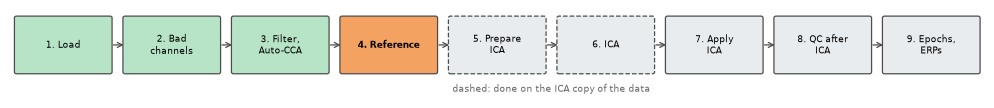

In [29]:
pipeline_map(4)

In [24]:
# ---- 4.1 Re-reference the analysis data to the average of the good electrodes -------------------------------------------------------
print(f'Before: largest absolute value of Pz = {np.abs(analysis_pz["task"].get_data(picks="Pz")).max() * 1e6:.3f} µV')
analysis = {name: raw.copy().set_eeg_reference('average') for name, raw in analysis_pz.items()}
good_all = [ch for ch in analysis['task'].copy().pick('eeg').ch_names if ch not in BAD_CHANNELS]   # good channels, with Pz
total = analysis['task'].get_data(picks=good_all).sum(axis=0)
print(f'After:  Pz varies with SD {analysis["task"].get_data(picks="Pz").std() * 1e6:.1f} µV; '
      f'sum of the {len(good_all)} good channels = {np.abs(total).max() * 1e6:.1e} µV (zero at every sample)')
if BAD_CHANNELS:
    same = all(np.array_equal(analysis_pz[name].get_data(picks=BAD_CHANNELS), analysis[name].get_data(picks=BAD_CHANNELS))
               for name in analysis)
    print(f'Bad channels {analysis["task"].info["bads"]}: still marked, left out of the average, and not changed by it: {same}')

Before: largest absolute value of Pz = 0.000 µV
After:  Pz varies with SD 174.1 µV; sum of the 17 good channels = 7.2e-12 µV (zero at every sample)
Bad channels ['C4', 'P7']: still marked, left out of the average, and not changed by it: True


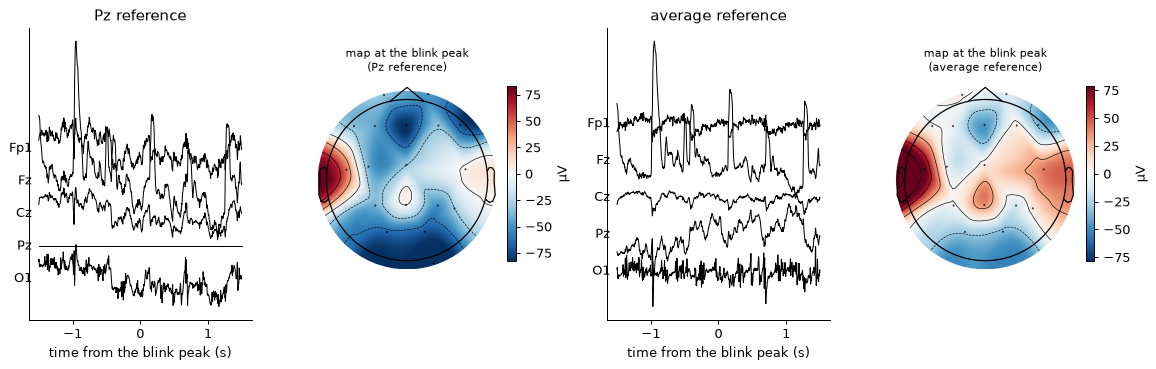

In [25]:
# ---- 4.2 The same blink, seen with the two references -----------------------------------------------------------------------------
frontal = [ch for ch in ['Fp1', 'Fp2', 'F7', 'F8', 'Fz'] if ch not in BAD_CHANNELS][0]   # the good electrode closest to the eyes
blink_events = mne.preprocessing.find_eog_events(analysis['task'], ch_name=frontal)   # one event at the peak of each blink
blink = (blink_events[len(blink_events) // 2, 0] - analysis['task'].first_samp) / sfreq   # one blink in the middle of the task
show = ['Fp1', 'Fz', 'Cz', 'Pz', 'O1']
fig = plt.figure(figsize=(13, 4.2))
for col, (label, data) in enumerate([('Pz reference', analysis_pz['task']), ('average reference', analysis['task'])]):
    piece = data.copy().crop(blink - 1.5, blink + 1.5)
    ax = fig.add_subplot(1, 4, 2 * col + 1)
    for k, ch in enumerate(show):
        ax.plot(piece.times - 1.5, piece.get_data(picks=ch)[0] * 1e6 - 120 * k, color='k', lw=0.8)
        ax.text(-1.6, -120 * k, ch, ha='right', va='center')
    ax.set(title=label, xlabel='time from the blink peak (s)', yticks=[])
    peak = data.copy().pick(good_all).crop(blink, blink)    # all good channels at the blink peak
    ax = fig.add_subplot(1, 4, 2 * col + 2)
    im, _ = mne.viz.plot_topomap(peak.get_data()[:, 0] * 1e6, peak.info, axes=ax, show=False, cmap='RdBu_r')
    plt.colorbar(im, ax=ax, shrink=0.6, label='µV')
    ax.set_title(f'map at the blink peak\n({label})', fontsize=9)
plt.tight_layout()
plt.show()

**Look.** While walking, `find_eog_events` does not find only blinks: it finds 441 events in the 15.9 min of the task (28 per minute),
against 48 in the seated blocks of this participant (3 per minute), because the steps cross its threshold too. The event in the middle of
the task, at time 0 here, is not a blink: the map at that moment is not the frontal map of a blink (compare with cell 1.7). The cells
that use the blinks of the task later (5.2, 6.9, 7.2) find mostly steps. Detecting the blinks during walking is one of the steps to tune
later.

## 5. Prepare the data used to train ICA

**What.** Make a copy of the analysis data with a high-pass at 1 Hz, the **ICA copy** (1–100 Hz). On this copy only, mark the few QC
periods of step 2 that are too gross for ICA to learn from.

**Why a copy at 1 Hz.** ICA (step 6) needs the opposite of what the ERPs need. Slow drifts make the sources look less independent (they all go up
and down with the drift), and this makes it harder for ICA to find a good solution (MNE documentation). A high-pass at 1 Hz is recommended:
Winkler et al. (2015) found that cut-offs of 1–2 Hz consistently gave good results, and Klug & Gramann (2021) recommend up to 2 Hz for mobile
experiments. But 1 Hz is far above what the N400 and the LPC tolerate (cell 3.5). So the analysis data keep 0.1–100 Hz for the ERPs, and the
ICA copy is used **only** to train ICA. It keeps the frequencies up to 100 Hz because ICLabel looks at them to recognize the muscles. Step 7
applies the ICA solution to the analysis data, the same Auto-CCA-cleaned data the copy came from.

**Why leave some periods out.** ICA assumes that the sources mix in the same way during the whole recording. A few huge, unusual artifacts
(an electrode that loses contact, an electrode pop, a strong movement) can capture components of their own and spoil the decomposition.
Blinks are the opposite case: they are frequent and always look the same, and ICA must see them to learn the blink component. So we leave
out only the gross QC periods (`ICA_HOLDOUT_RATIO` in cell 0.3), never the blinks.

**How.** `raw.filter(1, 100)` makes the ICA copy from the analysis data, which are already filtered at 0.1–100 Hz, cleaned by Auto-CCA and average-referenced:
what it adds is the 1 Hz high-pass. The QC annotations of step 2 come along. On the ICA copy only, each period left out gets a second
annotation starting with `BAD_ICA_` (`QC_large_amplitude` gives `BAD_ICA_large_amplitude`), without `ch_names`, because ICA uses all the
channels at once. `ica.fit(raw, reject_by_annotation=True)` (step 6) then skips these periods without deleting any sample. The analysis data
never get a `BAD_ICA_` annotation: they keep their QC annotations and their complete time axis.

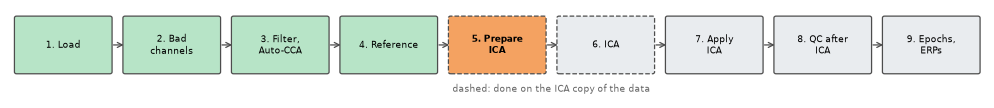

In [32]:
pipeline_map(5)

In [26]:
# ---- 5.0 The ICA copy: the analysis data with a high-pass at 1 Hz -------------------------------------------------------------------
# The analysis data already stop at 100 Hz and are average-referenced: what this adds is the 1 Hz high-pass
ica_copy = {name: raw.copy().filter(*ICA_BAND, picks='eeg') for name, raw in analysis.items()}
print(f'ICA copy {ICA_BAND[0]:g}-{ICA_BAND[1]:g} Hz, used only to train ICA:', ', '.join(ica_copy))

ICA copy 1-100 Hz, used only to train ICA: walk_only, task


In [27]:
# ---- 5.1 The QC periods ICA should not learn from: BAD_ICA_ annotations, on the ICA copy only ---------------------------------------
held_out = ((qc_table['description'] == 'QC_contact') | (qc_table['channels'] == 'all')
            | (qc_table['ratio'] >= ICA_HOLDOUT_RATIO))      # a lost contact, the whole scalp, or a very large channel
qc_table['held out from ICA'] = held_out
for raw in ica_copy.values():                                # (running this cell again adds nothing twice)
    raw.annotations.delete([i for i, d in enumerate(raw.annotations.description) if d.startswith('BAD_ICA_')])
for p in qc_table[held_out].itertuples():
    raw = ica_copy[p.recording]
    raw.annotations.append(onset=raw.first_time + p.onset, duration=p.duration,
                           description='BAD_ICA_' + p.description.removeprefix('QC_'))   # no ch_names: ICA uses all the channels at once
ica_training = mne.concatenate_raws([raw.copy() for raw in ica_copy.values()])   # walking without the task + task
held_s = sum(a['duration'] for a in ica_training.annotations if a['description'].startswith('BAD_ICA_'))
print(f'{held_out.sum()} of {len(qc_table)} QC periods left out of ICA training: {held_s:.0f} s of the {ica_training.times[-1]:.0f} s of '
      f'the ICA copy. The analysis data keep their QC annotations, and every sample.')
qc_table[held_out].round(2)

6 of 24 QC periods left out of ICA training: 110 s of the 1252 s of the ICA copy. The analysis data keep their QC annotations, and every sample.


,recording,part,onset,duration,description,channels,ratio,held out from ICA
4,task,block1,125.00,15.0,QC_large_amplitude,F8,5.42,True
5,task,block3,492.55,25.0,QC_large_amplitude,Fz,6.58,True
9,task,block4,701.79,15.0,QC_large_amplitude,Fz,6.65,True
16,task,block1,110.00,10.0,QC_large_amplitude,T7,5.02,True
18,task,block2,451.93,10.0,QC_large_amplitude,T7,5.12,True
22,task,block2,376.93,35.0,QC_large_amplitude,T8,8.65,True


**Look.** Six of the 24 QC periods are left out of ICA training, the ones above 5 times the typical amplitude of their window
(`ICA_HOLDOUT_RATIO`): T8 in block 2 (8.7 times, 35 s), Fz in blocks 3 and 4 (6.6 and 6.7 times), F8 in block 1 (5.4 times), and T7 in
blocks 1 and 2 (5.0 and 5.1 times). Together they are 110 s of the 20.9 min of the ICA copy. The 18 others, 3.0 to 4.5 times the typical
amplitude, stay in the training data. The `BAD_ICA_` annotation exists only on the ICA copy: the analysis data keep `QC_large_amplitude`
and every sample.

In [28]:
# ---- 5.2 Are the blinks still in the training data, and is there enough data for ICA? -----------------------------------------------
blink_times = mne.preprocessing.find_eog_events(ica_training, ch_name=frontal)[:, 0] / sfreq   # the time of each blink (s)
held_periods = [(a['onset'], a['onset'] + a['duration']) for a in ica_training.annotations if a['description'].startswith('BAD_ICA_')]
inside = sum(any(start <= t < end for start, end in held_periods) for t in blink_times)
print(f'{len(blink_times)} blinks in the ICA copy, {inside} of them in a period left out: ICA learns from {len(blink_times) - inside}')
n_kept = ica_training.get_data(picks=good_all[0], reject_by_annotation='omit').shape[1]   # the samples outside every BAD annotation
n_channels = len(good_all)
print(f'{n_kept:,} samples for ICA ({n_kept / sfreq / 60:.1f} min); the rule of thumb asks for at least {30 * n_channels ** 2:,} '
      f'(30 × {n_channels}²)')

68 blinks in the ICA copy, 4 of them in a period left out: ICA learns from 64
339,646 samples for ICA (18.9 min); the rule of thumb asks for at least 8,670 (30 × 17²)


## 6. ICA: find the eye and muscle components

**What.** Each electrode records a **mixture** of many sources: brain areas, eye movements, muscles, electrical noise. Independent
component analysis (ICA) finds weights that **unmix** the channels into components, assuming the sources are statistically
independent and not Gaussian (Makeig et al., 1996; Hyvärinen & Oja, 2000). Each component has:

- a **topography**: how strongly it appears at each electrode (where it is);
- a **time course**: its activity over time (when it is active).

In matrix form: **channels = A × components**. `A` is the **mixing matrix**: its column *k* is the topography of component *k*. ICA estimates the
**unmixing matrix** `W`, the weights: **components = W × channels**. `A` and `W` combine the electrodes at one moment at a time: they know nothing
about the time course or the frequencies of the signal (step 7 uses this).

**Why.** We can then remove the eye and muscle components and keep the others, instead of throwing away every trial that contains a
blink.

**How many components?** As many as there are independent signals in the data, the **rank** of the good channels: here 17 (the 19
electrodes minus the bad C4 and P7; Pz counts, it has a signal since step 4) minus 1 lost to the average reference (the channels sum to zero, so
the last one is known from the others) = **16**. Cell 6.2 asks MNE for this rank instead of counting.

**How.** `mne.preprocessing.ICA(n_components, method='picard')`, then `ica.fit(ica_training, reject_by_annotation=True)`: ICA leaves out
the bad channels and skips the `BAD_ICA_` periods of step 5.

**Which components to remove.** Cells 6.5 to 6.9 collect several independent pieces of evidence for each component, remove a
component only when two of them agree, and check the decision on a copy before step 7 applies it.

**Animation 6.1.** First, ICA on a made-up example with two sources (blinks and an alpha rhythm) recorded by two electrodes.

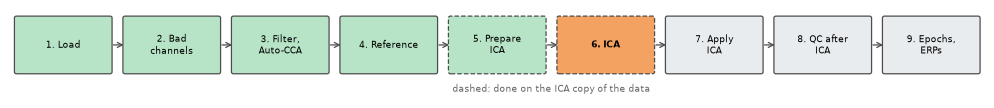

In [36]:
pipeline_map(6)

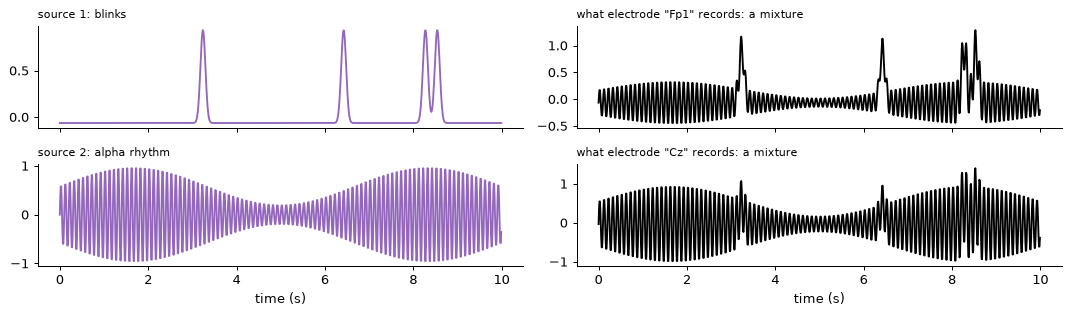

In [29]:
# ---- 6.1 How ICA unmixes: two sources, two electrodes --------------------------------------------------------------------------------
rng = np.random.default_rng(1)
sf_demo = 100
t_demo = np.arange(0, 20, 1 / sf_demo)                       # 20 s at 100 Hz
blinks = sum(np.exp(-((t_demo - b) / 0.08) ** 2) for b in rng.uniform(0.5, 19.5, 9))   # source 1: blinks, rare large peaks
alpha = np.sin(2 * np.pi * 10 * t_demo) * (0.6 + 0.4 * np.sin(2 * np.pi * 0.15 * t_demo))   # source 2: a 10 Hz rhythm
sources = np.vstack([blinks - blinks.mean(), alpha])
mixing = np.array([[1.0, 0.4],                               # "Fp1" records a lot of the blinks and a little alpha
                   [0.5, 1.0]])                              # "Cz" records some blinks and a lot of alpha
recorded = mixing @ sources

# ICA, part 1: whitening. The two channels are made uncorrelated, with the same variance.
centred = recorded - recorded.mean(axis=1, keepdims=True)
eigenvalues, eigenvectors = np.linalg.eigh(np.cov(centred))
white = eigenvectors @ np.diag(eigenvalues ** -0.5) @ eigenvectors.T @ centred


# ICA, part 2: turn the whitened data until the two outputs are as far from Gaussian as possible.
def rotate(angle):
    a = np.deg2rad(angle)
    return np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]]) @ white


angles = np.arange(0, 180, 1)
non_gaussian = np.array([np.abs(kurtosis(rotate(a), axis=1)).sum() for a in angles])   # |kurtosis|: 0 for a Gaussian signal

fig, axes = plt.subplots(2, 2, figsize=(12, 3.6), sharex=True)
for k, (src, rec, ch) in enumerate(zip(sources, recorded, ['Fp1', 'Cz'])):
    axes[k, 0].plot(t_demo[:1000], src[:1000], color='tab:purple')
    axes[k, 0].set_title(f'source {k + 1}: {"blinks" if k == 0 else "alpha rhythm"}', fontsize=9, loc='left')
    axes[k, 1].plot(t_demo[:1000], rec[:1000], color='k')
    axes[k, 1].set_title(f'what electrode "{ch}" records: a mixture', fontsize=9, loc='left')
axes[1, 0].set_xlabel('time (s)')
axes[1, 1].set_xlabel('time (s)')
plt.tight_layout()
plt.show()

In [30]:
# ---- 6.1 (continued) Animation: ICA turns the data until the outputs are independent ------------------------------------------------
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.6), width_ratios=[1, 1.8, 1.2])
frames = list(range(0, 91, 6))                               # turning by 90° only swaps the two outputs


def draw(k):
    angle = frames[k]
    outputs = rotate(angle)
    for ax in (ax1, ax2, ax3):
        ax.clear()
    ax1.scatter(outputs[0, ::3], outputs[1, ::3], s=2, color='0.4')
    ax1.set(xlim=(-4, 7), ylim=(-4, 7), xlabel='output 1', ylabel='output 2', title='the data, turned', aspect='equal')
    ax2.plot(t_demo[:1000], outputs[0, :1000] + 4, color='tab:blue')
    ax2.plot(t_demo[:1000], outputs[1, :1000] - 2, color='tab:orange')
    ax2.set(yticks=[], xlabel='time (s)', title='the two outputs')
    ax3.plot(angles[angles <= 90], non_gaussian[angles <= 90], color='k')
    ax3.axvline(angle, color='tab:red')
    ax3.set(xlabel='rotation (degrees)', ylabel='non-Gaussianity', title=f'rotation {angle}°')


anim = animation.FuncAnimation(fig, draw, frames=len(frames), interval=400)
show_animation(fig, anim)
best = angles[np.argmax(non_gaussian)]
print(f'Most non-Gaussian rotation: {best}°. At that angle, output 1 and output 2 are the blinks and the alpha rhythm again.')

Most non-Gaussian rotation: 6°. At that angle, output 1 and output 2 are the blinks and the alpha rhythm again.


**Look.** At most angles each output is still a mixture of blinks and alpha. When the non-Gaussianity curve (right) reaches a peak,
one output contains only the blinks and the other only the alpha rhythm: ICA has recovered the sources without knowing them. Real ICA does
the same in 16 dimensions instead of 2.

In [31]:
# ---- 6.2 Fit ICA on the ICA copy, without its BAD_ICA_ periods ----------------------------------------------------------------------
# As many components as the rank of the good, average-referenced channels (a relative tolerance: the default one sometimes counts the
# 1e-15 noise left by the average reference)
n_components = mne.compute_rank(ica_training, tol=1e-6, tol_kind='relative')['eeg']
print(f'{len(good_all)} good channels (left out: {BAD_CHANNELS}); the rank of the data, so the number of components: {n_components}')
ica = mne.preprocessing.ICA(n_components=n_components, method=ICA_METHOD, fit_params=ICA_FIT_PARAMS,
                            random_state=ICA_SEED, max_iter=2000)
ica.fit(ica_training, reject_by_annotation=True)             # skips the BAD_ICA_ periods and the data gaps (about 30 s)
print(f'ICA learned from {ica.n_samples_ / sfreq / 60:.1f} of the {ica_training.n_times / sfreq / 60:.1f} min of the ICA copy')
print(ica)

17 good channels (left out: ['C4', 'P7']); the rank of the data, so the number of components: 16
ICA learned from 18.9 of the 20.9 min of the ICA copy
<ICA | raw data decomposition, method: picard (fit in 31 iterations on 339646 samples), 16 ICA components (17 PCA components available), channel types: eeg, no sources marked for exclusion>


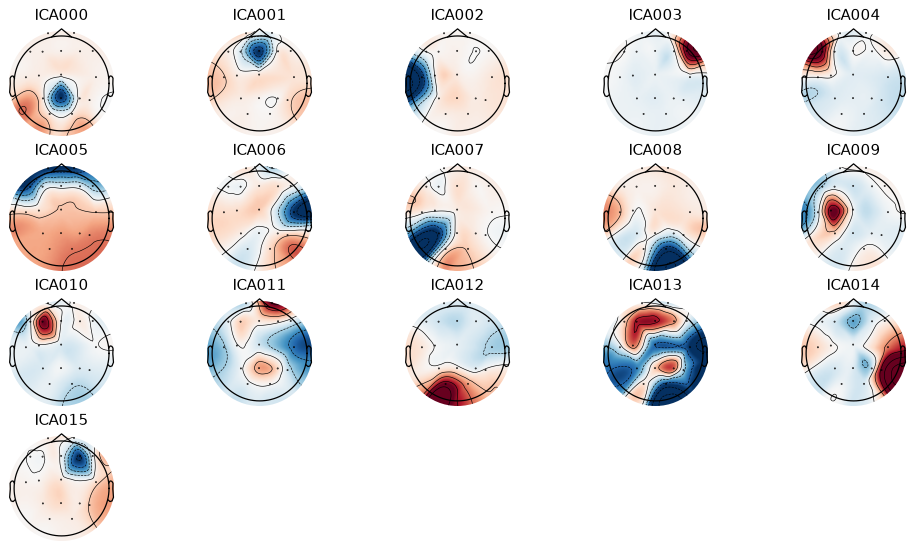

In [32]:
# ---- 6.3 The topographies of the components ----------------------------------------------------------------------------------------
fig = ica.plot_components(show=False)
fig.set_size_inches(11, 6)
plt.show()

**Look.** A blink component has a strong, symmetric topography at the front (Fp1, Fp2). A horizontal eye movement component is
opposite on the left and right at the front (F7 against F8, or Fp1 against Fp2). A muscle component is often concentrated on one electrode at the edge of
the cap (temporal or frontal). Brain components often have smooth topographies, with one positive and one negative area.

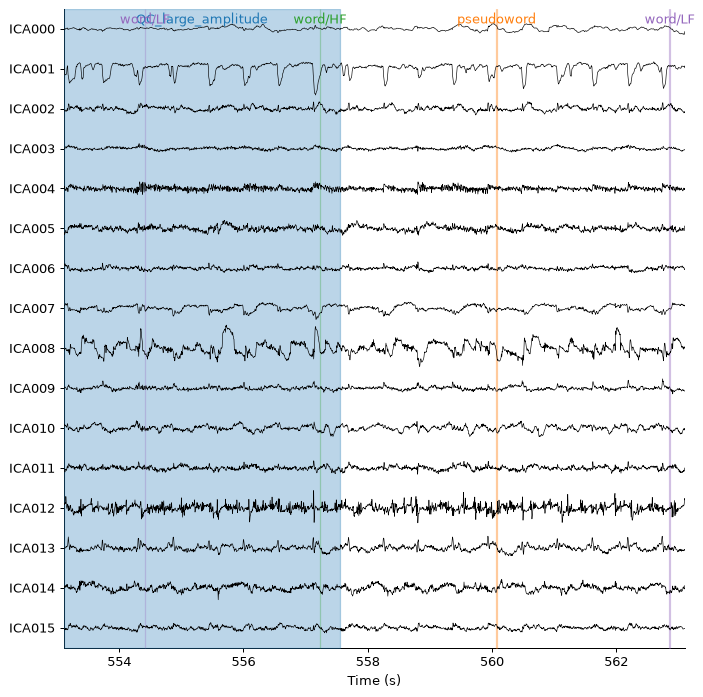

In [33]:
# ---- 6.4 The time courses of the components (10 s of the task) ---------------------------------------------------------------------
ica.plot_sources(ica_copy['task'], start=blink - 5, stop=blink + 5, show_scrollbars=False,
                 title='Time courses of the components, around the blink of step 4');

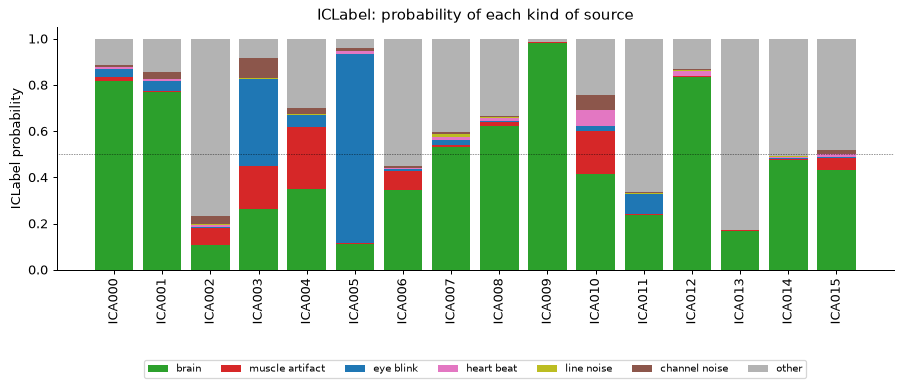

,brain,muscle artifact,eye blink,heart beat,line noise,channel noise,other
ICA000,0.82,0.02,0.04,0.01,0.00,0.01,0.11
ICA001,0.77,0.00,0.04,0.01,0.00,0.03,0.14
ICA002,0.11,0.08,0.00,0.01,0.00,0.04,0.77
ICA003,0.26,0.19,0.38,0.00,0.00,0.09,0.08
ICA004,0.35,0.27,0.05,0.00,0.00,0.03,0.30
ICA005,0.11,0.00,0.82,0.01,0.00,0.01,0.04
ICA006,0.34,0.08,0.00,0.00,0.00,0.01,0.55
ICA007,0.53,0.01,0.02,0.01,0.01,0.01,0.40
ICA008,0.62,0.02,0.00,0.02,0.01,0.00,0.33
ICA009,0.98,0.00,0.00,0.00,0.00,0.00,0.01


In [34]:
# ---- 6.5 ICLabel: what kind of source is each component? ---------------------------------------------------------------------------
CLASSES = ['brain', 'muscle artifact', 'eye blink', 'heart beat', 'line noise', 'channel noise', 'other']
probabilities = np.array(iclabel_label_components(ica_training, ica, inplace=False))   # (components, 7 classes)
labels = pd.DataFrame(probabilities, columns=CLASSES, index=[f'ICA{i:03d}' for i in range(ica.n_components_)])

fig, ax = plt.subplots(figsize=(12, 3.5))
bottom = np.zeros(len(labels))
for cls, color in zip(CLASSES, ['tab:green', 'tab:red', 'tab:blue', 'tab:pink', 'tab:olive', 'tab:brown', '0.7']):
    ax.bar(labels.index, labels[cls], bottom=bottom, color=color, label=cls)
    bottom += labels[cls].to_numpy()
ax.axhline(0.5, color='k', lw=0.5, ls=':')
ax.set(ylabel='ICLabel probability', title='ICLabel: probability of each kind of source')
ax.tick_params(axis='x', rotation=90)
ax.legend(ncol=7, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.35))
plt.show()
labels.round(2)

**How.** ICLabel (Pion-Tonachini et al., 2019; Python version: Li et al., 2022) is a classifier trained on thousands of components labelled
by experts. It looks at each component's topography, spectrum and autocorrelation, and gives the probability of 7 kinds of source.
`iclabel_label_components(raw, ica)` expects data filtered at 1–100 Hz and average-referenced, which is exactly our ICA copy.

**Caution.** ICLabel is useful, but it is not the truth. It was trained on wet, high-density EEG, and with 19 dry electrodes its labels are
advice. It also makes a known mistake with the eyes: at the start of each eye movement, the muscles that turn the eye produce a sharp burst
of fast activity, the **saccadic spike potential** (about 20 to 90 Hz, largest near the eyes; Keren et al., 2010). A component that carries
it has a spectrum like a muscle, although it comes from the eyes, and it may be labelled muscle. So ICLabel is one opinion: cell 6.6 adds
other evidence, and cell 6.7 removes a component only when two pieces of evidence agree.

c:\Users\s\PSY2007D-UdeM\.venv_psy2007\Lib\site-packages\mne\time_frequency\psd.py:292: UserWarning: nperseg = 2048 is greater than input length  = 1500, using nperseg = 1500
  return _func(*args, **kwargs)


Fp1   the most correlated components: ICA005 (r = -0.79), ICA001 (r = +0.39), ICA000 (r = +0.34)
Fp2   the most correlated components: ICA011 (r = +0.69), ICA005 (r = -0.62), ICA006 (r = -0.25)
HEOG  the most correlated components: ICA004 (r = +0.68), ICA003 (r = -0.63), ICA009 (r = -0.25)
Muscle score, highest: ICA004 (0.62), ICA003 (0.53), ICA012 (0.48), ICA005 (0.26), ICA009 (0.14)


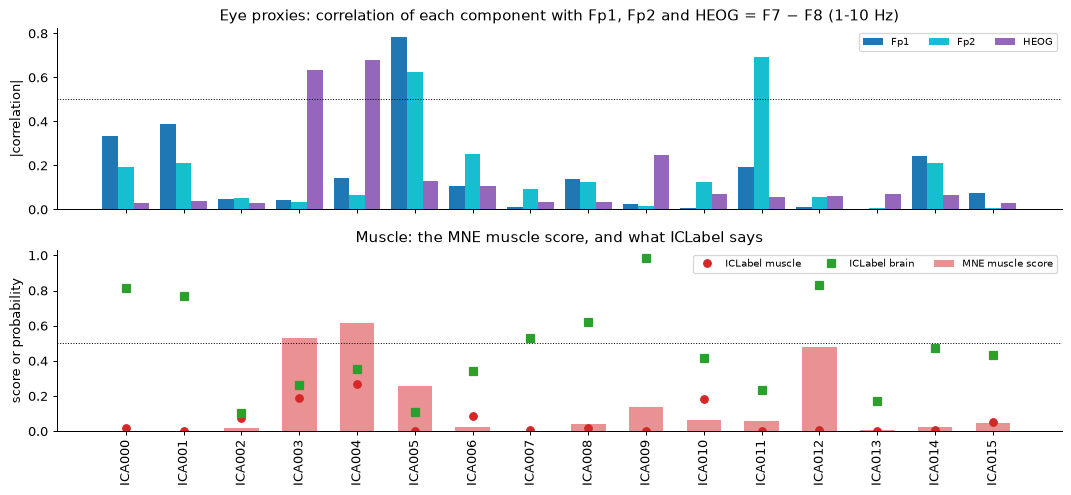

In [35]:
# ---- 6.6 More evidence: the eye proxies and the muscle score of every component -----------------------------------------------------
# No electrode beside the eyes (EOG) on the DSI-24: proxies, on a temporary copy of the ICA training data. Fp1 and Fp2 sit above the
# eyes (blinks, vertical movements); HEOG = F7 − F8, a virtual bipolar channel, compares the left and right sides (horizontal movements)
heog = not {'F7', 'F8'} & set(BAD_CHANNELS)                 # HEOG needs both F7 and F8
ocular = ica_training.copy()                                 # the analysis data and the ICA copy are not changed
if heog:
    ocular = mne.set_bipolar_reference(ocular, anode='F7', cathode='F8', ch_name='HEOG', drop_refs=False)
    ocular.set_channel_types({'HEOG': 'eog'})
proxies = [ch for ch in ['Fp1', 'Fp2'] if ch not in BAD_CHANNELS] + ['HEOG'] * heog
eye_r = pd.DataFrame({proxy: ica.find_bads_eog(ocular, ch_name=proxy)[1] for proxy in proxies},   # Pearson r, filtered 1-10 Hz, every
                     index=labels.index)                                                       # component, BAD_ICA_ periods left out
muscle_score = pd.Series(ica.find_bads_muscle(ica_training)[1], index=labels.index)   # slope 7-45 Hz x edge of the cap x one spot
for proxy in proxies:
    ranked = eye_r[proxy].abs().sort_values(ascending=False).index[:3]
    print(f'{proxy:5s} the most correlated components: ' + ', '.join(f'{k} (r = {eye_r.loc[k, proxy]:+.2f})' for k in ranked))
ranked = muscle_score.sort_values(ascending=False).index[:5]
print('Muscle score, highest: ' + ', '.join(f'{k} ({muscle_score[k]:.2f})' for k in ranked))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.6), sharex=True)
x = np.arange(len(labels))
for j, (proxy, color) in enumerate(zip(proxies, ['tab:blue', 'tab:cyan', 'tab:purple'])):
    ax1.bar(x + (j - (len(proxies) - 1) / 2) * 0.27, eye_r[proxy].abs(), 0.27, color=color, label=proxy)
ax1.axhline(EYE_CORR, color='k', ls=':', lw=0.8)
ax1.set(ylabel='|correlation|', title='Eye proxies: correlation of each component with Fp1, Fp2 and HEOG = F7 − F8 (1-10 Hz)')
ax1.legend(fontsize=8, ncol=3)
ax2.bar(x, muscle_score, 0.6, color='tab:red', alpha=0.5, label='MNE muscle score')
ax2.plot(x, labels['muscle artifact'], 'o', color='tab:red', label='ICLabel muscle')
ax2.plot(x, labels['brain'], 's', color='tab:green', label='ICLabel brain')
ax2.axhline(MUSCLE_SCORE, color='k', ls=':', lw=0.8)
ax2.set(ylabel='score or probability', title='Muscle: the MNE muscle score, and what ICLabel says', xticks=x, xticklabels=labels.index)
ax2.tick_params(axis='x', rotation=90)
ax2.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

**Look.** Top: ICA005 follows Fp1 and Fp2 (r = −0.79 and −0.62; the sign of a component is arbitrary): the blinks. ICA011 follows Fp2
alone (r = +0.69). HEOG = F7 − F8 is followed by ICA004 (r = +0.68) and ICA003 (r = −0.63), but ICA004 lives on F7 alone and ICA003 on
F8 alone (cell 6.3). F7 − F8 contains everything F7 and F8 record, so a component of one of them follows it whatever it is: this
correlation does not make them eye components. A proxy is evidence to check like any other.

Bottom: MNE's muscle score (Dharmaprani et al., 2016) combines three criteria: a spectrum that does not fall between 7 and 45 Hz, a map at
the edge of the cap, and a map concentrated on one spot. It is highest for ICA004 (0.62) and ICA003 (0.53), the components of F7 and F8,
and just below the threshold for ICA012 (0.48), which ICLabel calls brain (0.83). ICLabel calls no component muscle (at most 0.27), and
6 of the 16 brain. With MNE's default threshold (a score above 0.125), 5 of the 16 components would be called muscle: no single piece of
evidence is enough.

The steps have no class of their own. ICA001, whose map is near Fz, has a sharp wave at every step (cell 6.4): it is the step artifact of
Fz. ICLabel calls it brain (0.77), and none of the evidence of this notebook votes for it: the rule of cell 6.7 knows only the eyes and
the muscles.

### The decision: two pieces of evidence must agree

Each piece of evidence votes for one kind of artifact (thresholds in cell 0.3):

| Kind | Evidence | It votes when |
|---|---|---|
| eye | ICLabel (6.5) | the probability of "eye" is at least 0.5 (`ICLABEL_P`) |
| eye | eye proxies (6.6) | the correlation with Fp1, Fp2 or HEOG is at least 0.5, positive or negative (`EYE_CORR`) |
| eye | topography | the largest weight is at Fp1, Fp2, F7 or F8, and Fp1 and Fp2 are both large with the same sign (a blink), or the left and right of the forehead are both large with opposite signs (a horizontal movement) |
| muscle | ICLabel (6.5) | the probability of "muscle" is at least 0.5 |
| muscle | MNE muscle score (6.6) | the score is at least 0.5 (`MUSCLE_SCORE`) |

A component is **removed** when at least two votes of the same kind agree. It is only **reviewed**, which means kept unless you decide
otherwise after looking at it, when a vote is alone or when ICLabel gives it at least 0.3 of "brain" (`BRAIN_CAUTION`): removing a
component that is partly brain removes brain signal too. All the other components are **kept**. No probability alone removes a component,
and a class that is only ICLabel's second choice never reaches 0.5, so it never votes. The component numbers change from one participant
to the next: the rule looks at the evidence, never at a number.

In [36]:
# ---- 6.7 The decision ---------------------------------------------------------------------------------------------------------------
weights = ica.get_components() / np.abs(ica.get_components()).max(axis=0)   # each topography scaled so that its largest weight is ±1
names = ica.ch_names


def eye_shape(k):
    """'blink' if Fp1 and Fp2 both carry component k with the same sign; 'horizontal' if the left and the right of the forehead (Fp1 and
    Fp2, or F7 and F8) carry it with opposite signs. Only when its largest weight is at one of these four electrodes."""
    w = {ch: weights[names.index(ch), k] for ch in ['Fp1', 'Fp2', 'F7', 'F8'] if ch in names}
    big = {ch for ch, value in w.items() if abs(value) >= 0.5}
    if names[np.abs(weights[:, k]).argmax()] not in w:
        return ''
    if {'Fp1', 'Fp2'} <= big and w['Fp1'] * w['Fp2'] > 0:
        return 'blink'
    if any({a, b} <= big and w[a] * w[b] < 0 for a, b in [('Fp1', 'Fp2'), ('F7', 'F8')]):
        return 'horizontal'
    return ''


evidence = pd.DataFrame({'ICLabel_brain': labels['brain'], 'ICLabel_muscle': labels['muscle artifact'], 'ICLabel_eye': labels['eye blink']})
evidence = evidence.join(eye_r.add_prefix('corr_'))
evidence['mne_muscle_score'] = muscle_score
evidence['eye_shape'] = [eye_shape(k) for k in range(ica.n_components_)]
evidence.index.name = 'component'
votes = {'eye': {'ICLabel eye': evidence['ICLabel_eye'] >= ICLABEL_P,
                 'follows an eye proxy': eye_r.abs().max(axis=1) >= EYE_CORR,
                 'eye topography': evidence['eye_shape'] != ''},
         'muscle': {'ICLabel muscle': evidence['ICLabel_muscle'] >= ICLABEL_P,
                    'MNE muscle score': evidence['mne_muscle_score'] >= MUSCLE_SCORE}}


def decide(k):
    """The proposed class of component k, the decision (remove, review or keep) and the reason."""
    found = {kind: [name for name, vote in kind_votes.items() if vote.iloc[k]] for kind, kind_votes in votes.items()}
    kind = 'eye' if len(found['eye']) >= len(found['muscle']) else 'muscle'
    if not found[kind]:
        return labels.columns[labels.iloc[k].argmax()], 'keep', 'no artifact evidence'   # ICLabel's most likely class
    if kind == 'eye':
        r = eye_r.iloc[k].abs()
        kind += ' (' + (evidence['eye_shape'].iloc[k]
                        or ('horizontal' if r.get('HEOG', 0) > r.drop('HEOG', errors='ignore').max() else 'blink')) + ')'
    reason = ', '.join(found['eye'] + found['muscle'])
    brain = evidence['ICLabel_brain'].iloc[k]
    if brain >= BRAIN_CAUTION:                               # possibly brain: a person decides
        return kind, 'review', reason + f' (but ICLabel brain {brain:.2f})'
    if len(found[kind.split()[0]]) < 2:                      # one piece of evidence is not enough
        return kind, 'review', reason + ' (only one piece of evidence)'
    return kind, 'remove', reason


evidence = evidence.join(pd.DataFrame([decide(k) for k in range(ica.n_components_)], index=evidence.index,
                                      columns=['proposed_class', 'decision', 'reason']))
ica.exclude = [k for k in range(ica.n_components_) if evidence['decision'].iloc[k] == 'remove']
share = ica.get_explained_variance_ratio(ica_training, components=ica.exclude)['eeg'] if ica.exclude else 0.0
print(f'Proposed: remove {len(ica.exclude)} of {ica.n_components_} components (together {100 * share:.0f} % of the variance of the ICA '
      f'copy), review {(evidence["decision"] == "review").sum()}, keep the others. Cell 6.9 checks the proposal before step 7 applies it.')
evidence.round(2)

Proposed: remove 1 of 16 components (together 37 % of the variance of the ICA copy), review 3, keep the others. Cell 6.9 checks the proposal before step 7 applies it.


,ICLabel_brain,ICLabel_muscle,ICLabel_eye,corr_Fp1,corr_Fp2,corr_HEOG,mne_muscle_score,eye_shape,proposed_class,decision,reason
component,,,,,,,,,,,
ICA000,0.82,0.02,0.04,0.34,0.19,-0.03,0.00,,brain,keep,no artifact evidence
ICA001,0.77,0.00,0.04,0.39,-0.21,-0.04,0.00,,brain,keep,no artifact evidence
ICA002,0.11,0.08,0.00,0.05,0.05,-0.03,0.02,,other,keep,no artifact evidence
ICA003,0.26,0.19,0.38,-0.04,-0.03,-0.63,0.53,,eye (horizontal),review,"follows an eye proxy, MNE muscle score (only o..."
ICA004,0.35,0.27,0.05,-0.14,-0.07,0.68,0.62,,eye (horizontal),review,"follows an eye proxy, MNE muscle score (but IC..."
ICA005,0.11,0.00,0.82,-0.79,-0.62,-0.13,0.26,blink,eye (blink),remove,"ICLabel eye, follows an eye proxy, eye topography"
ICA006,0.34,0.08,0.00,0.11,-0.25,-0.11,0.03,,other,keep,no artifact evidence
ICA007,0.53,0.01,0.02,0.01,0.09,0.03,0.00,,brain,keep,no artifact evidence
ICA008,0.62,0.02,0.00,0.14,0.12,0.04,0.04,,brain,keep,no artifact evidence


**Look.** One row of evidence per component: this table is the record of the decision, and cell 10.1 saves it with the results. In P010
while walking, one component is removed: ICA005, a blink, with three votes (ICLabel, Fp1 and Fp2, and its map). ICA003 (F8) and ICA004
(F7) are only reviewed: each has one eye vote (HEOG) and one muscle vote (MNE's muscle score), so no kind reaches two votes, and ICLabel
gives ICA004 0.35 of "brain". ICA011 is reviewed with one eye vote (Fp2). The blink component alone carries 37 % of the variance of the
ICA copy. Seated, the same rule removed five components of this participant.

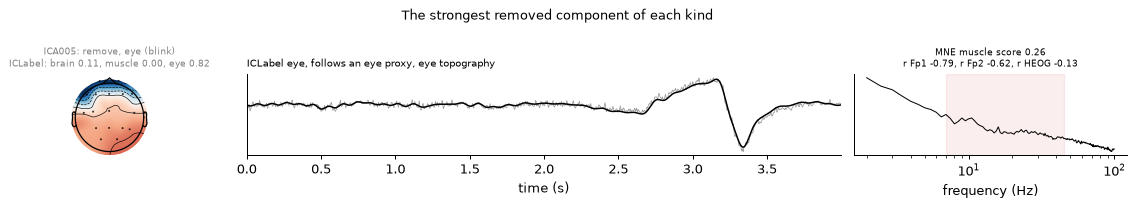

In [37]:
# ---- 6.8 A closer look: a blink, a horizontal eye movement, a muscle component ------------------------------------------------------
pieces = mne.make_fixed_length_epochs(ica_training, duration=4, preload=True)    # 4-s pieces, without the BAD_ICA_ periods
piece_sources = ica.get_sources(pieces).get_data()          # pieces x components x samples
slow_sources = mne.filter.filter_data(piece_sources, sfreq, 1, 10)   # their 1-10 Hz part: the band of the eye proxies
component_spectra = ica.get_sources(ica_training).compute_psd(fmin=2, fmax=100, picks='misc', n_fft=int(2 * sfreq))


def show_components(picks, title):
    """One row per component: its topography and ICLabel, 4 s of its time course (grey: all of it; black: its 1-10 Hz part), and its
    spectrum (log-log; shaded: the band of MNE's muscle slope). Eye components are shown where their 1-10 Hz part is largest, the
    others where they are largest."""
    fig, axes = plt.subplots(len(picks), 3, figsize=(13, 2.3 * len(picks)), width_ratios=[1, 2.4, 1.1], squeeze=False)
    for (ax_map, ax_time, ax_psd), k in zip(axes, picks):
        e = evidence.iloc[k]
        ica.plot_components(picks=k, axes=ax_map, colorbar=False, show=False)
        ax_map.set_title(f'{evidence.index[k]}: {e.decision}, {e.proposed_class}\nICLabel: brain {e.ICLabel_brain:.2f}, muscle '
                         f'{e.ICLabel_muscle:.2f}, eye {e.ICLabel_eye:.2f}', fontsize=7.5)
        focus = slow_sources if e.proposed_class.startswith('eye') else piece_sources
        best = np.ptp(focus[:, k], axis=-1).argmax()
        ax_time.plot(pieces.times, piece_sources[best, k], color='0.6', lw=0.6)
        ax_time.plot(pieces.times, slow_sources[best, k], color='k', lw=1.2)
        ax_time.set(yticks=[], xlim=(0, pieces.times[-1]), xlabel='time (s)')
        ax_time.set_title(e.reason, fontsize=8, loc='left')
        ax_psd.loglog(component_spectra.freqs, component_spectra.get_data(picks=[k])[0], color='k', lw=0.8)
        ax_psd.axvspan(7, 45, color='tab:red', alpha=0.08)
        ax_psd.yaxis.set_major_locator(plt.NullLocator())
        ax_psd.yaxis.set_minor_locator(plt.NullLocator())
        ax_psd.set_xlabel('frequency (Hz)')
        ax_psd.set_title(f'MNE muscle score {e.mne_muscle_score:.2f}\n' + ', '.join(f'r {p} {e["corr_" + p]:+.2f}' for p in proxies),
                         fontsize=7.5)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


chosen = evidence[evidence['decision'] == 'remove']
strength = {'eye (blink)': chosen.filter(like='corr_Fp').abs().max(axis=1),
            'eye (horizontal)': chosen['ICLabel_eye'] + chosen.filter(like='corr_HEOG').abs().sum(axis=1),
            'muscle': chosen['ICLabel_muscle'] + chosen['mne_muscle_score']}
examples = [evidence.index.get_loc(strength[kind][chosen['proposed_class'] == kind].idxmax())   # the strongest of each kind
            for kind in strength if (chosen['proposed_class'] == kind).any()]
show_components(examples, 'The strongest removed component of each kind')

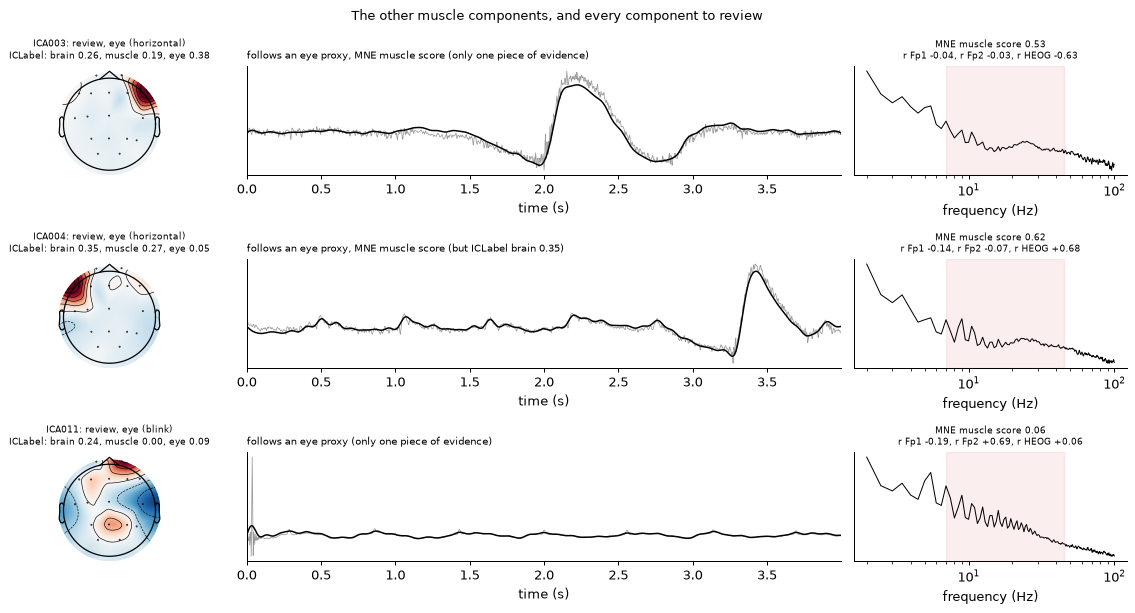

In [38]:
# ---- 6.8 (continued) The other muscle candidates, and the components to review ------------------------------------------------------
others = [k for k in range(ica.n_components_) if k not in examples
          and (evidence['decision'].iloc[k] == 'review' or evidence['proposed_class'].iloc[k] == 'muscle')]
if others:
    show_components(others, 'The other muscle components, and every component to review')
else:
    print('No other muscle component, and nothing to review.')

**Look.** Each row is one component: its map and ICLabel, 4 s of its time course (grey: all of it; black: its 1–10 Hz part, where the
eyes are) and its spectrum. **Blink** (ICA005): a frontal map, Fp1 and Fp2, with the opposite sign at the back, a large slow wave at the
blink, most of its power at low frequencies. No eye movement and no muscle component was removed, so the first figure has one row.

The second figure shows the three components to review. ICA003 (F8) and ICA004 (F7): one spot at the edge of the cap, a slow wave of their
own, and a bump between 20 and 40 Hz in the spectrum, which is why MNE's muscle score votes for them. ICA011 (Fp2): a spectrum with a comb
of regular peaks, the harmonics of the steps (cell 7.4).

After / before (% of the amplitude, median over the windows), and the correlation before-after in the middle and at the back:
               windows  front  middle and back  temples 30-100 Hz  middle and back, r
blinks           263.0   93.0             99.0               99.0               0.992
muscle bursts     24.0   98.0            100.0               99.0               0.980
clean             80.0   90.0             99.0               99.0               0.990
✗ ocular transients strongly reduced at the front (below 50 % of their amplitude)
✓ muscle bursts reduced at the temples (30-100 Hz below 100 %)
✓ clean moments unchanged in the middle and at the back (90-110 %, r at least 0.9): the brain signal is not flattened


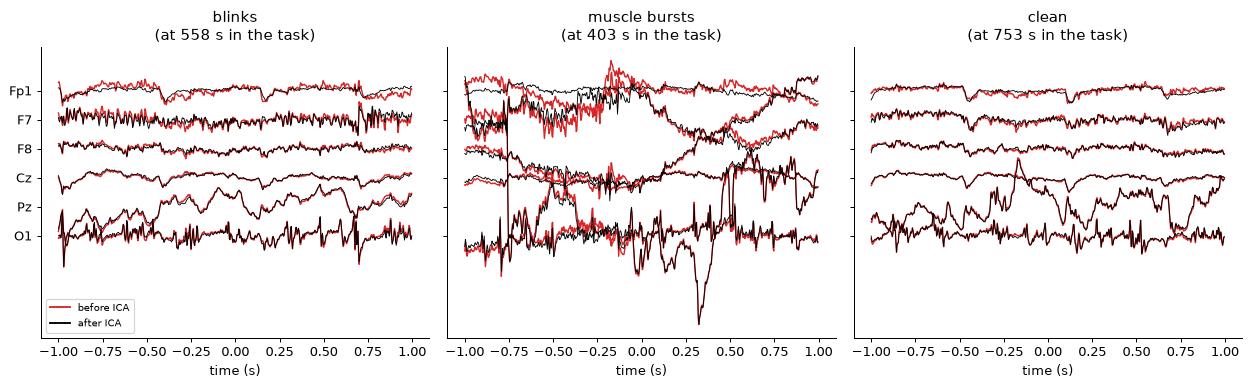

Validated eye components       ['ICA005']
Validated muscle components    []
To review (kept for now)       ['ICA003', 'ICA004', 'ICA011']
Final exclusion list           ['ICA005']


In [39]:
# ---- 6.9 Before accepting the decision: apply it to a copy, and compare four kinds of moments ---------------------------------------
from scipy.signal import find_peaks                          # the fastest changes of the eye movement component
test_copy = ica.apply(analysis['task'].copy())               # a copy: the analysis data are not changed (step 7 applies ICA to them)
before_ep = mne.make_fixed_length_epochs(analysis['task'], duration=2, preload=True)   # 2-s windows, junctions and gaps left out
after_ep = mne.make_fixed_length_epochs(test_copy, duration=2, preload=True)           # the same windows, after ICA
groups = {'front': [ch for ch in ['Fp1', 'Fp2', 'F7', 'F8'] if ch not in BAD_CHANNELS],
          'middle and back': [ch for ch in ['Cz', 'Pz', 'P3', 'P4', 'O1', 'O2'] if ch not in BAD_CHANNELS],
          'temples': edge}                                   # (F7, F8, T7, T8: cell 3.8)
x_before = {group: before_ep.get_data(picks=chs) * 1e6 for group, chs in groups.items()}   # windows x channels x samples (µV)
x_after = {group: after_ep.get_data(picks=chs) * 1e6 for group, chs in groups.items()}
starts = before_ep.events[:, 0] - analysis['task'].first_samp


def contains(samples):
    """True for each window that contains at least one of these samples."""
    return np.array([np.any((samples >= s) & (samples < s + len(before_ep.times))) for s in starts])


def window_rms(x, fmin=None, fmax=None):
    """Root mean square of each window and channel, from its spectrum: all frequencies but the mean, or only fmin to fmax (Hz)."""
    f = np.fft.rfftfreq(x.shape[-1], 1 / sfreq)
    keep = (f > 0) if fmin is None else (f >= fmin) & (f <= fmax)
    return np.sqrt(2 * (np.abs(np.fft.rfft(x, axis=-1)) ** 2)[..., keep].sum(axis=-1)) / x.shape[-1]


blinks = blink_events[:, 0] - analysis['task'].first_samp   # the blinks of cell 4.2
moves = np.array([], dtype=int)
horizontal = [k for k in ica.exclude if evidence['proposed_class'].iloc[k] == 'eye (horizontal)']
if horizontal:                                               # eye movements: the fastest changes of the horizontal eye component
    slow = mne.filter.filter_data(ica.get_sources(analysis['task']).get_data(picks=horizontal[:1])[0], sfreq, None, 10)
    speed = np.abs(np.gradient(slow))
    moves, _ = find_peaks(speed, height=np.median(speed) + 5 * 1.4826 * np.median(np.abs(speed - np.median(speed))),
                          distance=int(0.5 * sfreq))
    moves = moves[np.min(np.abs(moves[:, None] - blinks[None, :]), axis=1) > 0.5 * sfreq]   # not during a blink
muscle_power = window_rms(x_before['temples'], 30, 100).mean(axis=1)
eye_power = window_rms(x_before['front'], 1, 10).mean(axis=1)
moments = {'blinks': contains(blinks), 'horizontal eye movements': contains(moves) & ~contains(blinks),
           'muscle bursts': muscle_power >= np.quantile(muscle_power, 0.95)}   # the 5 % of windows with the most fast activity
moments['clean'] = (~np.logical_or.reduce(list(moments.values())) & (muscle_power < np.median(muscle_power))
                    & (eye_power < np.median(eye_power)))                     # no event, little fast activity, little eye activity
rows = {}
for moment, chosen in moments.items():
    if chosen.any():
        relative = lambda group, *band: 100 * np.median(window_rms(x_after[group][chosen], *band) / window_rms(x_before[group][chosen], *band))
        rows[moment] = {'windows': chosen.sum(), 'front': relative('front'), 'middle and back': relative('middle and back'),
                        'temples 30-100 Hz': relative('temples', 30, 100),
                        'middle and back, r': np.corrcoef(x_before['middle and back'][chosen].ravel(),
                                                          x_after['middle and back'][chosen].ravel())[0, 1]}
comparison = pd.DataFrame(rows).T
eye_rows = [m for m in ['blinks', 'horizontal eye movements'] if m in comparison.index]
checks = {'ocular transients strongly reduced at the front (below 50 % of their amplitude)': (comparison.loc[eye_rows, 'front'] < 50).all(),
          'muscle bursts reduced at the temples (30-100 Hz below 100 %)': comparison.loc['muscle bursts', 'temples 30-100 Hz'] < 100,
          'clean moments unchanged in the middle and at the back (90-110 %, r at least 0.9): the brain signal is not flattened':
              90 <= comparison.loc['clean', 'middle and back'] <= 110 and comparison.loc['clean', 'middle and back, r'] >= 0.9}
print('After / before (% of the amplitude, median over the windows), and the correlation before-after in the middle and at the back:')
print(comparison.round({'windows': 0, 'front': 0, 'middle and back': 0, 'temples 30-100 Hz': 0, 'middle and back, r': 3}).to_string())
for text, ok in checks.items():
    print(('✓ ' if ok else '✗ ') + text)

centres = {'blinks': blink * sfreq}                          # one example of each: the blink of cell 4.2,
if len(moves):
    centres['horizontal eye movements'] = moves[np.argmax(speed[moves])]   # the fastest eye movement,
for moment in ['muscle bursts', 'clean']:                    # the middle of a typical window
    windows_in = np.flatnonzero(moments[moment])
    size = muscle_power if moment == 'muscle bursts' else window_rms(x_before['middle and back']).mean(axis=1)
    centres[moment] = starts[windows_in[np.argsort(size[windows_in])[len(windows_in) // 2]]] + sfreq
shown = [ch for ch in ['Fp1', 'F7', 'F8', 'Cz', 'Pz', 'O1'] if ch not in BAD_CHANNELS]
fig, axes = plt.subplots(1, len(centres), figsize=(14, 4.4), sharey=True)
for ax, (moment, centre) in zip(axes, centres.items()):
    start = int(centre - sfreq)
    for data, color, lw in [(analysis['task'], 'tab:red', 1.1), (test_copy, 'k', 0.7)]:
        y = data.get_data(picks=shown, start=start, stop=start + 2 * int(sfreq)) * 1e6
        for k, trace in enumerate(y):
            ax.plot(np.arange(len(trace)) / sfreq - 1, trace - trace.mean() - 100 * k, color=color, lw=lw)
    ax.set(title=f'{moment}\n(at {centre / sfreq:.0f} s in the task)', xlabel='time (s)', yticks=-100 * np.arange(len(shown)),
           yticklabels=shown)
axes[0].plot([], [], color='tab:red', label='before ICA')
axes[0].plot([], [], color='k', label='after ICA')
axes[0].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

for title, chosen in [('Validated eye components', evidence['proposed_class'].str.startswith('eye')),
                      ('Validated muscle components', evidence['proposed_class'] == 'muscle')]:
    print(f'{title:30s}', list(evidence.index[chosen & (evidence['decision'] == 'remove')]))
print(f'{"To review (kept for now)":30s}', list(evidence.index[evidence['decision'] == 'review']))
print(f'{"Final exclusion list":30s}', [evidence.index[k] for k in ica.exclude])

**Look.** The table compares the same 2-s windows of the task before and after removing ICA005, on a copy. The first check fails (✗): the
windows called **blinks** keep 93 % of their amplitude at the front. They are the 263 windows with an event of `find_eog_events`, which
fires at the steps while walking (cell 4.2): most of them hold no blink, and the steps are not in ICA005. No horizontal eye movement
component was removed, so the table has no row for eye movements. The **muscle bursts** keep 98 to 99 % of their amplitude: no muscle
component was removed. The **clean** moments keep 99 % of their amplitude in the middle and at the back (r = 0.99 between before and
after): the brain signal is not flattened. The figure shows one example of each kind, and the four lines at the end are the decision that
step 7 applies: one component, ICA005.

**The cleaning strategy.** ICA is the main cleaner. Once the components are validated, `ica.exclude` holds them, and step 7 applies the ICA
solution to every sample of the 0.1–100 Hz analysis data: the same data, cleaned by Auto-CCA, that the ICA copy came from. Auto-CCA (3.8)
is meant for the muscle activity spread over the scalp (in this walking task it removed nothing); it is not used for the blinks or the eye
movements, which it leaves to ICA.

## 7. Remove the eye and muscle components

**What.** Remove the components validated in step 6 (`ica.exclude`) from the **analysis data** (0.1–100 Hz, cleaned by Auto-CCA). At each moment, `ica.apply(raw)` computes the components
with the unmixing matrix (components = `W` × channels), sets the excluded components to zero, and rebuilds the channels with the mixing matrix
(channels = `A` × components).

**Why it works on the analysis data.** `W` and `A` are **spatial**: they only say how to combine the electrodes at one moment, whatever the
frequencies of the signal (step 6). A filter works over time, on each electrode separately. The two operations do not interfere (both are
linear), so the weights learned on the 1–100 Hz copy are valid for the 0.1–100 Hz analysis data (Winkler et al., 2015). We get the best of both: a good
decomposition, and slow ERPs that are not distorted.

**All the data.** ICA is applied to every sample of the analysis data, the periods left out of ICA training (step 5) included. Nothing is
cropped, and the QC annotations stay on the data (cell 7.1 checks both).

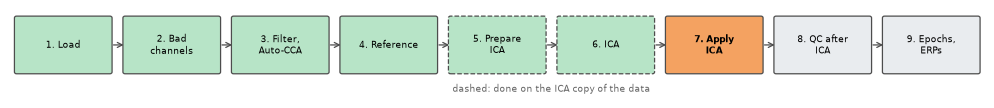

In [48]:
pipeline_map(7)

In [40]:
# ---- 7.1 Apply ICA to the two analysis recordings: every sample, and the QC annotations kept ----------------------------------------
cleaned = {name: ica.apply(raw.copy()) for name, raw in analysis.items()}
print(f'Removed components {ica.exclude} from:', ', '.join(cleaned))
for name in cleaned:
    qc_before = [d for d in analysis[name].annotations.description if d.startswith('QC_')]
    qc_after = [d for d in cleaned[name].annotations.description if d.startswith('QC_')]
    print(f'{name:10s} every sample kept: {cleaned[name].n_times == analysis[name].n_times}; '
          f'QC annotations kept: {qc_after == qc_before} ({len(qc_after)})')

Removed components [5] from: walk_only, task
walk_only  every sample kept: True; QC annotations kept: True (0)
task       every sample kept: True; QC annotations kept: True (24)


441 blinks found in the task (28 per minute)


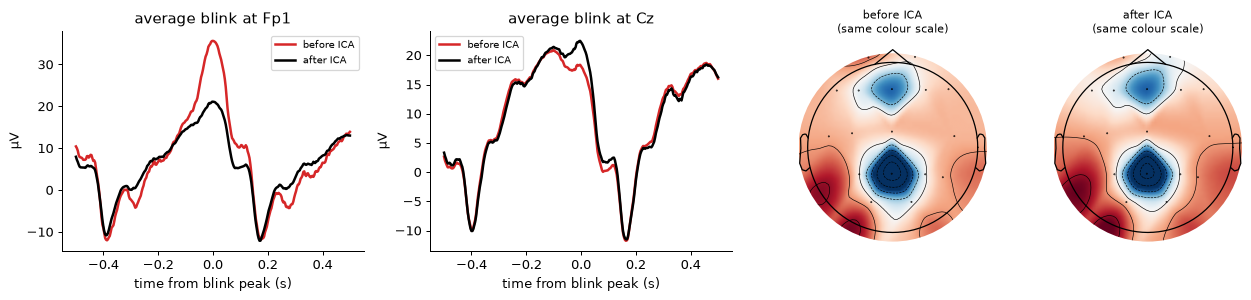

In [41]:
# ---- 7.2 The average blink, before and after ICA -----------------------------------------------------------------------------------
print(f'{len(blink_events)} blinks found in the task ({len(blink_events) / (analysis["task"].times[-1] / 60):.0f} per minute)')
blink_average = {label: mne.Epochs(data['task'], blink_events, tmin=-0.5, tmax=0.5, baseline=(-0.5, -0.3), preload=True).average()
                 for label, data in [('before ICA', analysis), ('after ICA', cleaned)]}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), width_ratios=[1.6, 1.6, 1, 1])
for ax, ch in zip(axes[:2], [frontal, 'Cz']):
    for (label, evoked), color in zip(blink_average.items(), ['tab:red', 'k']):
        ax.plot(evoked.times, evoked.get_data(picks=ch)[0] * 1e6, color=color, lw=2, label=label)
    ax.set(title=f'average blink at {ch}', xlabel='time from blink peak (s)', ylabel='µV')
    ax.legend(fontsize=8)
peak = blink_average['before ICA'].get_data(picks=good_all).max() * 1e6
for ax, (label, evoked) in zip(axes[2:], blink_average.items()):
    data = evoked.copy().pick(good_all).crop(0, 0)
    mne.viz.plot_topomap(data.get_data()[:, 0] * 1e6, data.info, axes=ax, show=False, vlim=(-peak, peak), cmap='RdBu_r')
    ax.set_title(f'{label}\n(same colour scale)', fontsize=9)
plt.tight_layout()
plt.show()

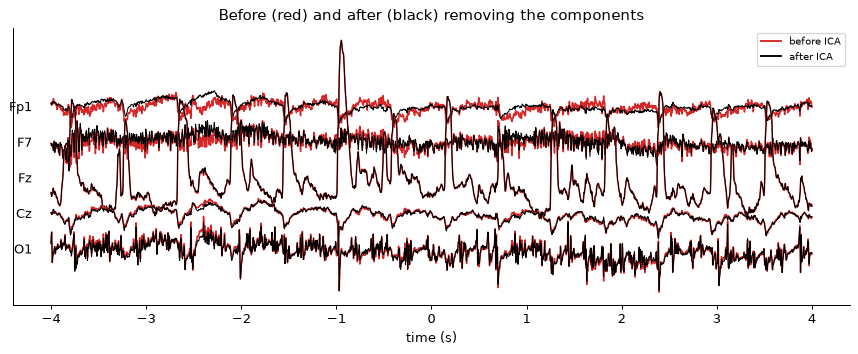

In [42]:
# ---- 7.3 Eight seconds of the task, before and after ICA ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
for k, ch in enumerate(['Fp1', 'F7', 'Fz', 'Cz', 'O1']):
    for data, color, lw in [(analysis, 'tab:red', 1.2), (cleaned, 'k', 0.8)]:
        piece = data['task'].copy().crop(blink - 4, blink + 4)
        ax.plot(piece.times - 4, piece.get_data(picks=ch)[0] * 1e6 - 100 * k, color=color, lw=lw)
    ax.text(-4.2, -100 * k, ch, ha='right', va='center')
ax.plot([], [], color='tab:red', label='before ICA')
ax.plot([], [], color='k', label='after ICA')
ax.set(yticks=[], xlabel='time (s)', title='Before (red) and after (black) removing the components')
ax.legend(loc='upper right', fontsize=8)
plt.show()

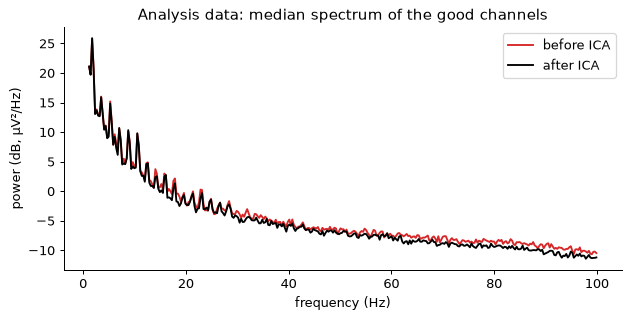

In [52]:
# ---- 7.4 The muscle components: the spectrum of the analysis data before and after --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, data, color in [('before ICA', analysis['task'], 'tab:red'), ('after ICA', cleaned['task'], 'k')]:
    psd = data.compute_psd(method='welch', picks=good_all, fmin=1, fmax=100, n_fft=1024, tmax=300)
    ax.plot(psd.freqs, 10 * np.log10(np.median(psd.get_data(), axis=0) * 1e12), color=color, label=label)
ax.set(xlabel='frequency (Hz)', ylabel='power (dB, µV²/Hz)', title='Analysis data: median spectrum of the good channels')
ax.legend()
plt.show()

**Look.** The "average blink" of 7.2 averages the 441 events of `find_eog_events`, most of them steps (cell 4.2): at Cz it is a wave of
about 20 µV that is the same before and after ICA, and its map is not the map of a blink. At Fp1, removing the blink component lowers it
by about 40 %. In the traces (7.3), the sharp waves of Fz at every step are unchanged: no component was removed for them. The spectrum
(7.4) has a comb of peaks every 1.8 Hz up to about 30 Hz, the harmonics of the steps, and it is almost the same before and after ICA.

#### Check your understanding

- **After ICA the blink is gone at Fp1. Is the brain signal at Fp1 gone too?**
  <details><summary>Answer</summary>

  No: only the removed components are subtracted, and the brain components still contribute to Fp1. But any brain activity mixed into a removed component is lost: this is why we remove as few components as possible.

  </details>
- **Why was it important to find the bad channels before ICA?**
  <details><summary>Answer</summary>

  A noisy channel would have taken one or more components for itself, and after the average reference its noise would have been in every channel, mixed with the other sources.

  </details>

## 8. Check the data after ICA, and mark what stays unusable

**What.** Measure the same 5-s windows again after ICA, and compare them with step 2. Then decide which QC periods are still unusable for
the analysis of events, and give them a second annotation, `BAD_final_...`.

**Why.** Auto-CCA and ICA removed muscle and eye activity, so some QC periods may now look normal, and others not. The comparison shows, for each
QC period, whether the problem disappeared, became smaller, or stayed. A smaller amplitude does not make a period good: it was abnormal for
a reason (a loose electrode, a movement), so its `QC_` annotation stays on the data in every case, as a record of what happened. Only the
periods that are still clearly unusable get `BAD_final_`, and `mne.Epochs` (step 9) drops the trials that overlap them.

**The rule** (cell 8.2). A whole-scalp QC period still above `QC_RATIO` after ICA gets `BAD_final_`. A QC period on one channel stays `QC_`
whatever happens: one electrode does not make a moment unusable for every analysis, and a `BAD` annotation with `ch_names` would make MNE
drop whole epochs anyway (step 2).

**The bad channels are not rebuilt.** Many pipelines rebuild the bad channels at this point from their neighbours (spherical spline
interpolation). With 19 dry electrodes, the neighbours of a bad electrode are few and far away, and a rebuilt channel would only be a
smoothed copy of them presented as a measurement. So the bad channels stay in `raw.info['bads']` until the end: MNE leaves them out, and the
ERPs use only the electrodes that were recorded (step 9). This is a deliberate choice for this low-density headset.

**How.** The function of cell 2.4 on the cleaned data: the same windows, channels, measure and colour scale.

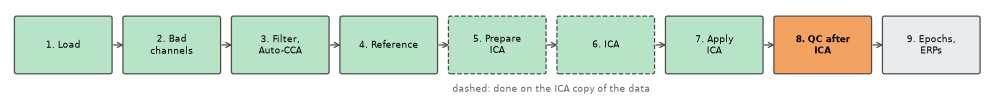

In [53]:
pipeline_map(8)

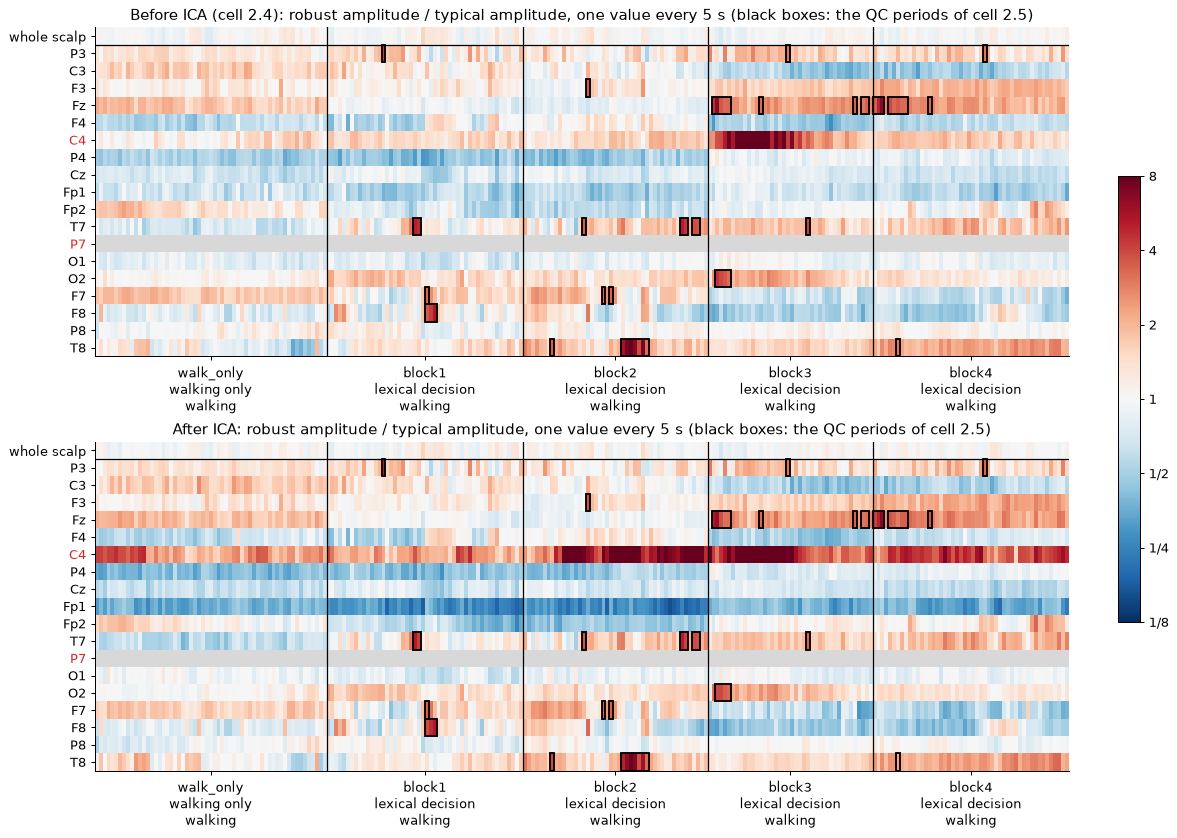

In [54]:
# ---- 8.1 The same 5-s windows, before and after ICA ---------------------------------------------------------------------------------
from matplotlib.patches import Rectangle                     # the boxes around the QC periods
quality_after, _ = window_quality(cleaned)                   # the same windows, channels and measure as cell 2.4


def mark_qc(ax):
    """Draws a box around each QC period of cell 2.5 on a heatmap of plot_quality: on its channel, or on the row 'whole scalp'."""
    rows = ['whole scalp'] + list(ratio.index)
    for p in qc_table.itertuples():
        inside = np.flatnonzero((windows['recording'] == p.recording) & (windows['start'] >= p.onset - 1e-6)
                                & (windows['start'] < p.onset + p.duration - 1e-6))
        row = 0 if p.channels == 'all' else rows.index(p.channels)
        ax.add_patch(Rectangle((inside[0] - 0.5, row - 0.5), len(inside), 1, fill=False, ec='k', lw=1.5))


fig, axes = plt.subplots(2, 1, figsize=(13, 9.2), layout='constrained')
for ax, (label, table) in zip(axes, [('Before ICA (cell 2.4)', quality), ('After ICA', quality_after)]):
    image = plot_quality(table, ax, f'{label}: robust amplitude / typical amplitude, one value every {QC_WINDOW_S:g} s (black boxes: '
                                    f'the QC periods of cell 2.5)')
    mark_qc(ax)
cbar = fig.colorbar(image, ax=axes, ticks=[-3, -2, -1, 0, 1, 2, 3], shrink=0.6)
cbar.ax.set_yticklabels(['1/8', '1/4', '1/2', '1', '2', '4', '8'])
plt.show()

In [55]:
# ---- 8.2 The decision: BAD_final_ for what stays unusable, and the data of steps 9 and 10 -------------------------------------------
def after_ica(p):
    """The value of a QC period after ICA, as `ratio` in cell 2.5: the largest of its windows, or the smallest for a lost contact."""
    inside = ((windows['recording'] == p.recording) & (windows['start'] >= p.onset - 1e-6)
              & (windows['start'] < p.onset + p.duration - 1e-6)).to_numpy()
    values = quality_after.loc['whole scalp' if p.channels == 'all' else p.channels, inside]
    return values.min() if p.description == 'QC_contact' else values.max()


qc_table['ratio after ICA'] = [after_ica(p) for p in qc_table.itertuples()]
still = np.where(qc_table['description'] == 'QC_contact', qc_table['ratio after ICA'] < FLAT_RATIO, qc_table['ratio after ICA'] > QC_RATIO)
qc_table['after ICA'] = np.where(still, 'still beyond the threshold', 'within the threshold, still suspicious')
final_bad = still & (qc_table['channels'] == 'all').to_numpy()   # the whole scalp, still unusable
qc_table['final'] = np.where(final_bad, 'BAD_final', 'QC only')
final = {name: raw.copy() for name, raw in cleaned.items()}  # the data of steps 9 and 10: the QC annotations stay
for p in qc_table[final_bad].itertuples():
    raw = final[p.recording]
    raw.annotations.append(onset=raw.first_time + p.onset, duration=p.duration,
                           description='BAD_final_' + p.description.removeprefix('QC_'))
print(f'{final_bad.sum()} of {len(qc_table)} QC periods become BAD_final_. Bad channels {final["task"].info["bads"]}: still marked, '
      f'not rebuilt.')
qc_table.round(2)

0 of 24 QC periods become BAD_final_. Bad channels ['C4', 'P7']: still marked, not rebuilt.


,recording,part,onset,duration,description,channels,ratio,held out from ICA,ratio after ICA,after ICA,final
0,task,block2,331.93,5.0,QC_large_amplitude,F3,3.60,False,3.76,still beyond the threshold,QC only
1,task,block1,125.00,5.0,QC_large_amplitude,F7,3.27,False,3.46,still beyond the threshold,QC only
2,task,block2,351.93,5.0,QC_large_amplitude,F7,3.23,False,3.49,still beyond the threshold,QC only
3,task,block2,361.93,5.0,QC_large_amplitude,F7,3.37,False,3.47,still beyond the threshold,QC only
4,task,block1,125.00,15.0,QC_large_amplitude,F8,5.42,True,5.32,still beyond the threshold,QC only
5,task,block3,492.55,25.0,QC_large_amplitude,Fz,6.58,True,6.11,still beyond the threshold,QC only
6,task,block3,552.55,5.0,QC_large_amplitude,Fz,3.19,False,3.30,still beyond the threshold,QC only
7,task,block3,672.55,5.0,QC_large_amplitude,Fz,3.47,False,3.39,still beyond the threshold,QC only
8,task,block3,682.55,10.0,QC_large_amplitude,Fz,3.40,False,3.20,still beyond the threshold,QC only
9,task,block4,701.79,15.0,QC_large_amplitude,Fz,6.65,True,6.72,still beyond the threshold,QC only


**Look.** The two heatmaps have the same windows, rows and colours, and the black boxes are the QC periods of step 2. Compare each box before
and after ICA: the table says whether the period is still beyond its threshold. Look also at the channels around the eyes: Fp1 is quieter
everywhere after ICA, because the blink component carried much of its signal. C4 looks much louder after ICA. It is a bad channel, so it
was left out of the average reference (step 4) and keeps the Pz reference, with the walking noise of the Pz sensor that the other channels
no longer carry: its row now compares two references and says nothing new about C4. In P010 no QC period covers the whole scalp, so no
`BAD_final_` annotation is added: the 24 QC annotations stay on the data, and no trial will be dropped because of them.

## 9. Epochs and ERPs, before and after cleaning

**What.** Cut one **epoch** per word, from 0.2 s before to 0.8 s after it, subtract its mean over the 200 ms before the word (the
**baseline**), and average the epochs of each condition into **ERPs**. We do it twice: on the data **before cleaning** (the recording with
only a 0.1–40 Hz band-pass and the average reference) and **after cleaning** (Auto-CCA and ICA, then the same 0.1–40 Hz band). Comparing
the two shows what the preprocessing did to the ERPs.

**Which epochs.** No new rejection: steps 2 to 8 already marked what is unusable. `mne.Epochs` drops every epoch that touches a `BAD`
annotation (the junctions of the blocks, the data gaps, and the `BAD_final_` periods, none in P010); the `QC_` annotations drop nothing,
and the bad channels stay out (`raw.info['bads']`). Of the epochs left, we keep the correct answers whose onset is confirmed by the tone of
the word (`KEEP_CORRECT_ONLY` and `MAX_TONE_MS` in cell 0.3).

**Where and when.** Each component is the mean over a group of electrodes and a time window (`COMPONENTS` in cell 0.3). They come from
the Brain Walk group analyses, not from this participant:

| Component | Electrodes | Window | Source |
|---|---|---|---|
| P2 | F3, Fz, F4, C3, Cz, C4 | 140–220 ms | where the P2 of the group is clearest (cluster analysis) |
| N400 | C3, Cz, C4, P3, Pz, P4 | 300–500 ms | the region of the COSYNE abstract, and the usual N400 window (Kutas & Federmeier, 2011) |
| LPC (late positivity) | C3, Cz, C4, P3, Pz, P4 | 450–800 ms | the same region, and the late window of the COSYNE abstract |

The N400 and LPC region is symmetric on purpose: each condition is answered with its own hand, and averaging C3 with C4 and P3 with P4
cancels the motor potential of that hand before the tap.

**How.** `mne.events_from_annotations` gives one event per word; `mne.Epochs(raw, events, event_id, tmin, tmax, baseline, metadata)` cuts
the epochs (`reject_by_annotation=True` by default); `epochs[condition].average()` makes each ERP; `mne.viz.plot_compare_evokeds(evokeds,
picks=region, combine='mean')` draws them.

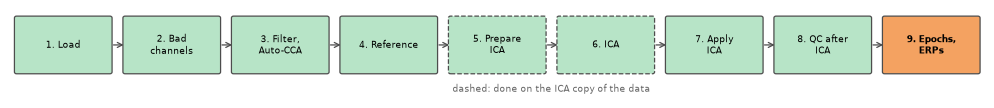

In [56]:
pipeline_map(9)

In [57]:
# ---- 9.1 One epoch per word, before and after cleaning ------------------------------------------------------------------------------
EVENT_ID = {'word/HF': 1, 'word/LF': 2, 'pseudoword': 3}     # the code of each condition in the events array
before = recordings['task'].copy().filter(*ERP_BAND, picks='eeg').set_eeg_reference('average')   # not cleaned: filter and reference only
after = final['task'].copy().filter(None, ERP_BAND[1], picks='eeg')   # cleaned; its 0.1 Hz high-pass dates from step 3, the 40 Hz is new
word_events, _ = mne.events_from_annotations(after, event_id=EVENT_ID)
assert (word_events[:, 2] == trials['condition'].map(EVENT_ID).to_numpy()).all()   # same words, same order as the trials table
metadata = trials[['block', 'trial_in_block', 'stimulus', 'condition', 'accuracy', 'response_time', 'marker_residual_ms']].reset_index(drop=True)
epochs = {label: mne.Epochs(data, word_events, EVENT_ID, tmin=TMIN, tmax=TMAX, baseline=BASELINE, metadata=metadata, preload=True)
          for label, data in [('before cleaning', before), ('after cleaning', after)]}   # the epochs touching a BAD annotation are dropped
outside_bad = epochs['after cleaning'].metadata['condition'].value_counts()
dropped = pd.Series([reason for log in epochs['after cleaning'].drop_log for reason in log]).value_counts().to_dict()
both = np.intersect1d(epochs['before cleaning'].selection, epochs['after cleaning'].selection)   # (BAD_final_ is only on the cleaned data)
epochs = {label: ep[np.isin(ep.selection, both)] for label, ep in epochs.items()}   # the same epochs in both
confirmed = (epochs['after cleaning'].metadata['marker_residual_ms'].abs() <= MAX_TONE_MS).to_numpy()   # its own tone, close to the onset
correct = (epochs['after cleaning'].metadata['accuracy'] == 1).to_numpy() if KEEP_CORRECT_ONLY else np.ones(len(confirmed), bool)
epochs = {label: ep[confirmed & correct] for label, ep in epochs.items()}
print(f'Dropped because they touch a BAD annotation: {dropped}')
counts = pd.DataFrame({'words': trials['condition'].value_counts(), 'not in a BAD annotation': outside_bad,
                       'kept (correct, onset confirmed)': epochs['after cleaning'].metadata['condition'].value_counts()}).loc[list(CONDITIONS)]
counts.loc['total'] = counts.sum()
counts

Dropped because they touch a BAD annotation: {'BAD_gap': 8}


,words,not in a BAD annotation,"kept (correct, onset confirmed)"
condition,,,
word/HF,93,90,85
word/LF,99,98,71
pseudoword,189,185,151
total,381,373,307


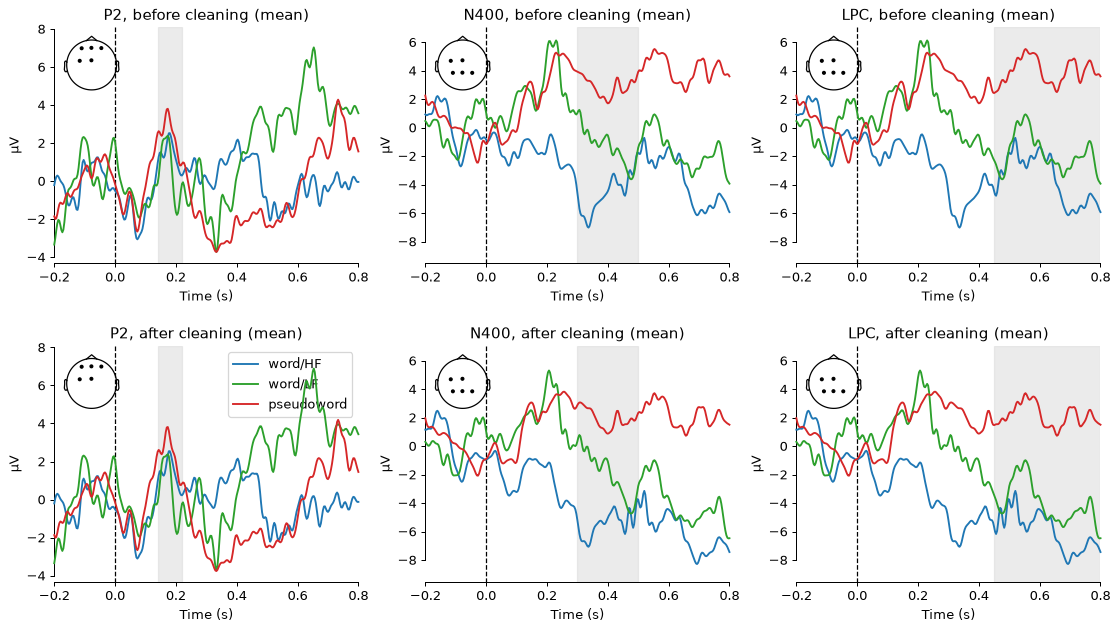

P2                           N400                 \
           before cleaning after cleaning before cleaning after cleaning   
word/HF               1.40           1.40           -4.62          -5.46   
word/LF               0.55           0.54           -1.36          -1.98   
pseudoword            2.41           2.40            2.88           1.93   

                       LPC                 
           before cleaning after cleaning  
word/HF              -3.64          -5.96  
word/LF              -1.83          -4.01  
pseudoword            3.96           2.15

In [58]:
# ---- 9.2 The P2, the N400 and the LPC, before and after cleaning --------------------------------------------------------------------
erps = {label: {name: ep[name].average() for name in CONDITIONS} for label, ep in epochs.items()}
fig, axes = plt.subplots(2, len(COMPONENTS), figsize=(15, 8))
amplitude = {}
for col, (component, c) in enumerate(COMPONENTS.items()):
    region = [ch for ch in c['region'] if ch not in BAD_CHANNELS]   # the electrodes that were recorded
    waves = [ev.copy().pick(region).data.mean(axis=0) * 1e6 for row in erps.values() for ev in row.values()]
    ylim = (1.15 * min(w.min() for w in waves), 1.15 * max(w.max() for w in waves))   # the same scale before and after
    for row, (label, evokeds) in enumerate(erps.items()):
        mne.viz.plot_compare_evokeds(evokeds, picks=region, combine='mean', colors=CONDITIONS, axes=axes[row, col], ylim=dict(eeg=ylim),
                                     title=f'{component}, {label}', legend='upper right' if (row, col) == (1, 0) else False,
                                     show_sensors='upper left', show=False)
        axes[row, col].axvspan(*c['window'], color='0.85', alpha=0.5, zorder=0)   # the window of the component
        amplitude[(component, label)] = {name: ev.copy().pick(region).crop(*c['window']).data.mean() * 1e6 for name, ev in evokeds.items()}
fig.subplots_adjust(hspace=0.35, wspace=0.22)
plt.show()
amplitude = pd.DataFrame(amplitude)                          # mean amplitude in each window (µV): conditions x (component, data)
amplitude.round(2)

**Look.** 8 epochs touch a data gap and are dropped; 307 correct answers with a confirmed onset remain (85 HF words, 71 LF words, 151
pseudowords), the same epochs before and after cleaning. C4 is a bad channel, so the regions use their other electrodes (black dots): the
N400 and LPC region loses its symmetry (C3 without C4), and the motor potential of the hand that answers is no longer cancelled. **P2**:
a peak of about +2.5 to +4 µV near 170 ms in the three conditions, before and after cleaning. **N400** and **LPC**: the conditions
separate from about 200 ms and stay apart until 800 ms, the pseudowords positive and the words negative: in the N400 window, −5.5 µV for
the HF words and +1.9 µV for the pseudowords after cleaning (seated, the three conditions were within 0.6 µV of each other). A difference
this large and this early is unlikely to be an N400 effect. This pipeline leaves a lot in walking data: the steps, in every trial (cell
7.3); the noise of the Pz sensor, which is in both regions (Pz varies with an SD of 174 µV after the average reference, cell 4.1, against
27 µV seated); and the hand. Cleaning, here the removal of ICA005, changes the ERPs little. These ERPs are not interpretable yet: the
walking-specific steps come next.

## 10. Save the results, and summary

In [59]:
# ---- 10.1 Save the clean data with their QC information, the epochs and a summary ---------------------------------------------------
RESULTS_DIR = DATA_DIR / 'mes_resultats'                     # "my results": the folder notebook 01 also writes to
RESULTS_DIR.mkdir(exist_ok=True)
epochs['after cleaning'].save(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking-epo.fif', overwrite=True)   # the cleaned epochs (9.1)
for name, raw in final.items():                              # the continuous data, with raw.info['bads'] and every annotation
    raw.save(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_{name}_eeg.fif', overwrite=True)
qc_summary = qc_table.assign(participant=SUBJECT, bad_channels=' '.join(BAD_CHANNELS))   # a readable copy; the FIF files are the reference
qc_summary = qc_summary[['participant', 'recording', 'part', 'bad_channels', 'onset', 'duration', 'description', 'channels', 'ratio',
                         'held out from ICA', 'ratio after ICA', 'after ICA', 'final']]
qc_summary.to_csv(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_qc.csv', index=False)
evidence.assign(participant=SUBJECT).to_csv(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_ica_components.csv')   # the evidence of cell 6.7
summary = {
    'participant': SUBJECT,
    'bad channels (in info["bads"], not rebuilt)': BAD_CHANNELS,
    'QC periods / left out of ICA training / BAD_final': f'{len(qc_table)} / {int(qc_table["held out from ICA"].sum())} / '
                                                         f'{int((qc_table["final"] == "BAD_final").sum())}',
    'ICA components': int(ica.n_components_),
    'components removed': [f'ICA{i:03d}' for i in ica.exclude],
    'components to review (kept)': list(evidence.index[evidence['decision'] == 'review']),
    'Auto-CCA: components removed per window (median)': {name: int(table.groupby('window start (s)')['muscle'].sum().median())
                                                         for name, table in cca_tables.items()},
    'epochs kept (HF, LF, pseudoword)': [len(epochs['after cleaning'][name]) for name in CONDITIONS],
    **{f'{component}, mean amplitude after cleaning (µV)': {name: round(float(amplitude.loc[name, (component, 'after cleaning')]), 2)
                                                           for name in CONDITIONS} for component in COMPONENTS},
}
(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved in', RESULTS_DIR)
pd.Series(summary, name=SUBJECT).to_frame()

Saved in tasks\brainwalk\mes_resultats


,P010
participant,P010
"bad channels (in info[""bads""], not rebuilt)","[C4, P7]"
QC periods / left out of ICA training / BAD_final,24 / 6 / 0
ICA components,16
components removed,[ICA005]
components to review (kept),"[ICA003, ICA004, ICA011]"
Auto-CCA: components removed per window (median),"{'walk_only': 1, 'task': 0}"
"epochs kept (HF, LF, pseudoword)","[85, 71, 151]"
"P2, mean amplitude after cleaning (µV)","{'word/HF': 1.4, 'word/LF': 0.54, 'pseudoword'..."
"N400, mean amplitude after cleaning (µV)","{'word/HF': -5.46, 'word/LF': -1.98, 'pseudowo..."


In [60]:
# ---- 10.2 Check the QC information at the end of the preprocessing ------------------------------------------------------------------
def annotation_set(raw, prefix):
    """The annotations of raw whose description starts with prefix: (description, onset in the recording, duration, channels)."""
    return {(a['description'], round(a['onset'] - raw.first_time, 2), round(a['duration'], 2), tuple(a.get('ch_names', ())))
            for a in raw.annotations if a['description'].startswith(prefix)}


reloaded = {name: mne.io.read_raw_fif(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_{name}_eeg.fif') for name in final}
bad_final = [(a['onset'], a['onset'] + a['duration']) for a in final['task'].annotations if a['description'].startswith('BAD_final_')]
epoch_starts = epochs['after cleaning'].events[:, 0] / sfreq + TMIN      # in the time base of the annotations
checks = {
    'the bad channels are still in info["bads"] (data, epochs, saved files)':
        all(r.info['bads'] == BAD_CHANNELS for r in [*final.values(), *reloaded.values(), *epochs.values()]),
    'the QC_ annotations rejected no epoch': not any(reason.startswith('QC_') for ep in epochs.values() for log in ep.drop_log for reason in log),
    'BAD_ICA_ exists only on the ICA copy': (any(annotation_set(r, 'BAD_ICA_') for r in ica_copy.values()) == bool(qc_table['held out from ICA'].any())
                                             and not any(annotation_set(r, 'BAD_ICA_') for r in [*analysis.values(), *cleaned.values(), *final.values()])),
    'ICA learned without the BAD_ICA_ periods': ica.n_samples_ == ica_training.get_data(picks=good_all[0], reject_by_annotation='omit').shape[1],
    'ICA was applied to every sample': all(cleaned[name].n_times == analysis[name].n_times for name in final),
    'the QC_ annotations survived ICA': all(annotation_set(cleaned[name], 'QC_') == annotation_set(analysis[name], 'QC_') for name in final),
    'one QC_ annotation per row of the QC table': sum(len(annotation_set(final[name], 'QC_')) for name in final) == len(qc_table),
    'BAD_final_ only where the table says BAD_final': (sum(len(annotation_set(final[name], 'BAD_final_')) for name in final)
                                                       == (qc_table['final'] == 'BAD_final').sum()),
    'no kept epoch overlaps a BAD_final_ period': not any(start < end and start + TMAX - TMIN > begin
                                                          for start in epoch_starts for begin, end in bad_final),
    'the saved files keep every annotation': all(annotation_set(reloaded[name], '') == annotation_set(final[name], '') for name in final),
    'the ICA evidence table is saved, and its "remove" rows are the removed components':
        (pd.read_csv(RESULTS_DIR / f'sub-{SUBJECT}_teaching_walking_ica_components.csv', index_col='component')['decision'].tolist()
         == evidence['decision'].tolist() and list(np.flatnonzero(evidence['decision'] == 'remove')) == sorted(ica.exclude)),
    'Auto-CCA left the bad channels and Pz unchanged': all(np.array_equal(filtered_pz[name].get_data(picks=BAD_CHANNELS + ['Pz']),
                                                                         analysis_pz[name].get_data(picks=BAD_CHANNELS + ['Pz']))
                                                          for name in final),
}
for check, ok in checks.items():
    print('✓' if ok else '✗', check)

✓ the bad channels are still in info["bads"] (data, epochs, saved files)
✓ the QC_ annotations rejected no epoch
✓ BAD_ICA_ exists only on the ICA copy
✓ ICA learned without the BAD_ICA_ periods
✓ ICA was applied to every sample
✓ the QC_ annotations survived ICA
✓ one QC_ annotation per row of the QC table
✓ BAD_final_ only where the table says BAD_final
✓ no kept epoch overlaps a BAD_final_ period
✓ the saved files keep every annotation
✓ the ICA evidence table is saved, and its "remove" rows are the removed components
✓ Auto-CCA left the bad channels and Pz unchanged


### The pipeline in one table

| Step | What it did here | Main risk if done badly |
|---|---|---|
| 1. Load | 5 recordings cut at their triggers (walking without the task, 4 blocks), the 4 blocks joined | wrong events or wrong channel types |
| 2. Bad channels | P7 (flat on the recorded signal) and C4 (noisy) in `raw.info['bads']` until the end; noisy channels looked for after a temporary virtual median reference (for detection only); suspicious 5-s periods kept as `QC_` annotations | a bad channel spreads to all others at step 4 |
| 3. Filter, Auto-CCA | 0.1–100 Hz band-pass; Auto-CCA removes, in 10-s windows, the CCA components whose spectrum does not fall with frequency (muscle) | a high-pass that is too high distorts slow ERPs; a CCA threshold that also removes brain activity (alpha) |
| 4. Reference | average of the good channels (the bad ones left out, unchanged); Pz gets a signal back | bad channels in the average |
| 5. Prepare ICA | a temporary 1–100 Hz copy; on this copy only, the gross QC periods marked `BAD_ICA_` (never the blinks) | ICA spoilt by rare huge artifacts |
| 6. ICA | fitted on the ICA copy without its `BAD_ICA_` periods, as many components as the rank of the good channels; a component removed only when two pieces of evidence agree (ICLabel, eye proxies, MNE muscle score, topography), the decision checked on a copy | removing brain components |
| 7. Apply ICA | eye and muscle components removed from every sample of the 0.1–100 Hz analysis data; QC annotations kept | |
| 8. QC after ICA | the same 5-s windows after ICA; whole-scalp periods still unusable marked `BAD_final_`; no channel rebuilt | calling a period good because ICA made it smaller |
| 9. Epochs and ERPs | −0.2 to 0.8 s around each word, baseline −0.2 to 0 s; the epochs touching a `BAD` annotation dropped, no other rejection; correct answers with a confirmed onset; P2, N400 and LPC before and after cleaning, both at 0.1–40 Hz | comparing ERPs that were not filtered or referenced the same way |

### What this simple pipeline does not do

Compared with the full Brain Walk pipeline (notebook `01_preprocessing_lexicaldecision.ipynb`), this pipeline does **not** correct the
head movements measured by the accelerometer of the headset, does not use wavelets to correct the eyes, and does not repair channels
locally in each epoch. Walking data need them: each step shakes the electrodes and the cables. This notebook shows what the seated pipeline
leaves in walking data (cells 1.7, 7.3 and 9.2); the walking-specific steps come next.

### Try it yourself

1. In cell 0.3, set `ANALYSIS_BAND = (1.0, 100.0)` and rerun from step 3. What happens to the LPC in cell 9.2? (Compare with animation 3.4.)
2. In cell 6.7, add the line `ica.exclude = []` at the end and rerun steps 7 to 9. How do the blink figures and the ERPs change?
3. Set `BRAIN_CAUTION = 0.2`. Which components are now only reviewed, and does the ERP change?
4. Set `KEEP_CORRECT_ONLY = False`. How many trials do you gain, and does the N400 change?
5. Compare with the seated notebook (`00_preprocessing_teaching_seated.ipynb`), same participant. Which steps change the most?
6. Set `CCA_SLOPE = -0.48`, the threshold of Janani et al. (2018), and rerun from cell 3.8. What happens to the grey spectrum of cell
   3.8 (continued), and to the ICA components of step 6?

### References

- Ablin, P., Cardoso, J.-F., & Gramfort, A. (2018). Faster independent component analysis by preconditioning with Hessian approximations.
  *IEEE Transactions on Signal Processing, 66*(15), 4040–4049.
- Alday, P. M. (2019). How much baseline correction do we need in ERP research? Extended GLM model can replace baseline correction while
  lifting its limits. *Psychophysiology, 56*(12), e13451.
- Bigdely-Shamlo, N., Mullen, T., Kothe, C., Su, K.-M., & Robbins, K. A. (2015). The PREP pipeline: standardized preprocessing for large-scale EEG
  analysis. *Frontiers in Neuroinformatics, 9*, 16.
- De Clercq, W., Vergult, A., Vanrumste, B., Van Paesschen, W., & Van Huffel, S. (2006). Canonical correlation analysis applied to remove
  muscle artifacts from the electroencephalogram. *IEEE Transactions on Biomedical Engineering, 53*(12), 2583–2587.
- Dharmaprani, D., Nguyen, H. K., Lewis, T. W., DeLosAngeles, D., Willoughby, J. O., & Pope, K. J. (2016). A comparison of independent
  component analysis algorithms and measures to discriminate between EEG and artifact components. *38th Annual International Conference
  of the IEEE EMBS*, 825–828.
- di Fronso, S., Fiedler, P., Tamburro, G., Haueisen, J., Bertollo, M., & Comani, S. (2019). Dry EEG in sports sciences: A fast and reliable tool
  to assess individual alpha peak frequency changes induced by physical effort. *Frontiers in Neuroscience, 13*, 982.
- Downey, R. J., & Ferris, D. P. (2023). iCanClean removes motion, muscle, eye, and line-noise artifacts from phantom EEG. *Sensors,
  23*(19), 8214.
- Fiedler, P., Fonseca, C., Supriyanto, E., Zanow, F., & Haueisen, J. (2022). A high-density 256-channel cap for dry electroencephalography. *Human
  Brain Mapping, 43*(4), 1295–1308.
- Fló, A., Gennari, G., Benjamin, L., & Dehaene-Lambertz, G. (2022). Automated pipeline for infants continuous EEG (APICE): A flexible pipeline for
  developmental cognitive studies. *Developmental Cognitive Neuroscience, 54*, 101077.
- Gonsisko, C. B., Ferris, D. P., & Downey, R. J. (2023). iCanClean improves independent component analysis of mobile brain imaging with EEG.
  *Sensors, 23*(2), 928.
- Gramfort, A., et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience, 7*, 267.
- Heijs, J. J. A., Havelaar, R. J., Fiedler, P., van Wezel, R. J. A., & Heida, T. (2021). Validation of soft multipin dry EEG electrodes. *Sensors,
  21*(20), 6827.
- Hyvärinen, A., & Oja, E. (2000). Independent component analysis: algorithms and applications. *Neural Networks, 13*(4–5), 411–430.
- Janani, A. S., et al. (2018). Improved artefact removal from EEG using Canonical Correlation Analysis and spectral slope. *Journal of
  Neuroscience Methods, 298*, 1–15.
- Jas, M., Engemann, D. A., Bekhti, Y., Raimondo, F., & Gramfort, A. (2017). Autoreject: Automated artifact rejection for MEG and EEG data.
  *NeuroImage, 159*, 417–429.
- Kam, J. W. Y., Griffin, S., Shen, A., Patel, S., Hinrichs, H., Heinze, H.-J., Deouell, L. Y., & Knight, R. T. (2019). Systematic comparison between a
  wireless EEG system with dry electrodes and a wired EEG system with wet electrodes. *NeuroImage, 184*, 119–129.
- Keren, A. S., Yuval-Greenberg, S., & Deouell, L. Y. (2010). Saccadic spike potentials in gamma-band EEG: Characterization, detection
  and suppression. *NeuroImage, 49*(3), 2248–2263.
- Kim, H., Luo, J., Chu, S., Cannard, C., Hoffmann, S., & Miyakoshi, M. (2023). ICA's bug: How ghost ICs emerge from effective rank deficiency caused
  by EEG electrode interpolation and incorrect re-referencing. *Frontiers in Signal Processing, 3*, 1064138.
- Kline, J. E., Huang, H. J., Snyder, K. L., & Ferris, D. P. (2015). Isolating gait-related movement artifacts in electroencephalography during human
  walking. *Journal of Neural Engineering, 12*(4), 046022.
- Klug, M., & Gramann, K. (2021). Identifying key factors for improving ICA-based decomposition of EEG data in mobile and stationary
  experiments. *European Journal of Neuroscience, 54*(12), 8406–8420.
- Klug, M., Jeung, S., Wunderlich, A., Gehrke, L., Protzak, J., Djebbara, Z., Argubi-Wollesen, A., Wollesen, B., & Gramann, K. (2022). The BeMoBIL
  pipeline for automated analyses of multimodal mobile brain and body imaging data. *bioRxiv*. https://doi.org/10.1101/2022.09.29.510051
- Kumaravel, V. P., Buiatti, M., Parise, E., & Farella, E. (2022a). Adaptable and robust EEG bad channel detection using local outlier factor (LOF).
  *Sensors, 22*(19), 7314.
- Kumaravel, V. P., Farella, E., Parise, E., & Buiatti, M. (2022b). NEAR: An artifact removal pipeline for human newborn EEG data. *Developmental
  Cognitive Neuroscience, 54*, 101068.
- Kutas, M., & Federmeier, K. D. (2011). Thirty years and counting: finding meaning in the N400 component of the event-related brain
  potential (ERP). *Annual Review of Psychology, 62*, 621–647.
- Leys, C., Ley, C., Klein, O., Bernard, P., & Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute
  deviation around the median. *Journal of Experimental Social Psychology, 49*(4), 764–766.
- Li, A., Feitelberg, J., Saini, A. P., Höchenberger, R., & Scheltienne, M. (2022). MNE-ICALabel: Automatically annotating ICA components
  with ICLabel in Python. *Journal of Open Source Software, 7*(76), 4484.
- Luck, S. J. (2014). *An introduction to the event-related potential technique* (2nd ed.). MIT Press.
- Makeig, S., Bell, A. J., Jung, T.-P., & Sejnowski, T. J. (1996). Independent component analysis of electroencephalographic data.
  *Advances in Neural Information Processing Systems, 8*, 145–151.
- Ng, C. R., Fiedler, P., Kuhlmann, L., Liley, D., Vasconcelos, B., Fonseca, C., Tamburro, G., Comani, S., Lui, T. K.-Y., Tse, C.-Y., Warsito, I. F.,
  Supriyanto, E., & Haueisen, J. (2022). Multi-center evaluation of gel-based and dry multipin EEG caps. *Sensors, 22*(20), 8079.
- Oliveira, A. S., Schlink, B. R., Hairston, W. D., König, P., & Ferris, D. P. (2016). Proposing metrics for benchmarking novel EEG technologies
  towards real-world measurements. *Frontiers in Human Neuroscience, 10*, 188.
- Oliveira, A. S., Schlink, B. R., Hairston, W. D., König, P., & Ferris, D. P. (2017). A channel rejection method for attenuating motion-related
  artifacts in EEG recordings during walking. *Frontiers in Neuroscience, 11*, 225.
- Pernet, C. R., Garrido, M., Gramfort, A., Maurits, N., Michel, C., Pang, E., Salmelin, R., Schoffelen, J. M., Valdes-Sosa, P. A., & Puce, A. (2018).
  Best practices in data analysis and sharing in neuroimaging using MEEG. *OSF Preprints*. https://doi.org/10.31219/osf.io/a8dhx
- Pernet, C. R., et al. (2019). EEG-BIDS, an extension to the brain imaging data structure for electroencephalography. *Scientific Data,
  6*, 103.
- Perrin, F., Pernier, J., Bertrand, O., & Echallier, J. F. (1989). Spherical splines for scalp potential and current density mapping.
  *Electroencephalography and Clinical Neurophysiology, 72*(2), 184–187.
- Pion-Tonachini, L., Kreutz-Delgado, K., & Makeig, S. (2019). ICLabel: An automated electroencephalographic independent component
  classifier, dataset, and website. *NeuroImage, 198*, 181–197.
- PyPREP developers. (n.d.). *PyPREP documentation*. https://pyprep.readthedocs.io
- Tanner, D., Morgan-Short, K., & Luck, S. J. (2015). How inappropriate high-pass filters can produce artifactual effects and incorrect
  conclusions in ERP studies of language and cognition. *Psychophysiology, 52*(8), 997–1009.
- Vergara-Martínez, M., Perea, M., Gómez, P., & Swaab, T. Y. (2013). ERP correlates of letter identity and letter position are modulated
  by lexical frequency. *Brain and Language, 125*(1), 11–27.
- Wearable Sensing. (2023). *DSI-24 user manual* (V1.2023). https://wearablesensing.com/dsi-24/
- Widmann, A., Schröger, E., & Maess, B. (2015). Digital filter design for electrophysiological data – a practical approach. *Journal of
  Neuroscience Methods, 250*, 34–46.
- Winkler, I., Debener, S., Müller, K.-R., & Tangermann, M. (2015). On the influence of high-pass filtering on ICA-based artifact reduction
  in EEG-ERP. *37th Annual International Conference of the IEEE EMBS*, 4101–4105.
- Zhang, G., Garrett, D. R., & Luck, S. J. (2024). Optimal filters for ERP research II: Recommended settings for seven common ERP components.
  *Psychophysiology, 61*(6), e14530.